# MANG3098 — Sentiment Analysis on IMDB Movie Reviews — **Student 34074759**

**Module:** MANG3098 Analytics in Action II  


##  Q1 


| 5 V | Current dataset | Production-scale equivalent |
|---|---|---|
| **Volume**  | ~21 k rows, hundreds of MB                | TB–PB across years of reviews |
| **Velocity**| Static batch, single CSV                  | Streaming reviews + edits + deletions, 10⁵–10⁷ events/day |
| **Variety** | English text + binary label               | Multilingual text, ratings, emojis, images, audio (TikTok / YouTube reviews) |
| **Veracity**| Crowd-sourced labels, mostly clean        | Spam, paid reviews, bots, sarcasm, review-bombing |
| **Value**   | Academic exercise                         | Brand reputation, stock signals, moderation |



##  Setup —


### Framework choice 

Labs 7 and 9–10 use Keras / TensorFlow. This notebook uses PyTorch
instead.

In [ ]:
STUDENT_ID = 34074759  

predictions = {}   
all_histories = {}  
DATA_PATH  = "review_20252026_standard.csv"  

import os
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

import os, sys, re, json, time, math, random, warnings, gc, html
from pathlib import Path
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

random.seed(STUDENT_ID)
np.random.seed(STUDENT_ID)

import torch
torch.manual_seed(STUDENT_ID)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(STUDENT_ID)

#Colab/Home PC selector
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"GPU detected   : {torch.cuda.get_device_name(0)}")
    print(f"CUDA / ROCm    : {torch.version.cuda or 'ROCm build'}")
    print(f"VRAM (GB)      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f}")
else:
    print("GPU not detected — falling back to CPU. Training will be slow.")
print(f"Torch version  : {torch.__version__}")
print(f"NumPy version  : {np.__version__}")
print(f"Pandas version : {pd.__version__}")
print(f"Random seed    : {STUDENT_ID}")

GPU detected   : NVIDIA A100-SXM4-80GB
CUDA / ROCm    : 12.8
VRAM (GB)      : 85.1
Torch version  : 2.10.0+cu128
NumPy version  : 2.0.2
Pandas version : 2.2.2
Random seed    : 34074759


###  Environment 


In [ ]:
import importlib, sys, platform
from pathlib import Path

_PINS = [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
    "torch", "transformers", "gensim", "nltk", "tqdm", "optuna",
    "statsmodels", "wordcloud", "umap-learn", "shap", "textstat",
]

print(f"Python      : {sys.version.split()[0]}")
print(f"Platform    : {platform.platform()}")
print()
lines = [f"# Auto-generated {STUDENT_ID}"]
for pkg in _PINS:
    try:
        m = importlib.import_module(pkg.replace("-", "_"))
        ver = getattr(m, "__version__", "unknown")
    except Exception:
        ver = "NOT INSTALLED"
    print(f"  {pkg:18s} {ver}")
    if ver not in ("unknown", "NOT INSTALLED"):
        lines.append(f"{pkg}=={ver}")

Path("requirements.txt").write_text("\n".join(lines) + "\n")
print("\nrequirements.txt written.")


Python      : 3.12.13
Platform    : Linux-6.6.122+-x86_64-with-glibc2.35

  numpy              2.0.2
  pandas             2.2.2
  scipy              1.16.3
  scikit-learn       NOT INSTALLED
  matplotlib         3.10.0
  seaborn            0.13.2
  torch              2.10.0+cu128
  transformers       5.0.0
  gensim             NOT INSTALLED
  nltk               3.9.1
  tqdm               4.67.3
  optuna             NOT INSTALLED
  statsmodels        0.14.6
  wordcloud          1.9.6
  umap-learn         NOT INSTALLED
  shap               0.51.0
  textstat           NOT INSTALLED

requirements.txt written.


##  Preprocessing and descriptive statistics

### Loading the data

In [ ]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8", engine="python")
print("Shape :", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.head(2)

Shape : (20983, 3)
Columns: ['id', 'sentiment', 'review']


,id,sentiment,review
0,"""5814_8""",1,"""With all this stuff going down at the moment ..."
1,"""7759_3""",0,"""The film starts with a manager (Nicholas Bell..."


In [ ]:
df = df_raw.copy()
df.columns = [c.strip().lower() for c in df.columns]
assert set(df.columns) >= {"id", "sentiment", "review"}, df.columns

df["sentiment"] = df["sentiment"].astype(int)
print("Dtypes :", dict(df.dtypes))
print("Missing :", df.isna().sum().to_dict())
print("Duplicate IDs    :", df["id"].duplicated().sum())
print("Duplicate reviews:", df["review"].duplicated().sum())

n_before = len(df)
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)
print(f"Rows: {n_before} -> {len(df)} after dropping duplicate reviews")


Dtypes : {'id': dtype('O'), 'sentiment': dtype('int64'), 'review': dtype('O')}
Missing : {'id': 0, 'sentiment': 0, 'review': 0}
Duplicate IDs    : 0
Duplicate reviews: 72
Rows: 20983 -> 20911 after dropping duplicate reviews


### Class balance


sentiment
pos    0.5007
neg    0.4993
Name: proportion, dtype: float64


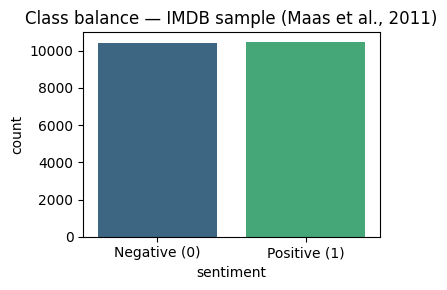

In [ ]:
bal = df["sentiment"].value_counts(normalize=True).rename({0: "neg", 1: "pos"})
print(bal.round(4))

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(x="sentiment", data=df, ax=ax,
              hue="sentiment", legend=False, palette="viridis")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Negative (0)", "Positive (1)"])
ax.set_title("Class balance — IMDB sample (Maas et al., 2011)")
plt.tight_layout(); plt.show()


### Review-length distribution



In [ ]:

df["n_words"] = df["review"].str.split().str.len()
df["n_chars"] = df["review"].str.len()

stats = df.groupby("sentiment")["n_words"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]).round(1)
stats.index = ["negative", "positive"]
print(stats)
print(f"\\n95th percentile of words: {df['n_words'].quantile(0.95):.0f}")
print(f"99th percentile of words: {df['n_words'].quantile(0.99):.0f}")
print(f"Maximum                : {df['n_words'].max()}")


            count   mean    std   min    50%    90%    95%    99%     max
negative  10441.0  231.1  167.2  10.0  174.0  442.0  577.0  895.6  1522.0
positive  10470.0  237.4  182.2  12.0  174.0  474.0  620.5  933.0  2470.0
\n95th percentile of words: 600
99th percentile of words: 919
Maximum                : 2470


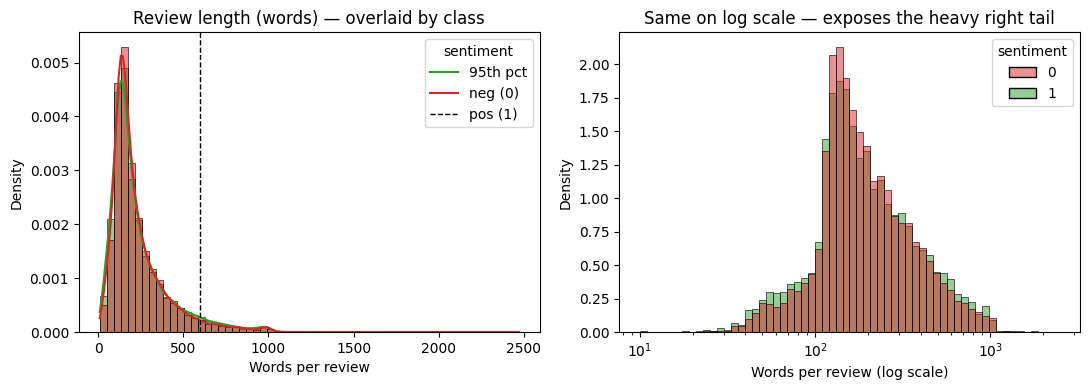

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="n_words", hue="sentiment", bins=60,
             kde=True, stat="density", common_norm=False,
             palette={0: "#d62728", 1: "#2ca02c"}, ax=axes[0])
axes[0].set_title("Review length (words) — overlaid by class")
axes[0].set_xlabel("Words per review"); axes[0].set_ylabel("Density")
axes[0].axvline(df["n_words"].quantile(0.95), color="black",
                linestyle="--", lw=1, label="95th pct")
axes[0].legend(title="sentiment", labels=["95th pct", "neg (0)", "pos (1)"])

sns.histplot(data=df, x="n_words", hue="sentiment", bins=60,
             log_scale=True, stat="density", common_norm=False,
             palette={0: "#d62728", 1: "#2ca02c"}, ax=axes[1])
axes[1].set_title("Same on log scale — exposes the heavy right tail")
axes[1].set_xlabel("Words per review (log scale)")
plt.tight_layout(); plt.show()


#### Review-length ECDF and character-count distribution


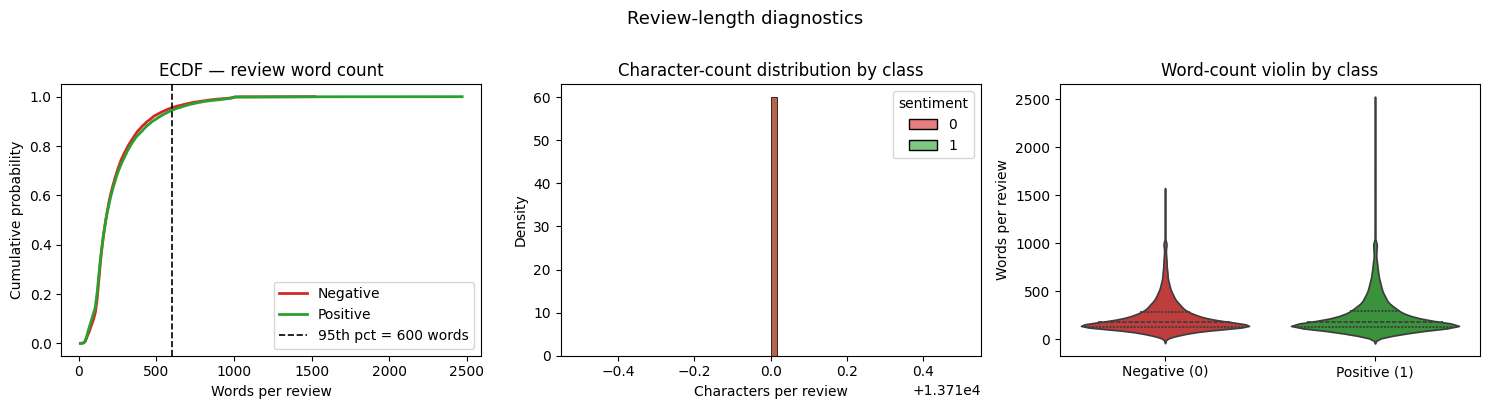

95th percentile word count: 600  →  use as MAX_LEN_A in Pipeline A


In [ ]:

from scipy.stats import ecdf as sp_ecdf

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, color in [(0, "#d62728"), (1, "#2ca02c")]:
    subset = df.loc[df.sentiment == label, "n_words"].values
    res = sp_ecdf(subset)
    x = np.sort(subset)
    axes[0].plot(x, res.cdf.evaluate(x),
                 color=color, lw=2,
                 label=f"{'Negative' if label==0 else 'Positive'}")
p95 = int(np.percentile(df["n_words"], 95))
axes[0].axvline(p95, ls="--", color="black", lw=1.2,
                label=f"95th pct = {p95} words")
axes[0].set_xlabel("Words per review"); axes[0].set_ylabel("Cumulative probability")
axes[0].set_title("ECDF — review word count"); axes[0].legend()


df["n_chars"] = df["review"].str.len()
sns.histplot(data=df, x="n_chars", hue="sentiment",
             bins=60, stat="density", common_norm=False,
             palette={0: "#d62728", 1: "#2ca02c"}, alpha=0.6, ax=axes[1])
axes[1].set_xlabel("Characters per review")
axes[1].set_title("Character-count distribution by class")


sns.violinplot(data=df, x="sentiment", y="n_words",
               palette={'0': "#d62728", '1': "#2ca02c"},
               inner="quartile", ax=axes[2])
axes[2].set_xticklabels(["Negative (0)", "Positive (1)"])
axes[2].set_xlabel(""); axes[2].set_ylabel("Words per review")
axes[2].set_title("Word-count violin by class")

plt.suptitle("Review-length diagnostics", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("fig_length_ecdf.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"95th percentile word count: {p95}  →  use as MAX_LEN_A in Pipeline A")

### Vocabulary statistics and most-frequent tokens

In [ ]:
STOPWORDS = set("""
    a an and are as at be been being but by could did do does doing for from
    had has have having he her hers him his i if in into is it its itself just
    me more my myself nor of on once only or other our ours ourselves out
    over own same she so some such than that the their theirs them themselves
    then there these they this those through to too under until up very was
    we were what when where which while who whom why will with you your yours
    yourself yourselves
""".split())
print(f"Stopword list size: {len(STOPWORDS)}")


Stopword list size: 96


In [ ]:
HTML_RE  = re.compile(r"<.*?>")
SPACE_RE = re.compile(r"\s+")
NONALPHA = re.compile(r"[^a-z'\s]")

def light_clean(text: str) -> str:
    text = html.unescape(text)
    text = HTML_RE.sub(" ", text)
    text = text.lower()
    text = NONALPHA.sub(" ", text)
    text = SPACE_RE.sub(" ", text).strip()
    return text

df["clean_light"] = df["review"].astype(str).apply(light_clean)
df["clean_light"].head(2).tolist()


["with all this stuff going down at the moment with mj i've started listening to his music watching the odd documentary here and there watched the wiz and watched moonwalker again maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent moonwalker is part biography part feature film which i remember going to see at the cinema when it was originally released some of it has subtle messages about mj's feeling towards the press and also the obvious message of drugs are bad m'kay visually impressive but of course this is all about michael jackson so unless you remotely like mj in anyway then you are going to hate this and find it boring some may call mj an egotist for consenting to the making of this movie but mj and most of his fans would say that he made it for the fans which if true is really nice of him the actual feature film bit when it finally starts is only on for minutes or 

In [ ]:

all_tokens = " ".join(df["clean_light"].sample(min(5000, len(df)),
                       random_state=STUDENT_ID)).split()
vocab_full = set(all_tokens)
vocab_nostop = set(t for t in all_tokens if t not in STOPWORDS)
print(f"Tokens (5k-row sample): {len(all_tokens):,}")
print(f"Vocabulary, full     : {len(vocab_full):,}")
print(f"Vocabulary, no stops : {len(vocab_nostop):,}")


Tokens (5k-row sample): 1,157,431
Vocabulary, full     : 41,811
Vocabulary, no stops : 41,715


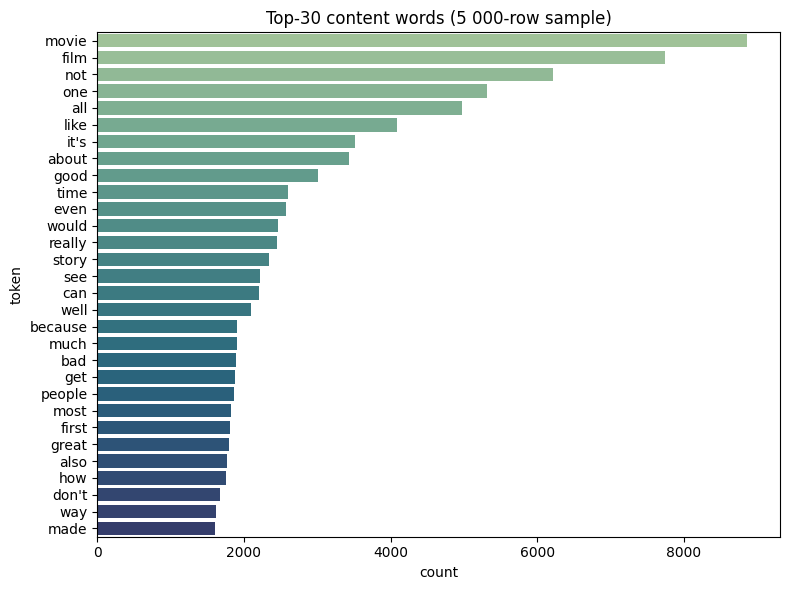

,token,count
0,movie,8866
1,film,7739
2,not,6218
3,one,5317
4,all,4980
5,like,4086
6,it's,3514
7,about,3428
8,good,3005
9,time,2604


In [ ]:

content_counter = Counter(t for t in all_tokens if t not in STOPWORDS and len(t) > 2)
top30 = content_counter.most_common(30)
top30_df = pd.DataFrame(top30, columns=["token", "count"])

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=top30_df, y="token", x="count", hue="token",
            palette="crest", legend=False, ax=ax)
ax.set_title("Top-30 content words (5 000-row sample)")
plt.tight_layout(); plt.show()
top30_df.head(15)


#### Word clouds — positive vs negative class

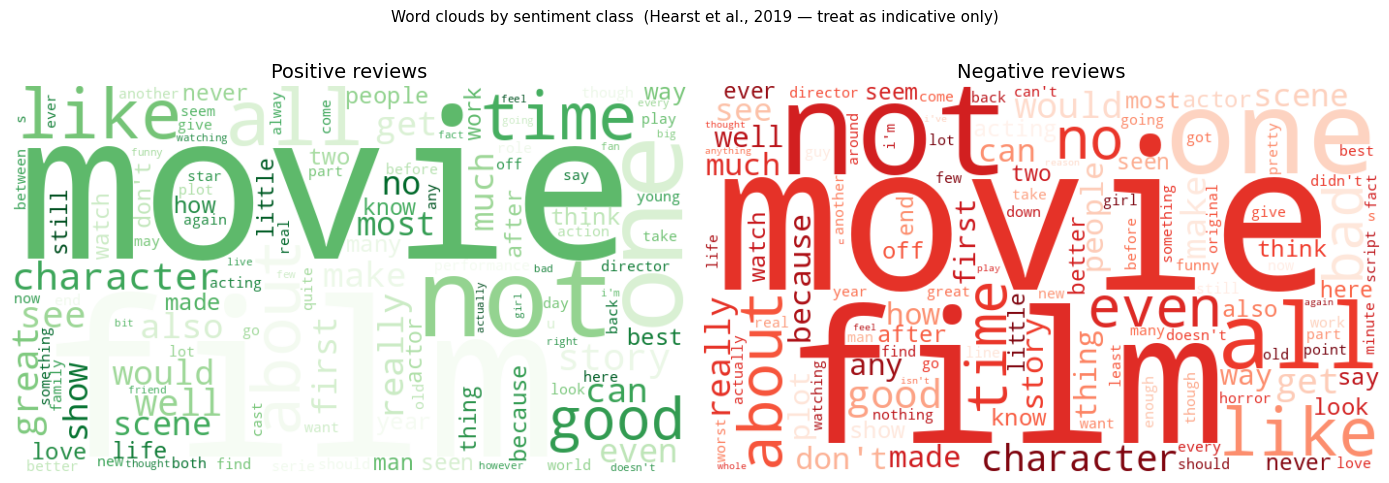

In [ ]:
try:
    from wordcloud import WordCloud
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "wordcloud", "-q"])
    from wordcloud import WordCloud

def make_wc_text(label):
    """Concatenate Pipeline-A tokens for one class."""
    return " ".join(df.loc[df.sentiment == label, "clean_light"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label, title, cmap in zip(
        axes, [1, 0],
        ["Positive reviews", "Negative reviews"],
        ["Greens", "Reds"]):
    wc = WordCloud(
        width=700, height=400,
        background_color="white",
        colormap=cmap,
        max_words=120,
        stopwords=STOPWORDS,
        random_state=STUDENT_ID,
        collocations=False,
    ).generate(make_wc_text(label))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(title, fontsize=14)

plt.suptitle("Word clouds by sentiment class  (Hearst et al., 2019 — treat as indicative only)",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig("fig_wordclouds.png", dpi=150, bbox_inches="tight")
plt.show()

### Class-discriminative tokens



In [ ]:
def log_odds_dirichlet(counts_a, counts_b, prior=None):

    vocab = set(counts_a) | set(counts_b)
    if prior is None:
        prior = Counter()
        for v in vocab:
            prior[v] = counts_a.get(v, 0) + counts_b.get(v, 0)
    n_a = sum(counts_a.values())
    n_b = sum(counts_b.values())
    n_p = sum(prior.values())
    out = {}
    for w in vocab:
        a = counts_a.get(w, 0); b = counts_b.get(w, 0); p = prior.get(w, 0)

        l_a = math.log((a + p) / (n_a + n_p - a - p + 1e-12))
        l_b = math.log((b + p) / (n_b + n_p - b - p + 1e-12))
        delta = l_a - l_b
        var = 1.0 / (a + p + 1e-12) + 1.0 / (b + p + 1e-12)
        out[w] = delta / math.sqrt(var)
    return out

pos_text = " ".join(df.loc[df.sentiment == 1, "clean_light"]
                      .sample(min(2500, (df.sentiment == 1).sum()),
                              random_state=STUDENT_ID)).split()
neg_text = " ".join(df.loc[df.sentiment == 0, "clean_light"]
                      .sample(min(2500, (df.sentiment == 0).sum()),
                              random_state=STUDENT_ID)).split()
pos_c = Counter(t for t in pos_text if t not in STOPWORDS and len(t) > 2)
neg_c = Counter(t for t in neg_text if t not in STOPWORDS and len(t) > 2)
zscores = log_odds_dirichlet(pos_c, neg_c)

freq_floor = 30
top_pos = sorted([(w, z) for w, z in zscores.items()
                  if pos_c[w] + neg_c[w] >= freq_floor],
                 key=lambda x: -x[1])[:15]
top_neg = sorted([(w, z) for w, z in zscores.items()
                  if pos_c[w] + neg_c[w] >= freq_floor],
                 key=lambda x:  x[1])[:15]
print("Most positive-leaning tokens (z, freq):")
for w, z in top_pos:
    print(f"  {w:>15s}  z = {z:+5.1f}  (pos={pos_c[w]}, neg={neg_c[w]})")
print("\\nMost negative-leaning tokens:")
for w, z in top_neg:
    print(f"  {w:>15s}  z = {z:+5.1f}  (pos={pos_c[w]}, neg={neg_c[w]})")


Most positive-leaning tokens (z, freq):
            great  z = +10.1  (pos=1322, neg=549)
        excellent  z =  +7.4  (pos=342, neg=75)
             love  z =  +7.0  (pos=834, neg=396)
             best  z =  +6.9  (pos=877, neg=431)
        wonderful  z =  +6.6  (pos=270, neg=58)
          perfect  z =  +5.8  (pos=256, neg=69)
             well  z =  +5.7  (pos=1328, neg=844)
          amazing  z =  +5.6  (pos=228, neg=60)
            loved  z =  +5.6  (pos=226, neg=59)
             also  z =  +5.3  (pos=1131, neg=721)
        beautiful  z =  +5.0  (pos=312, neg=126)
           family  z =  +4.6  (pos=403, neg=200)
           superb  z =  +4.6  (pos=123, neg=24)
     performances  z =  +4.6  (pos=261, neg=105)
            today  z =  +4.6  (pos=141, neg=34)
\nMost negative-leaning tokens:
              bad  z = -13.5  (pos=418, neg=1399)
            worst  z = -11.4  (pos=47, neg=514)
            movie  z =  -8.8  (pos=3591, neg=4890)
            waste  z =  -8.8  (pos=16, neg=278)


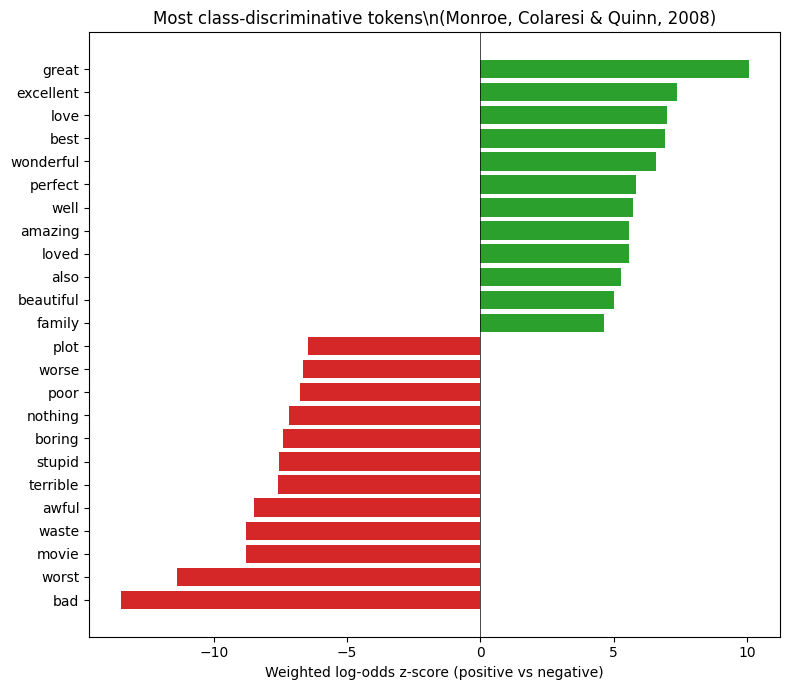

In [ ]:

top_pos_df = pd.DataFrame(top_pos[:12], columns=["token", "z"])
top_neg_df = pd.DataFrame(top_neg[:12], columns=["token", "z"])
plot_df = pd.concat([top_pos_df.assign(class_="positive"),
                     top_neg_df.assign(class_="negative")])
plot_df["abs_z"] = plot_df["z"].abs()
plot_df = plot_df.sort_values("z")

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#2ca02c" if c == "positive" else "#d62728" for c in plot_df["class_"]]
ax.barh(plot_df["token"], plot_df["z"], color=colors)
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("Weighted log-odds z-score (positive vs negative)")
ax.set_title("Most class-discriminative tokens\\n(Monroe, Colaresi & Quinn, 2008)")
plt.tight_layout(); plt.show()


###  capturing negation and intensifiers



#### Readability and lexical diversity — five linguistic style metrics


In [ ]:

try:
    import textstat
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "textstat"],
                   check=True)
    import textstat

def _ttr(text):
    """Type-Token Ratio (Templin, 1957). Length-sensitive; mostly for comparison."""
    toks = text.split()
    return len(set(toks)) / max(len(toks), 1)

def _mattr(text, window=100):
    """Moving-Average Type-Token Ratio (Covington & McFall, 2010).
    Length-corrected lexical diversity; recommended over raw TTR."""
    toks = text.split()
    if len(toks) <= window:
        return _ttr(text)
    ttrs = []
    for i in range(len(toks) - window + 1):
        chunk = toks[i:i + window]
        ttrs.append(len(set(chunk)) / window)
    return float(np.mean(ttrs))


N_SAMPLE = min(5000, len(df))
sample = df.sample(N_SAMPLE, random_state=STUDENT_ID).copy()

print(f"Computing 5 readability/lexdiv metrics on {N_SAMPLE} reviews…")
sample["FleschKincaid"] = sample["review"].apply(textstat.flesch_kincaid_grade)
sample["FOG"]           = sample["review"].apply(textstat.gunning_fog)
sample["DaleChall"]     = sample["review"].apply(textstat.dale_chall_readability_score)
sample["TTR"]           = sample["clean_light"].apply(_ttr)
sample["MATTR"]         = sample["clean_light"].apply(_mattr)
print("Done.")


metric_long = sample.melt(
    id_vars=["sentiment"],
    value_vars=["FleschKincaid", "FOG", "DaleChall", "TTR", "MATTR"],
    var_name="metric", value_name="value")
metric_long["sentiment_lbl"] = metric_long["sentiment"].map({0: "negative", 1: "positive"})

summary = (metric_long
           .groupby(["metric", "sentiment_lbl"])["value"]
           .agg(["mean", "median", "std"])
           .round(3)
           .reset_index())
print("\nMetric summary by class:")
print(summary.to_string(index=False))


Computing 5 readability/lexdiv metrics on 5000 reviews…
Done.

Metric summary by class:
       metric sentiment_lbl   mean  median   std
    DaleChall      negative  8.957   8.900 1.206
    DaleChall      positive  9.212   9.169 1.245
          FOG      negative 10.816  10.333 4.458
          FOG      positive 11.613  11.167 3.700
FleschKincaid      negative  8.654   8.170 4.238
FleschKincaid      positive  9.307   8.826 3.474
        MATTR      negative  0.747   0.748 0.050
        MATTR      positive  0.740   0.740 0.053
          TTR      negative  0.657   0.658 0.091
          TTR      positive  0.651   0.652 0.094


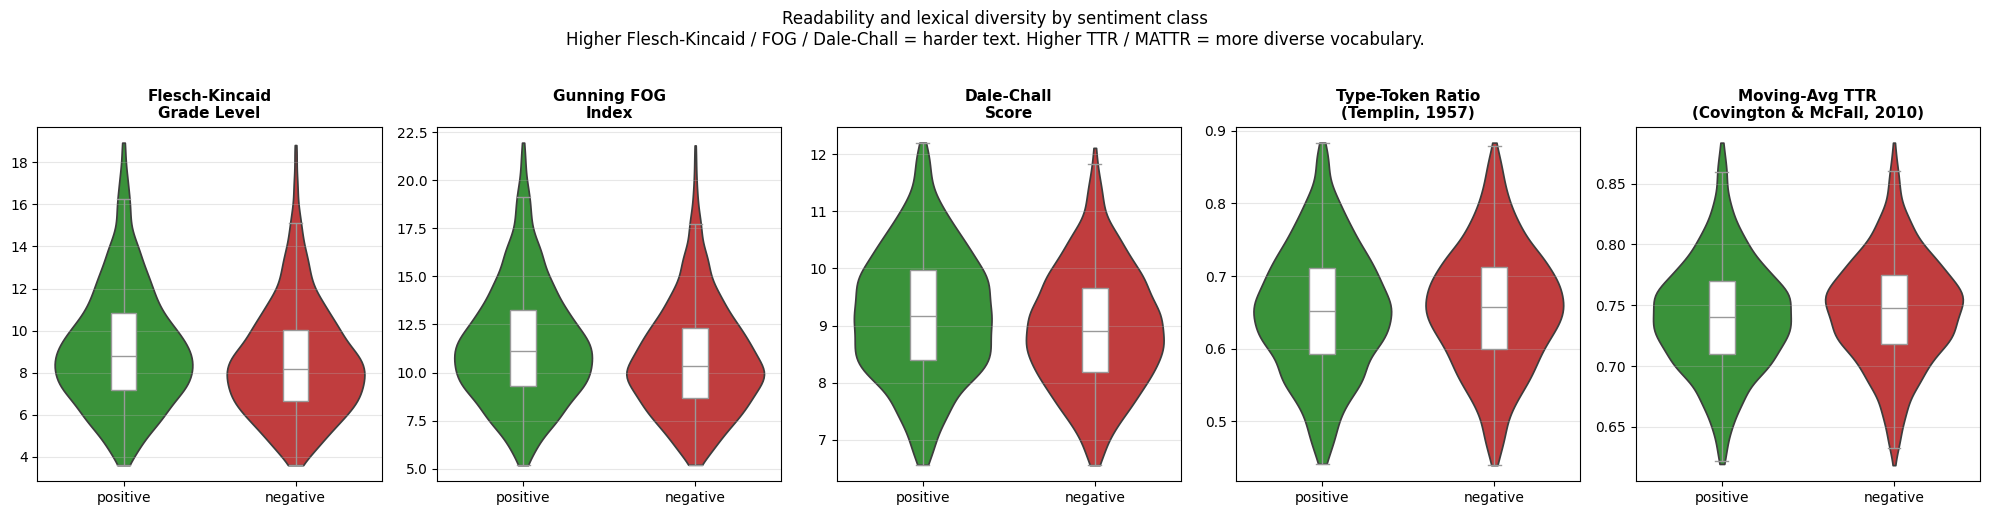

In [ ]:

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=False)
metrics = ["FleschKincaid", "FOG", "DaleChall", "TTR", "MATTR"]
titles  = ["Flesch-Kincaid\nGrade Level", "Gunning FOG\nIndex",
           "Dale-Chall\nScore", "Type-Token Ratio\n(Templin, 1957)",
           "Moving-Avg TTR\n(Covington & McFall, 2010)"]
palette = {"negative": "#d62728", "positive": "#2ca02c"}

for ax, m, t in zip(axes, metrics, titles):
    sub = metric_long[metric_long["metric"] == m]
    lo, hi = np.percentile(sub["value"], [1, 99])
    sub = sub[(sub["value"] >= lo) & (sub["value"] <= hi)]
    sns.violinplot(data=sub, x="sentiment_lbl", y="value",
                   hue="sentiment_lbl", palette=palette, ax=ax,
                   inner=None, cut=0, legend=False)
    sns.boxplot(data=sub, x="sentiment_lbl", y="value",
                width=0.15, color="white", ax=ax,
                fliersize=0, linewidth=1.0)
    ax.set_title(t, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Readability and lexical diversity by sentiment class\n"
             "Higher Flesch-Kincaid / FOG / Dale-Chall = harder text. "
             "Higher TTR / MATTR = more diverse vocabulary.",
             fontsize=12, y=1.02)
plt.tight_layout(); plt.show()



###  Two preprocessing pipelines


In [ ]:

CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "won't": "will not", "wouldn't": "would not", "shouldn't": "should not",
    "couldn't": "could not", "can't": "can not", "isn't": "is not",
    "wasn't": "was not", "aren't": "are not", "weren't": "were not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "i'm": "i am", "i've": "i have", "i'd": "i would", "i'll": "i will",
    "you're": "you are", "you've": "you have", "you'll": "you will",
    "they're": "they are", "they've": "they have", "they'll": "they will",
    "we're": "we are", "we've": "we have", "we'll": "we will",
    "it's": "it is", "that's": "that is", "what's": "what is",
    "there's": "there is", "let's": "let us",
}
URL_RE = re.compile(r"https?://\S+|www\.\S+")
NUM_RE = re.compile(r"\b\d+(?:[.,]\d+)*\b")

def preprocess_A(text: str) -> str:
    text = html.unescape(str(text))
    text = HTML_RE.sub(" ", text)
    text = text.lower()
    for c, e in CONTRACTIONS.items():
        text = text.replace(c, e)
    text = URL_RE.sub(" <url> ", text)
    text = NUM_RE.sub(" <num> ", text)
    text = re.sub(r"[^a-z'<>\s]", " ", text)
    toks = [t for t in text.split() if t and (t not in STOPWORDS or t in {"not","no","never","nor"})]
    return " ".join(toks)

def preprocess_B(text: str) -> str:
    text = html.unescape(str(text))
    text = HTML_RE.sub(" ", text)
    text = SPACE_RE.sub(" ", text).strip()
    return text


df["text_A"] = df["review"].apply(preprocess_A)
df["text_B"] = df["review"].apply(preprocess_B)

print("===== ORIGINAL =====")
print(df["review"].iloc[0][:400], "...")
print("\\n===== PIPELINE A (GloVe-style) =====")
print(df["text_A"].iloc[0][:400], "...")
print("\\n===== PIPELINE B (BERT-style) =====")
print(df["text_B"].iloc[0][:400], "...")


===== ORIGINAL =====
"With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film whi ...
\n===== PIPELINE A (GloVe-style) =====
all stuff going down moment mj started listening music watching odd documentary here watched wiz watched moonwalker again maybe want get certain insight guy thought really cool eighties maybe make mind whether guilty innocent moonwalker part biography part feature film remember going see cinema originally released subtle messages about mj's feeling towards press also obvious message drugs bad m'ka ...
\n===== PIPELINE B (BERT-style) =====
"With all this stuff going down at the moment with MJ i've started listening to his music, w

In [ ]:

def vocab_and_length(series):
    toks = " ".join(series.sample(min(5000, len(series)),
                                  random_state=STUDENT_ID)).split()
    return len(set(toks)), np.mean([len(s.split()) for s in series])

v_raw, l_raw = vocab_and_length(df["review"].apply(light_clean))
v_A,   l_A   = vocab_and_length(df["text_A"])
v_B,   l_B   = vocab_and_length(df["text_B"])

summary = pd.DataFrame({
    "Vocab (sample)": [v_raw, v_A, v_B],
    "Mean #words":    [l_raw, l_A, l_B],
}, index=["After light cleaning", "Pipeline A", "Pipeline B"])
print(summary.round(1))


                      Vocab (sample)  Mean #words
After light cleaning           41811        232.8
Pipeline A                     41645        131.3
Pipeline B                     99043        232.0


#### UMAP projection of review-level embeddings


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT encode:   0%|          | 0/94 [00:00<?, ?it/s]

DistilBERT document embeddings shape: (3000, 768)


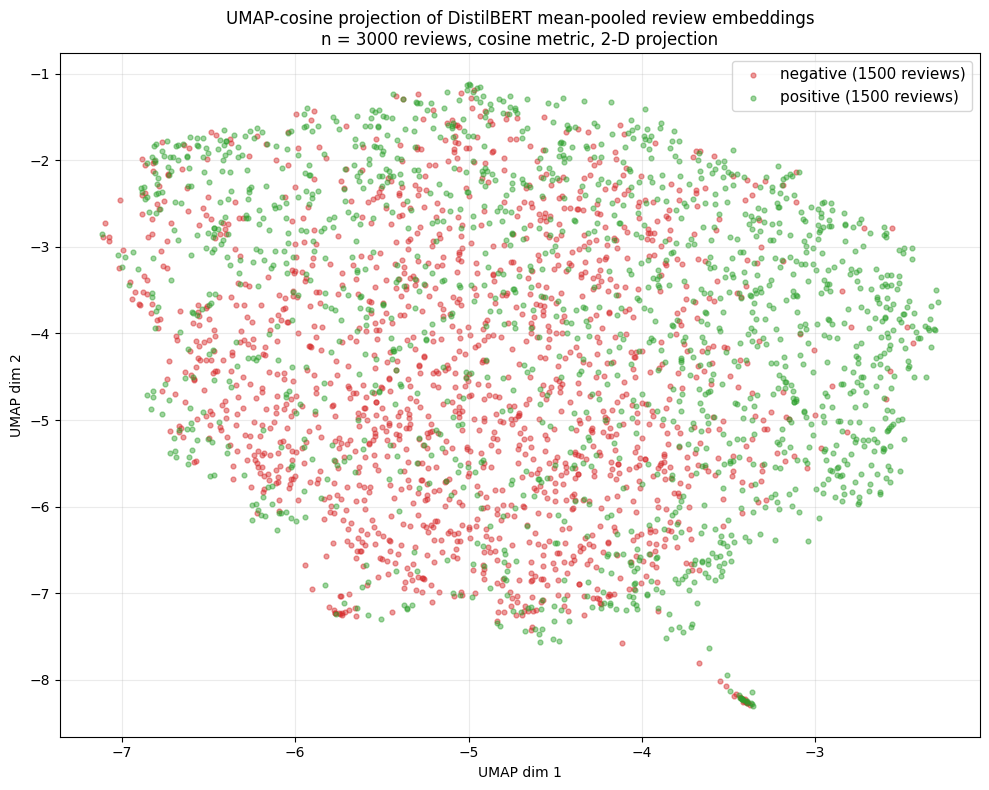

In [ ]:

try:
    import umap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "umap-learn"],
                   check=True)
    import umap


from transformers import AutoTokenizer, AutoModel
_tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
_bert = AutoModel.from_pretrained("distilbert-base-uncased").to(DEVICE).eval()

N_UMAP = 3000
samp = (df.groupby("sentiment", group_keys=False)
          .apply(lambda x: x.sample(min(len(x), N_UMAP // 2),
                                    random_state=STUDENT_ID))
          .reset_index(drop=True))

@torch.no_grad()
def _mean_pool(texts, batch_size=32):
    out = []
    for i in tqdm(range(0, len(texts), batch_size),
                  desc="DistilBERT encode", leave=False):
        batch = texts[i:i + batch_size]
        enc = _tok(batch, padding=True, truncation=True, max_length=256,
                   return_tensors="pt").to(DEVICE)
        h = _bert(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pooled = (h * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        out.append(pooled.cpu().numpy())
    return np.vstack(out)

doc_emb = _mean_pool(samp["text_B"].tolist())
print(f"DistilBERT document embeddings shape: {doc_emb.shape}")

# Free the encoder
del _bert; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

reducer = umap.UMAP(n_components=2, n_neighbors=25, min_dist=0.05,
                    metric="cosine", random_state=STUDENT_ID)
doc_2d = reducer.fit_transform(doc_emb)

fig, ax = plt.subplots(figsize=(10, 8))
palette = {0: "#d62728", 1: "#2ca02c"}
for cls, lbl in [(0, "negative"), (1, "positive")]:
    m = samp["sentiment"].values == cls
    ax.scatter(doc_2d[m, 0], doc_2d[m, 1], s=12, alpha=0.45,
               color=palette[cls], label=f"{lbl} ({m.sum()} reviews)")
ax.set_title("UMAP-cosine projection of DistilBERT mean-pooled review embeddings\n"
             "n = {} reviews, cosine metric, 2-D projection".format(len(samp)),
             fontsize=12)
ax.set_xlabel("UMAP dim 1"); ax.set_ylabel("UMAP dim 2")
ax.legend(loc="best", fontsize=11); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()



#### t-SNE of top class-discriminative tokens in GloVe space

Loading glove-wiki-gigaword-200 (cached after first run)...
[==================================================] 100.0% 252.1/252.1MB downloaded
GloVe dimension: 200
Vocab size     : 400,000


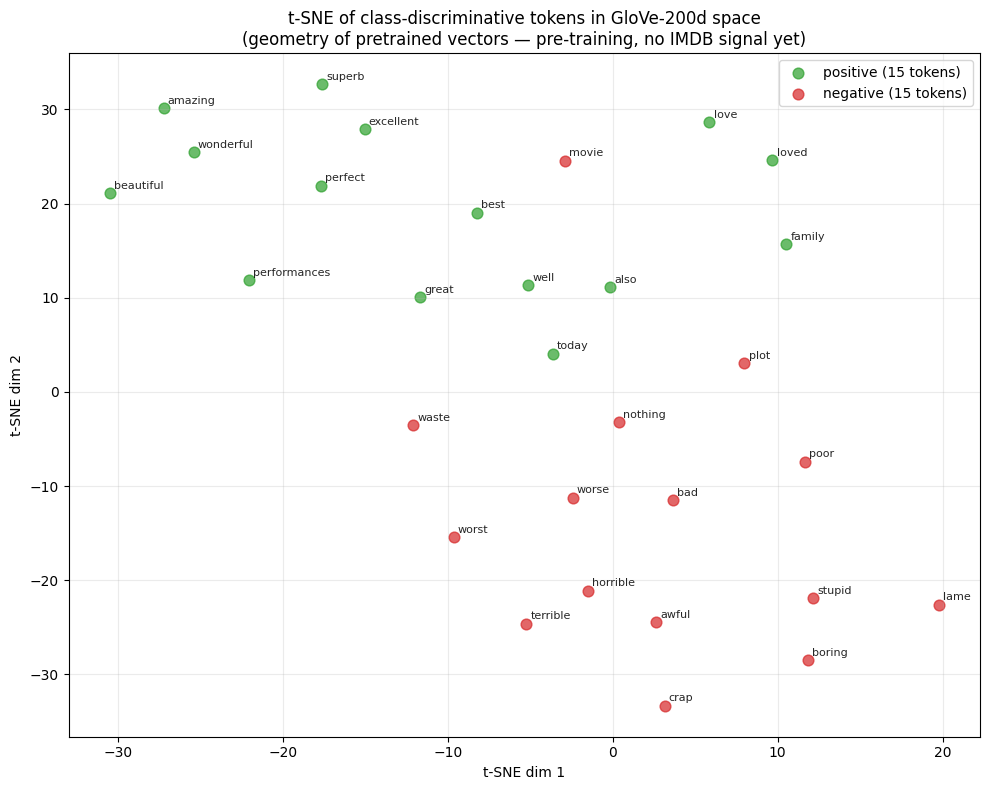

In [ ]:
# t-SNE of class-discriminative tokens — runs without GloVe if available,
# else loads it ad-hoc (smaller than the modelling-stage load)
from sklearn.manifold import TSNE
#loading glove
!pip install gensim
import gensim.downloader as api
print("Loading glove-wiki-gigaword-200 (cached after first run)...")

glove = api.load("glove-wiki-gigaword-200")
EMB_DIM = 200
print(f"GloVe dimension: {EMB_DIM}")
print(f"Vocab size     : {len(glove.key_to_index):,}")

pos_tokens = [t for t, _ in top_pos[:40]]
neg_tokens = [t for t, _ in top_neg[:40]]
in_glove   = lambda t: t in glove.key_to_index
all_tok    = ([t for t in pos_tokens if in_glove(t)] +
              [t for t in neg_tokens if in_glove(t)])
labels = (["positive"] * sum(in_glove(t) for t in pos_tokens) +
          ["negative"] * sum(in_glove(t) for t in neg_tokens))

X = np.vstack([glove[t] for t in all_tok])
perp = max(5, min(15, (len(all_tok) - 1) // 3))
emb2 = TSNE(n_components=2, perplexity=perp, learning_rate="auto",
            init="pca", random_state=STUDENT_ID).fit_transform(X)

fig, ax = plt.subplots(figsize=(10, 8))
palette = {"positive": "#2ca02c", "negative": "#d62728"}
for label in ("positive", "negative"):
    m = np.array(labels) == label
    ax.scatter(emb2[m, 0], emb2[m, 1], s=60, alpha=0.7,
               color=palette[label], label=f"{label} ({m.sum()} tokens)")
for i, t in enumerate(all_tok):
    ax.annotate(t, (emb2[i, 0], emb2[i, 1]), fontsize=8, alpha=0.85,
                xytext=(3, 3), textcoords="offset points")

ax.set_title("t-SNE of class-discriminative tokens in GloVe-200d space\n"
             "(geometry of pretrained vectors — pre-training, no IMDB signal yet)",
             fontsize=12)
ax.set_xlabel("t-SNE dim 1"); ax.set_ylabel("t-SNE dim 2")
ax.legend(loc="best"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


#### Ridgeline + beeswarm — review length distribution by class



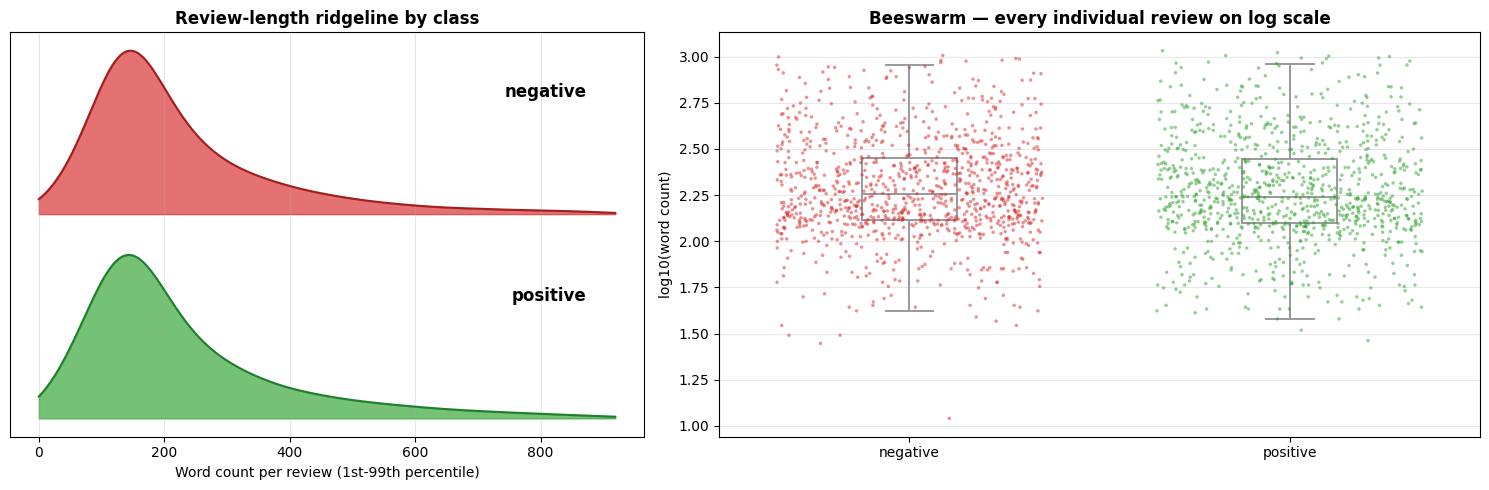

In [ ]:
# Ridgeline (joyplot) + beeswarm of word counts by sentiment.
# Pure matplotlib + seaborn — avoids the ggridges dependency.

fig, axes = plt.subplots(1, 2, figsize=(15, 5),
                         gridspec_kw={"width_ratios": [1.0, 1.2]})

ax = axes[0]
xlim = (0, int(np.percentile(df["n_words"], 99)))
xs = np.linspace(*xlim, 400)
for i, cls in enumerate([0, 1]):
    sub = df.loc[df["sentiment"] == cls, "n_words"]
    sub = sub[sub <= xlim[1]]
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(sub, bw_method=0.3)
    y   = kde(xs)
    y   = y / y.max() * 0.8
    base = 1 - i
    ax.fill_between(xs, base, base + y, alpha=0.65,
                    color={0: "#d62728", 1: "#2ca02c"}[cls])
    ax.plot(xs, base + y, color={0: "#a02020", 1: "#1f7f2e"}[cls], lw=1.5)
    ax.text(xs[-1] * 0.95, base + 0.6,
            {0: "negative", 1: "positive"}[cls],
            ha="right", va="center", fontsize=12, fontweight="bold")
ax.set_yticks([])
ax.set_xlabel("Word count per review (1st-99th percentile)")
ax.set_title("Review-length ridgeline by class", fontweight="bold")
ax.grid(axis="x", alpha=0.3)

ax = axes[1]
samp = df.sample(min(2000, len(df)), random_state=STUDENT_ID).copy()
samp["log_words"] = np.log10(samp["n_words"] + 1)
sns.stripplot(data=samp, x="sentiment", y="log_words",
              hue="sentiment", palette={0: "#d62728", 1: "#2ca02c"},
              size=2.5, alpha=0.5, jitter=0.35, ax=ax, legend=False)
sns.boxplot(data=samp, x="sentiment", y="log_words",
            width=0.25, color="white", fliersize=0, linewidth=1.4,
            ax=ax)
ax.set_xticklabels(["negative", "positive"])
ax.set_xlabel(""); ax.set_ylabel("log10(word count)")
ax.set_title("Beeswarm — every individual review on log scale",
             fontweight="bold")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout(); plt.show()


#### Class-centroid cosine similarity


Centroid cosine similarity matrix:
          negative  positive
negative    1.0000    0.9209
positive    0.9209    1.0000

Neg ↔ Pos centroid cosine: 0.9209
Interpretation: the two classes share substantial vocabulary (both write about films) but the 8% that differs is the sentiment signal the models exploit.


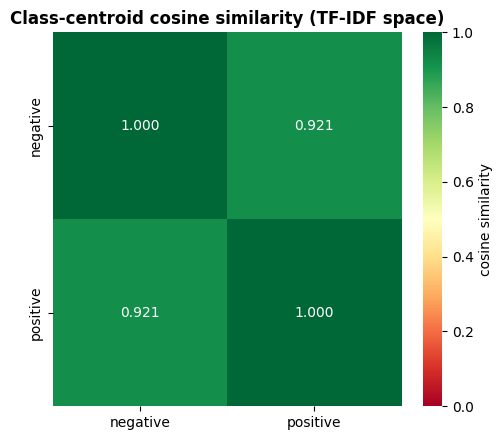

In [ ]:


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Light TF-IDF on the cleaned text (Pipeline A)
vec_centroid = TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                               sublinear_tf=True, min_df=3)
X_tfidf = vec_centroid.fit_transform(df["text_A"])

cls_centroids = {}
for cls in [0, 1]:
    mask = (df["sentiment"] == cls).values
    cls_centroids[cls] = X_tfidf[mask].mean(axis=0)

mat = np.vstack([np.asarray(cls_centroids[c]).ravel() for c in [0, 1]])
sim = cosine_similarity(mat)
print("Centroid cosine similarity matrix:")
print(pd.DataFrame(sim, index=["negative", "positive"],
                   columns=["negative", "positive"]).round(4))
print(f"\nNeg ↔ Pos centroid cosine: {sim[0, 1]:.4f}")
print(f"Interpretation: the two classes share substantial vocabulary "
      f"(both write about films) but the {1 - sim[0, 1]:.0%} that differs "
      f"is the sentiment signal the models exploit.")

# Visualise as a heatmap
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(sim, annot=True, fmt=".3f", cmap="RdYlGn",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"],
            vmin=0, vmax=1, cbar_kws={"label": "cosine similarity"}, ax=ax)
ax.set_title("Class-centroid cosine similarity (TF-IDF space)",
             fontweight="bold")
plt.tight_layout(); plt.show()


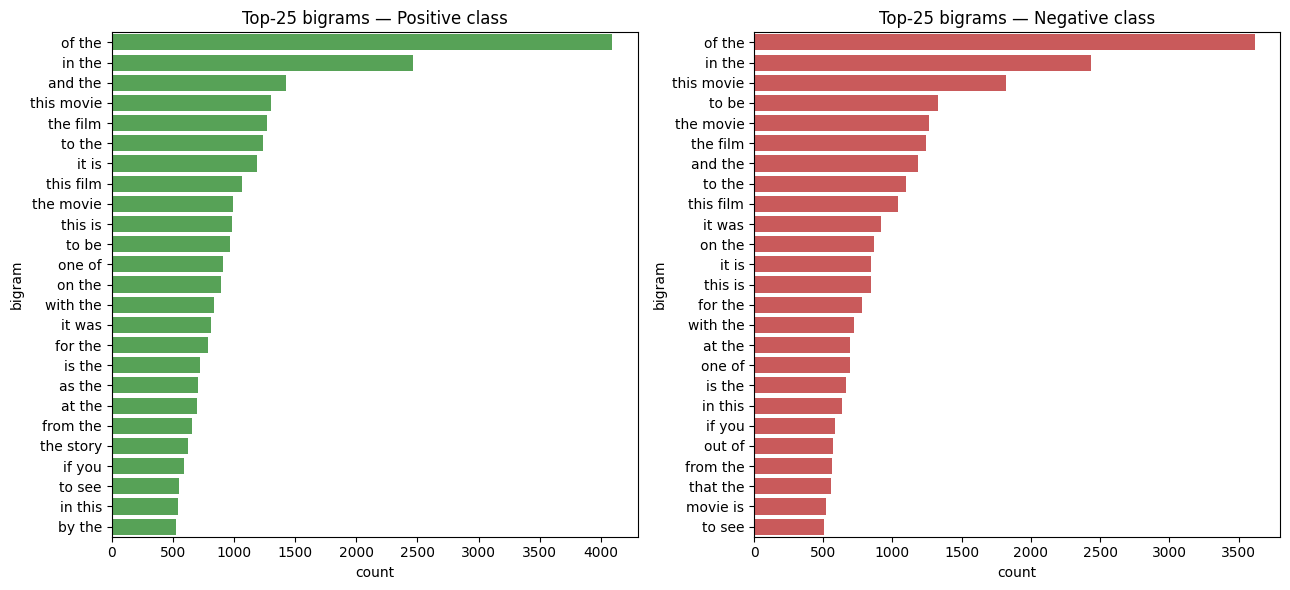

In [ ]:
def bigrams(tokens):
    return zip(tokens, tokens[1:])

def gather_bigrams(class_label, k=25):
    sub = df.loc[df.sentiment == class_label, "clean_light"].sample(
        min(2500, (df.sentiment == class_label).sum()),
        random_state=STUDENT_ID)
    bgs = Counter()
    for t in sub:
        toks = [w for w in t.split() if len(w) > 1]
        bgs.update(" ".join(b) for b in bigrams(toks))
    return bgs.most_common(k)

bg_pos = gather_bigrams(1)
bg_neg = gather_bigrams(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, data, ttl, color in zip(axes, [bg_pos, bg_neg],
                                 ["Positive class", "Negative class"],
                                 ["#2ca02c", "#d62728"]):
    bdf = pd.DataFrame(data, columns=["bigram", "count"])
    sns.barplot(data=bdf, y="bigram", x="count", color=color,
                ax=ax, alpha=0.85)
    ax.set_title(f"Top-25 bigrams — {ttl}")
plt.tight_layout(); plt.show()


#### Pipeline A — lemmatization enhancement and VADER sentiment features


Recomputing text_A with lemmatization — this takes ~30 s ...


  0%|          | 0/20911 [00:00<?, ?it/s]

Computing VADER scores ...


  0%|          | 0/20911 [00:00<?, ?it/s]


VADER compound mean by class:
sentiment
0   -0.0584
1    0.6675
Name: vader_compound, dtype: float64


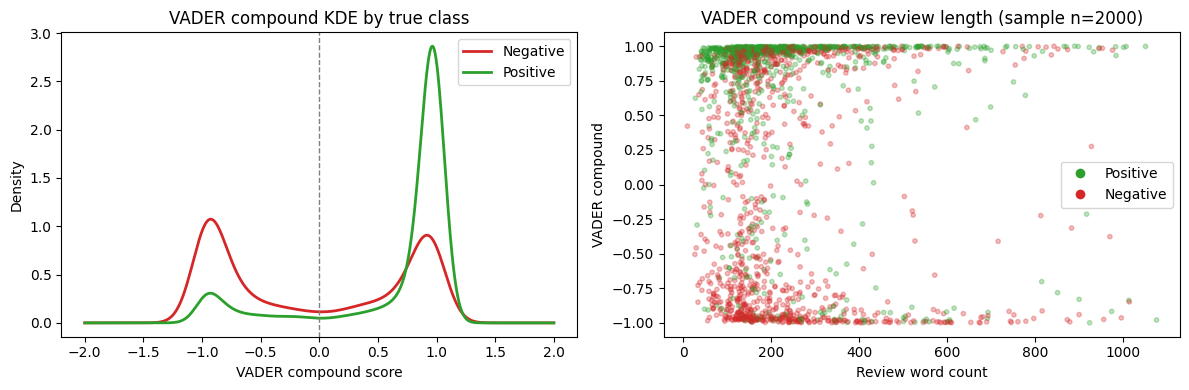

In [ ]:
import nltk
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.stem import WordNetLemmatizer
from tqdm.auto import tqdm
tqdm.pandas() 

try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install",
                    "vaderSentiment", "-q"])
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

_lemmatizer = WordNetLemmatizer()
_vader      = SentimentIntensityAnalyzer()

def preprocess_A_v2(text: str) -> str:
    """Pipeline A with lemmatization added."""
    text = html.unescape(str(text))
    text = HTML_RE.sub(" ", text)
    text = text.lower()
    for c, e in CONTRACTIONS.items():
        text = text.replace(c, e)
    text = URL_RE.sub(" <url> ", text)
    text = NUM_RE.sub(" <num> ", text)
    text = re.sub(r"[^a-z'<>]\s", " ", text)
    toks = [t for t in text.split()
            if t and (t not in STOPWORDS or t in {"not", "no", "never", "nor"})]
    toks = [_lemmatizer.lemmatize(t) if not t.startswith("<") else t
            for t in toks]
    return " ".join(toks)

print("Recomputing text_A with lemmatization — this takes ~30 s ...")
df["text_A"] = df["review"].progress_apply(preprocess_A_v2)


print("Computing VADER scores ...")
vader_scores = df["review"].progress_apply(
    lambda t: _vader.polarity_scores(t[:3000]))  
df["vader_pos"]      = vader_scores.apply(lambda d: d["pos"])
df["vader_neg"]      = vader_scores.apply(lambda d: d["neg"])
df["vader_neu"]      = vader_scores.apply(lambda d: d["neu"])
df["vader_compound"] = vader_scores.apply(lambda d: d["compound"])

# Quick sanity VADER compound should separate classes
print("\nVADER compound mean by class:")
print(df.groupby("sentiment")["vader_compound"].mean().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Density plot of compound score
for label, color, name in [(0, "#d62728", "Negative"), (1, "#2ca02c", "Positive")]:
    vals = df.loc[df.sentiment == label, "vader_compound"]
    vals.plot.kde(ax=axes[0], color=color, lw=2, label=name)
axes[0].axvline(0, ls="--", color="grey", lw=1)
axes[0].set_xlabel("VADER compound score")
axes[0].set_title("VADER compound KDE by true class")
axes[0].legend()

# Scatter: VADER compound vs n_words, coloured by label
scatter_df = df.sample(2000, random_state=STUDENT_ID)
axes[1].scatter(scatter_df["n_words"],
                scatter_df["vader_compound"],
                c=scatter_df["sentiment"].map({0: "#d62728", 1: "#2ca02c"}),
                alpha=0.3, s=10)
axes[1].set_xlabel("Review word count")
axes[1].set_ylabel("VADER compound")
axes[1].set_title("VADER compound vs review length (sample n=2000)")
from matplotlib.lines import Line2D
axes[1].legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#2ca02c', ms=8, label='Positive'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#d62728', ms=8, label='Negative'),
])

plt.tight_layout()
plt.savefig("fig_vader_eda.png", dpi=150)
plt.show()

####  Preprocessing pipeline comparison — vocabulary and length

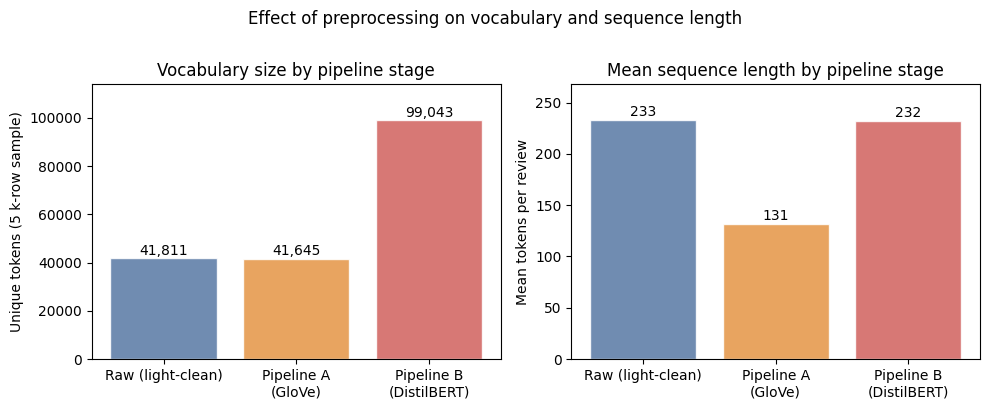

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

stages   = ["Raw (light-clean)", "Pipeline A\n(GloVe)", "Pipeline B\n(DistilBERT)"]
vocabs   = [v_raw, v_A, v_B]
lengths  = [l_raw, l_A, l_B]
colors   = ["#5778a4", "#e49444", "#d1615d"]

# Vocab size
bars = axes[0].bar(stages, vocabs, color=colors, alpha=0.85, edgecolor="white")
for b, v in zip(bars, vocabs):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 200,
                 f"{v:,}", ha="center", va="bottom", fontsize=10)
axes[0].set_ylabel("Unique tokens (5 k-row sample)")
axes[0].set_title("Vocabulary size by pipeline stage")
axes[0].set_ylim(0, max(vocabs) * 1.15)

# Mean review length
bars2 = axes[1].bar(stages, lengths, color=colors, alpha=0.85, edgecolor="white")
for b, v in zip(bars2, lengths):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 1,
                 f"{v:.0f}", ha="center", va="bottom", fontsize=10)
axes[1].set_ylabel("Mean tokens per review")
axes[1].set_title("Mean sequence length by pipeline stage")
axes[1].set_ylim(0, max(lengths) * 1.15)

plt.suptitle("Effect of preprocessing on vocabulary and sequence length",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("fig_pipeline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

###  Train / validation / test split



In [ ]:
from sklearn.model_selection import train_test_split

# 80/10/10 stratified
df_trainval, df_test = train_test_split(
    df, test_size=0.10, stratify=df["sentiment"], random_state=STUDENT_ID)
df_train, df_val = train_test_split(
    df_trainval, test_size=1/9, stratify=df_trainval["sentiment"],
    random_state=STUDENT_ID)
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print(f"Train: {len(df_train):>5d}  pos={df_train.sentiment.mean():.3f}")
print(f"Val  : {len(df_val):>5d}  pos={df_val.sentiment.mean():.3f}")
print(f"Test : {len(df_test):>5d}  pos={df_test.sentiment.mean():.3f}")

# Persist the splits so re-runs are reproducible
SPLITS_DIR = Path("splits"); SPLITS_DIR.mkdir(exist_ok=True)
df_train[["id","sentiment","text_A","text_B"]].to_parquet(SPLITS_DIR / "train.parquet")
df_val  [["id","sentiment","text_A","text_B"]].to_parquet(SPLITS_DIR / "val.parquet")
df_test [["id","sentiment","text_A","text_B"]].to_parquet(SPLITS_DIR / "test.parquet")
print("Splits saved to ./splits/")


Train: 16728  pos=0.501
Val  :  2091  pos=0.501
Test :  2092  pos=0.500
Splits saved to ./splits/


##  Q3 


###  Sanity baseline — TF-IDF + Logistic Regression



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

vec = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2),
                      min_df=5, sublinear_tf=True)
Xtr_tfidf = vec.fit_transform(df_train["text_A"])
Xva_tfidf = vec.transform(df_val["text_A"])
Xte_tfidf = vec.transform(df_test["text_A"])

clf = LogisticRegression(C=4.0, max_iter=2000,
                         solver="liblinear", random_state=STUDENT_ID)
clf.fit(Xtr_tfidf, df_train["sentiment"])
p_te = clf.predict_proba(Xte_tfidf)[:, 1]
print(f"Baseline TF-IDF + LR — Test Acc: {accuracy_score(df_test.sentiment, p_te > 0.5):.4f}")
print(f"Baseline TF-IDF + LR — Test AUC: {roc_auc_score(df_test.sentiment, p_te):.4f}")


predictions = {"Baseline TF-IDF + LR": p_te}


Baseline TF-IDF + LR — Test Acc: 0.9097
Baseline TF-IDF + LR — Test AUC: 0.9709


###  Embedding A — load GloVe and build the tokenizer



In [ ]:
# Build a tokenizer/vocabulary from the TRAIN set ONLY (no leakage)
from collections import Counter as _C
MIN_FREQ  = 3
MAX_VOCAB = 60_000

train_token_counter = _C()
for t in df_train["text_A"]:
    train_token_counter.update(t.split())

# Reserve indices: 0 = <pad>, 1 = <unk>
itos = ["<pad>", "<unk>"] + [w for w, c in train_token_counter.most_common(MAX_VOCAB)
                              if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
print(f"Vocab size (after min_freq={MIN_FREQ}): {VOCAB_SIZE:,}")

# Build the embedding matrix (rows align with stoi)
embedding_matrix = np.zeros((VOCAB_SIZE, EMB_DIM), dtype=np.float32)
n_in_glove = 0
for w, idx in stoi.items():
    if w in glove.key_to_index:
        embedding_matrix[idx] = glove[w]
        n_in_glove += 1
print(f"Token coverage in GloVe: {n_in_glove:,}/{VOCAB_SIZE:,} = "
      f"{n_in_glove/VOCAB_SIZE:.1%}")

# Free the gensim object - we only need the matrix from here
del glove; gc.collect()


Vocab size (after min_freq=3): 36,102
Token coverage in GloVe: 26,813/36,102 = 74.3%


13548

In [ ]:
class GloveBiLSTMAttn(torch.nn.Module):
    def __init__(self, embedding_matrix, freeze_emb=True,
                 hidden1=128, hidden2=64, dropout=0.3):
        super().__init__()
        v, d = embedding_matrix.shape
        self.emb = torch.nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=freeze_emb,
            padding_idx=0)
        self.lstm1 = torch.nn.LSTM(d, hidden1, batch_first=True,
                                   bidirectional=True, dropout=0.0)
        self.drop1 = torch.nn.Dropout(dropout)
        self.lstm2 = torch.nn.LSTM(hidden1 * 2, hidden2, batch_first=True,
                                   bidirectional=True, dropout=0.0)
        self.attn  = torch.nn.Linear(hidden2 * 2, 1)
        self.head  = torch.nn.Sequential(
            torch.nn.Linear(hidden2 * 2, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.5),
            torch.nn.Linear(64, 1))

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1).float()
        h = self.emb(x)
        h, _ = self.lstm1(h)
        h = self.drop1(h)
        h, _ = self.lstm2(h)                     # [B, T, 2H2]
        scores = self.attn(h)                    # [B, T, 1]
        scores = scores.masked_fill(mask == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        ctx = (h * weights).sum(dim=1)           # [B, 2H2]
        return self.head(ctx)


class GloveTextCNN(torch.nn.Module):
    def __init__(self, embedding_matrix, freeze_emb=True,
                 n_filters=100, kernel_sizes=(3, 4, 5), dropout=0.5):
        super().__init__()
        v, d = embedding_matrix.shape
        self.emb = torch.nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=freeze_emb,
            padding_idx=0)
        self.convs = torch.nn.ModuleList(
            [torch.nn.Conv1d(d, n_filters, ks, padding=ks // 2)
             for ks in kernel_sizes])
        self.drop = torch.nn.Dropout(dropout)
        self.head = torch.nn.Sequential(
            torch.nn.Linear(n_filters * len(kernel_sizes), 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 1))

    def forward(self, x):
        h = self.emb(x).transpose(1, 2)                 # [B, d, T]
        feats = [torch.relu(c(h)).max(dim=2).values for c in self.convs]
        cat = torch.cat(feats, dim=1)
        return self.head(self.drop(cat))

In [ ]:
# Encode each split as int sequences padded/truncated to MAX_LEN_A
import torch
from torch.utils.data import Dataset, DataLoader

MAX_LEN_A = int(df_train["text_A"].str.split().str.len().quantile(0.95))
print(f"MAX_LEN_A (95th percentile of train word count): {MAX_LEN_A}")

def encode_A(text: str) -> list[int]:
    ids = [stoi.get(w, 1) for w in text.split()][:MAX_LEN_A]
    return ids + [0] * (MAX_LEN_A - len(ids))

class IMDBStaticDataset(Dataset):
    def __init__(self, df_, encoder):
        self.X = np.array([encoder(t) for t in df_["text_A"].tolist()],
                          dtype=np.int64)
        self.y = df_["sentiment"].astype(np.float32).values
    def __len__(self):  return len(self.y)
    def __getitem__(self, i):
        return torch.from_numpy(self.X[i]), torch.tensor(self.y[i])

ds_tr = IMDBStaticDataset(df_train, encode_A)
ds_va = IMDBStaticDataset(df_val,   encode_A)
ds_te = IMDBStaticDataset(df_test,  encode_A)
print(f"Encoded shapes — train: {ds_tr.X.shape}, val: {ds_va.X.shape}, test: {ds_te.X.shape}")


MAX_LEN_A (95th percentile of train word count): 335
Encoded shapes — train: (16728, 335), val: (2091, 335), test: (2092, 335)


### Generic training loop


In [ ]:
from sklearn.metrics import roc_auc_score

def make_loaders(ds_tr, ds_va, ds_te, batch_size=64):
    g = torch.Generator(); g.manual_seed(STUDENT_ID)
    return (
        DataLoader(ds_tr, batch_size=batch_size, shuffle=True,  generator=g),
        DataLoader(ds_va, batch_size=batch_size, shuffle=False),
        DataLoader(ds_te, batch_size=batch_size, shuffle=False),
    )

def epoch_pass(model, loader, criterion, optimizer=None, device=DEVICE):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0; ys, ps = [], []
    n_seen = 0
    for x, y in loader:
        x = x.to(device); y = y.float().to(device)
        logits = model(x).squeeze(-1)
        loss = criterion(logits, y)

        if not torch.isfinite(loss):
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            continue
        if is_train:
            optimizer.zero_grad()
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            if not torch.isfinite(grad_norm):
                optimizer.zero_grad(set_to_none=True)
                continue
            optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_seen += x.size(0)
        ys.append(y.detach().cpu().numpy())
        ps.append(torch.sigmoid(logits).detach().cpu().numpy())
    if n_seen == 0:
        return float("nan"), float("nan"), np.array([]), np.array([])
    ys = np.concatenate(ys); ps = np.concatenate(ps)
    return total_loss / n_seen, roc_auc_score(ys, ps), ys, ps

def train_model(model, ds_tr, ds_va, ds_te, *, name="model",
                epochs=12, batch_size=64, lr=1e-3, weight_decay=1e-2,
                patience=3, eval_test=True):
    model = model.to(DEVICE)
    tr_l, va_l, te_l = make_loaders(ds_tr, ds_va, ds_te, batch_size)
    crit = torch.nn.BCEWithLogitsLoss()
    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode="max", factor=0.5, patience=1)

    best_auc = -1.0; best_state = None; bad = 0
    history = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_auc, *_ = epoch_pass(model, tr_l, crit, optim)
        with torch.no_grad():
            va_loss, va_auc, *_ = epoch_pass(model, va_l, crit, None)
        sched.step(va_auc)
        for k, v in zip(["tr_loss","va_loss","tr_auc","va_auc"],
                        [tr_loss, va_loss, tr_auc, va_auc]):
            history[k].append(v)
        print(f"[{name}] epoch {epoch:>2d}  "
              f"tr_loss={tr_loss:.4f} va_loss={va_loss:.4f}  "
              f"tr_auc={tr_auc:.4f} va_auc={va_auc:.4f}  "
              f"({time.time()-t0:.1f}s)")
        if va_auc > best_auc + 1e-4:
            best_auc = va_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"[{name}] early stop at epoch {epoch}"); break

    if best_state is None:
        print(f"[{name}] training never produced a finite val AUC; returning -inf")
        return {"name": name, "model": model, "history": history,
                "y_true": None, "y_prob": None,
                "test_auc": float("nan"), "best_val_auc": float("-inf")}
    # Restore best weights
    model.load_state_dict(best_state); model.eval()

    # Only evaluate on test when explicitly requested (NOT during HPO)
    if eval_test:
        with torch.no_grad():
            te_loss, te_auc, y_true, y_prob = epoch_pass(model, te_l, crit, None)
        print(f"[{name}] BEST val AUC={best_auc:.4f}; TEST AUC={te_auc:.4f}, "
              f"acc={(y_prob > 0.5).astype(int).__eq__(y_true.astype(int)).mean():.4f}")
    else:
        te_auc, y_true, y_prob = float("nan"), None, None
        print(f"[{name}] BEST val AUC={best_auc:.4f}  (test eval skipped — HPO mode)")

    return {"name": name, "model": model, "history": history,
            "y_true": y_true, "y_prob": y_prob,
            "test_auc": te_auc, "best_val_auc": best_auc}


###  Hyperparameter tuning — Optuna search for GloVe heads


In [ ]:
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 15

def objective_bilstm(trial):
    h1           = trial.suggest_categorical("hidden1",     [64, 128, 256])
    h2           = trial.suggest_categorical("hidden2",     [32, 64, 128])
    dropout      = trial.suggest_float("dropout",           0.2, 0.5, step=0.1)
    lr           = trial.suggest_float("lr",                5e-4, 3e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay",      1e-3, 1e-1, log=True)
    batch_size   = trial.suggest_categorical("batch_size",  [32, 64, 128])
    freeze       = trial.suggest_categorical("freeze_emb",  [True, False])
    torch.manual_seed(STUDENT_ID)
    model = GloveBiLSTMAttn(embedding_matrix,
                             freeze_emb=freeze, hidden1=h1, hidden2=h2, dropout=dropout)
    res = train_model(model, ds_tr, ds_va, ds_te,
                      name=f"tune_bilstm_{trial.number}",
                      epochs=6, batch_size=batch_size,
                      lr=lr, weight_decay=weight_decay, patience=2,
                      eval_test=False)            # ← LEAKAGE FIX: no test forward-pass
    return res["best_val_auc"]

def objective_textcnn(trial):
    n_filters    = trial.suggest_categorical("n_filters",   [64, 100, 128])
    dropout      = trial.suggest_float("dropout",           0.3, 0.6, step=0.1)
    lr           = trial.suggest_float("lr",                5e-4, 3e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay",      1e-3, 1e-1, log=True)
    batch_size   = trial.suggest_categorical("batch_size",  [32, 64, 128])
    freeze       = trial.suggest_categorical("freeze_emb",  [True, False])
    torch.manual_seed(STUDENT_ID)
    model = GloveTextCNN(embedding_matrix,
                          freeze_emb=freeze, n_filters=n_filters, dropout=dropout)
    res = train_model(model, ds_tr, ds_va, ds_te,
                      name=f"tune_textcnn_{trial.number}",
                      epochs=6, batch_size=batch_size,
                      lr=lr, weight_decay=weight_decay, patience=2,
                      eval_test=False)            # ← LEAKAGE FIX
    return res["best_val_auc"]

print(f"Running Optuna BiLSTM search — {N_TRIALS} trials ...")
study_bilstm = optuna.create_study(direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_bilstm.optimize(objective_bilstm, n_trials=N_TRIALS, show_progress_bar=True)
print(f"BiLSTM best val AUC : {study_bilstm.best_value:.4f}")
print("Best params:", study_bilstm.best_params)

print(f"\nRunning Optuna TextCNN search — {N_TRIALS} trials ...")
study_textcnn = optuna.create_study(direction="maximize",
                                     sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_textcnn.optimize(objective_textcnn, n_trials=N_TRIALS, show_progress_bar=True)
print(f"TextCNN best val AUC : {study_textcnn.best_value:.4f}")
print("Best params:", study_textcnn.best_params)

best_bilstm_params  = study_bilstm.best_params
best_textcnn_params = study_textcnn.best_params

Running Optuna BiLSTM search — 15 trials ...


  0%|          | 0/15 [00:00<?, ?it/s]

[tune_bilstm_0] epoch  1  tr_loss=0.4447 va_loss=0.3481  tr_auc=0.8750 va_auc=0.9430  (8.5s)
[tune_bilstm_0] epoch  2  tr_loss=0.3176 va_loss=0.3052  tr_auc=0.9384 va_auc=0.9521  (7.9s)
[tune_bilstm_0] epoch  3  tr_loss=0.2705 va_loss=0.2805  tr_auc=0.9555 va_auc=0.9549  (7.5s)
[tune_bilstm_0] epoch  4  tr_loss=0.2213 va_loss=0.3037  tr_auc=0.9700 va_auc=0.9524  (7.7s)
[tune_bilstm_0] epoch  5  tr_loss=0.1541 va_loss=0.3216  tr_auc=0.9845 va_auc=0.9553  (7.5s)
[tune_bilstm_0] epoch  6  tr_loss=0.1029 va_loss=0.3944  tr_auc=0.9929 va_auc=0.9477  (7.7s)
[tune_bilstm_0] BEST val AUC=0.9553  (test eval skipped — HPO mode)
[tune_bilstm_1] epoch  1  tr_loss=0.3886 va_loss=0.2601  tr_auc=0.9066 va_auc=0.9598  (8.1s)
[tune_bilstm_1] epoch  2  tr_loss=0.1907 va_loss=0.2984  tr_auc=0.9769 va_auc=0.9615  (8.4s)
[tune_bilstm_1] epoch  3  tr_loss=0.0635 va_loss=0.3586  tr_auc=0.9966 va_auc=0.9542  (7.9s)
[tune_bilstm_1] epoch  4  tr_loss=0.0222 va_loss=0.5138  tr_auc=0.9992 va_auc=0.9504  (8.1s)
[t

  0%|          | 0/15 [00:00<?, ?it/s]

[tune_textcnn_0] epoch  1  tr_loss=0.4660 va_loss=0.3086  tr_auc=0.8581 va_auc=0.9451  (2.2s)
[tune_textcnn_0] epoch  2  tr_loss=0.2661 va_loss=0.2848  tr_auc=0.9568 va_auc=0.9515  (1.6s)
[tune_textcnn_0] epoch  3  tr_loss=0.1342 va_loss=0.3400  tr_auc=0.9882 va_auc=0.9477  (1.6s)
[tune_textcnn_0] epoch  4  tr_loss=0.0594 va_loss=0.4659  tr_auc=0.9974 va_auc=0.9437  (1.6s)
[tune_textcnn_0] early stop at epoch 4
[tune_textcnn_0] BEST val AUC=0.9515  (test eval skipped — HPO mode)
[tune_textcnn_1] epoch  1  tr_loss=0.5235 va_loss=0.3314  tr_auc=0.8178 va_auc=0.9345  (1.1s)
[tune_textcnn_1] epoch  2  tr_loss=0.3073 va_loss=0.2944  tr_auc=0.9423 va_auc=0.9488  (1.1s)
[tune_textcnn_1] epoch  3  tr_loss=0.2007 va_loss=0.2854  tr_auc=0.9755 va_auc=0.9533  (1.1s)
[tune_textcnn_1] epoch  4  tr_loss=0.1121 va_loss=0.3240  tr_auc=0.9919 va_auc=0.9536  (1.0s)
[tune_textcnn_1] epoch  5  tr_loss=0.0567 va_loss=0.3579  tr_auc=0.9978 va_auc=0.9522  (1.0s)
[tune_textcnn_1] epoch  6  tr_loss=0.0262 va_l

#### Tuning trajectory — Optuna optimisation history

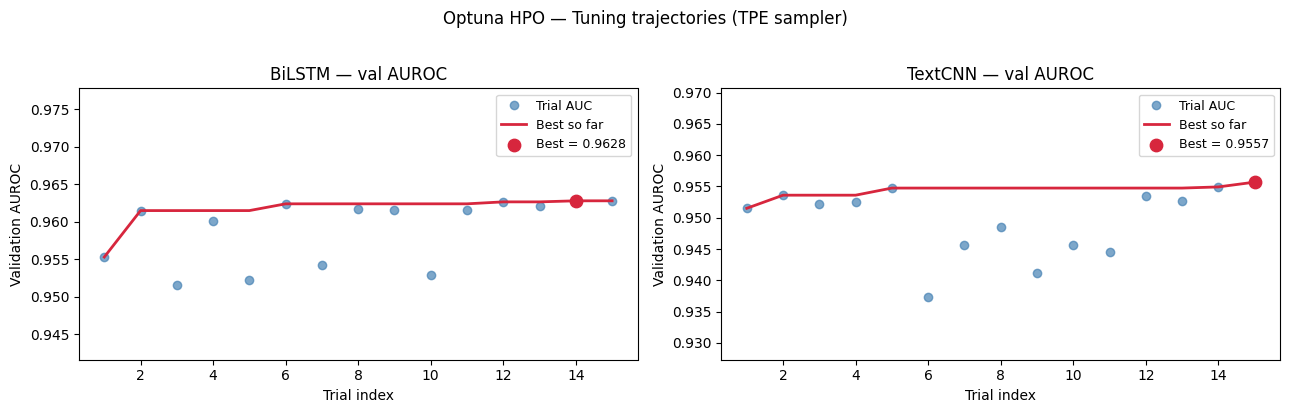

  Model  Best val AUC  hidden1  hidden2  dropout       lr  weight_decay  batch_size  freeze_emb  n_filters
 BiLSTM      0.962762     64.0    128.0      0.5 0.000658      0.002702          32       False        NaN
TextCNN      0.955694      NaN      NaN      0.4 0.001925      0.002561         128       False      128.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, study, title in zip(
        axes,
        [study_bilstm, study_textcnn],
        ["BiLSTM — val AUROC", "TextCNN — val AUROC"]):
    vals  = [t.value for t in study.trials]
    best_so_far = [max(vals[:i+1]) for i in range(len(vals))]
    ax.plot(range(1, len(vals)+1), vals,
            "o", color="steelblue", alpha=0.7, ms=6, label="Trial AUC")
    ax.plot(range(1, len(vals)+1), best_so_far,
            "-", color="#d7263d", lw=2, label="Best so far")
    best_idx = int(np.argmax(vals))
    ax.scatter(best_idx + 1, vals[best_idx],
               color="#d7263d", zorder=5, s=80, label=f"Best = {vals[best_idx]:.4f}")
    ax.set_xlabel("Trial index"); ax.set_ylabel("Validation AUROC")
    ax.set_title(title); ax.legend(fontsize=9)
    ax.set_ylim(max(0.5, min(vals) - 0.01), min(1.0, max(vals) + 0.015))

plt.suptitle("Optuna HPO — Tuning trajectories (TPE sampler)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("fig_tuning_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

# Print summary table
tuning_summary = pd.DataFrame([
    {"Model": "BiLSTM",  "Best val AUC": study_bilstm.best_value,
     **study_bilstm.best_params},
    {"Model": "TextCNN", "Best val AUC": study_textcnn.best_value,
     **study_textcnn.best_params},
])
print(tuning_summary.to_string(index=False))

### Model 1 — GloVe + BiLSTM + Self-Attention


In [ ]:
class GloveBiLSTMAttn(torch.nn.Module):
    def __init__(self, embedding_matrix, freeze_emb=True,
                 hidden1=128, hidden2=64, dropout=0.3):
        super().__init__()
        v, d = embedding_matrix.shape
        self.emb = torch.nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=freeze_emb,
            padding_idx=0)
        self.lstm1 = torch.nn.LSTM(d, hidden1, batch_first=True,
                                   bidirectional=True, dropout=0.0)
        self.drop1 = torch.nn.Dropout(dropout)
        self.lstm2 = torch.nn.LSTM(hidden1 * 2, hidden2, batch_first=True,
                                   bidirectional=True, dropout=0.0)
        self.attn  = torch.nn.Linear(hidden2 * 2, 1)
        self.head  = torch.nn.Sequential(
            torch.nn.Linear(hidden2 * 2, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.5),
            torch.nn.Linear(64, 1))

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1).float()
        h = self.emb(x)
        h, _ = self.lstm1(h)
        h = self.drop1(h)
        h, _ = self.lstm2(h)                     # [B, T, 2H2]
        scores = self.attn(h)                    # [B, T, 1]
        scores = scores.masked_fill(mask == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        ctx = (h * weights).sum(dim=1)           # [B, 2H2]
        return self.head(ctx)

torch.manual_seed(STUDENT_ID)
m1 = GloveBiLSTMAttn(
    embedding_matrix,
    freeze_emb = best_bilstm_params["freeze_emb"],
    hidden1    = best_bilstm_params["hidden1"],
    hidden2    = best_bilstm_params["hidden2"],
    dropout    = best_bilstm_params["dropout"],
)
print(m1)
print(f"\nTuned hyperparameters: {best_bilstm_params}")
print(f"Trainable params: {sum(p.numel() for p in m1.parameters() if p.requires_grad):,}")
res1 = train_model(m1, ds_tr, ds_va, ds_te,
                   name="M1 GloVe+BiLSTM-Attn",
                   epochs=10,
                   batch_size   = best_bilstm_params["batch_size"],
                   lr           = best_bilstm_params["lr"],
                   weight_decay = best_bilstm_params["weight_decay"])
predictions[res1["name"]] = res1["y_prob"]


GloveBiLSTMAttn(
  (emb): Embedding(36102, 200, padding_idx=0)
  (lstm1): LSTM(200, 64, batch_first=True, bidirectional=True)
  (drop1): Dropout(p=0.5, inplace=False)
  (lstm2): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=256, out_features=1, bias=True)
  (head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Tuned hyperparameters: {'hidden1': 64, 'hidden2': 128, 'dropout': 0.5, 'lr': 0.000657987494928166, 'weight_decay': 0.002702389839675479, 'batch_size': 32, 'freeze_emb': False}
Trainable params: 7,637,554
[M1 GloVe+BiLSTM-Attn] epoch  1  tr_loss=0.4212 va_loss=0.3090  tr_auc=0.8896 va_auc=0.9532  (5.5s)
[M1 GloVe+BiLSTM-Attn] epoch  2  tr_loss=0.2381 va_loss=0.2718  tr_auc=0.9648 va_auc=0.9628  (5.6s)
[M1 GloVe+BiLSTM-Attn] epoch  3  tr_loss=0.1226 va_loss=0.3231  tr_auc=0.9891 va_auc=0.9565  (5.5s)


###  Model 2 — GloVe + TextCNN (Kim, 2014)



In [ ]:
class GloveTextCNN(torch.nn.Module):
    def __init__(self, embedding_matrix, freeze_emb=True,
                 n_filters=100, kernel_sizes=(3, 4, 5), dropout=0.5):
        super().__init__()
        v, d = embedding_matrix.shape
        self.emb = torch.nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=freeze_emb,
            padding_idx=0)
        self.convs = torch.nn.ModuleList(
            [torch.nn.Conv1d(d, n_filters, ks, padding=ks // 2)
             for ks in kernel_sizes])
        self.drop = torch.nn.Dropout(dropout)
        self.head = torch.nn.Sequential(
            torch.nn.Linear(n_filters * len(kernel_sizes), 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 1))

    def forward(self, x):
        h = self.emb(x).transpose(1, 2)                 # [B, d, T]
        feats = [torch.relu(c(h)).max(dim=2).values for c in self.convs]
        cat = torch.cat(feats, dim=1)
        return self.head(self.drop(cat))

torch.manual_seed(STUDENT_ID)
m2 = GloveTextCNN(
    embedding_matrix,
    freeze_emb = best_textcnn_params["freeze_emb"],
    n_filters  = best_textcnn_params["n_filters"],
    dropout    = best_textcnn_params["dropout"],
)
print(m2)
print(f"\nTuned hyperparameters: {best_textcnn_params}")
print(f"Trainable params: {sum(p.numel() for p in m2.parameters() if p.requires_grad):,}")
res2 = train_model(m2, ds_tr, ds_va, ds_te,
                   name="M2 GloVe+TextCNN",
                   epochs=10,
                   batch_size   = best_textcnn_params["batch_size"],
                   lr           = best_textcnn_params["lr"],
                   weight_decay = best_textcnn_params["weight_decay"])
predictions[res2["name"]] = res2["y_prob"]


GloveTextCNN(
  (emb): Embedding(36102, 200, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(200, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Conv1d(200, 128, kernel_size=(4,), stride=(1,), padding=(2,))
    (2): Conv1d(200, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  )
  (drop): Dropout(p=0.4, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Tuned hyperparameters: {'n_filters': 128, 'dropout': 0.4, 'lr': 0.0019247343055886121, 'weight_decay': 0.002561342768045149, 'batch_size': 128, 'freeze_emb': False}
Trainable params: 7,577,393
[M2 GloVe+TextCNN] epoch  1  tr_loss=0.4545 va_loss=0.2977  tr_auc=0.8647 va_auc=0.9499  (1.2s)
[M2 GloVe+TextCNN] epoch  2  tr_loss=0.2346 va_loss=0.2752  tr_auc=0.9662 va_auc=0.9557  (1.2s)
[M2 GloVe+TextCNN] epoch  3  tr_loss=0.0988 va_loss=0.3583  tr_auc=0.

### Embedding B — DistilBERT-base (fine-tuned) — three heads


In [ ]:

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert-base-uncased"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
DISTILBERT_HIDDEN = 768                          # encoder hidden size
print(f"Tokenizer loaded for {MODEL_NAME}")
print(f"  Hidden size : {DISTILBERT_HIDDEN}")
print(f"  Each M3/M4/M7 cell will reload a fresh encoder for fine-tuning.")


Tokenizer loaded for distilbert-base-uncased
  Hidden size : 768
  Each M3/M4/M7 cell will reload a fresh encoder for fine-tuning.


In [ ]:
HEAD_LEN, TAIL_LEN = 128, 382
MAX_LEN_B = HEAD_LEN + TAIL_LEN + 2  # CLS + SEP

def head_tail_encode(text: str):
    # Sun et al. (2019) head+tail truncation.
    ids = tokenizer.encode(text, add_special_tokens=False)
    if len(ids) <= MAX_LEN_B - 2:
        ids = [tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id]
    else:
        ids = [tokenizer.cls_token_id] + ids[:HEAD_LEN] + ids[-TAIL_LEN:] + [tokenizer.sep_token_id]
    mask = [1] * len(ids)
    pad  = MAX_LEN_B - len(ids)
    return ids + [0] * pad, mask + [0] * pad

# Pre-encode all splits once
def encode_split_B(texts):
    ids_all, mask_all = [], []
    for t in texts:
        ids, m = head_tail_encode(t)
        ids_all.append(ids); mask_all.append(m)
    return np.array(ids_all, dtype=np.int64), np.array(mask_all, dtype=np.int64)

print("Encoding train/val/test under Pipeline B (head+tail)...")
ids_tr, mask_tr = encode_split_B(df_train["text_B"].tolist())
ids_va, mask_va = encode_split_B(df_val["text_B"].tolist())
ids_te, mask_te = encode_split_B(df_test["text_B"].tolist())
print("Shapes:", ids_tr.shape, ids_va.shape, ids_te.shape)


Token indices sequence length is longer than the specified maximum sequence length for this model (646 > 512). Running this sequence through the model will result in indexing errors


Encoding train/val/test under Pipeline B (head+tail)...
Shapes: (16728, 512) (2091, 512) (2092, 512)


In [ ]:

print("Fine-tune mode — no encoder pre-caching needed.")


Fine-tune mode — no encoder pre-caching needed.


In [ ]:

class IMDBBertDataset(Dataset):
    def __init__(self, ids, mask, y):
        self.ids = ids; self.mask = mask
        self.y = y.astype(np.float32)
    def __len__(self):  return len(self.y)
    def __getitem__(self, i):
        return (torch.from_numpy(self.ids[i]),
                torch.from_numpy(self.mask[i]),
                torch.tensor(self.y[i]))

ds_tr_b = IMDBBertDataset(ids_tr, mask_tr, df_train["sentiment"].values)
ds_va_b = IMDBBertDataset(ids_va, mask_va, df_val  ["sentiment"].values)
ds_te_b = IMDBBertDataset(ids_te, mask_te, df_test ["sentiment"].values)
print(f"BERT-encoded datasets ready. Train batch yields tuple of three tensors.")

def make_loaders_b(ds_tr, ds_va, ds_te, batch_size=16):
    g = torch.Generator(); g.manual_seed(STUDENT_ID)
    return (DataLoader(ds_tr, batch_size=batch_size, shuffle=True,  generator=g),
            DataLoader(ds_va, batch_size=batch_size, shuffle=False),
            DataLoader(ds_te, batch_size=batch_size, shuffle=False))

def epoch_pass_b(head, backbone, loader, criterion, optimizer=None, device=DEVICE):
    is_train = optimizer is not None
    head.train(is_train); backbone.eval()
    total_loss = 0.0; ys, ps = [], []
    n_seen = 0
    for ids, mask, y in loader:
        ids = ids.to(device); mask = mask.to(device); y = y.to(device)
        with torch.no_grad():
            h = backbone(input_ids=ids, attention_mask=mask).last_hidden_state
        logits = head(h, mask).squeeze(-1)
        loss = criterion(logits, y)
        if not torch.isfinite(loss):
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            continue
        if is_train:
            optimizer.zero_grad()
            loss.backward()

            grad_norm = torch.nn.utils.clip_grad_norm_(head.parameters(), max_norm=1.0)
            if not torch.isfinite(grad_norm):
                optimizer.zero_grad(set_to_none=True)
                continue
            optimizer.step()
        total_loss += loss.item() * ids.size(0)
        n_seen += ids.size(0)
        ys.append(y.detach().cpu().numpy())
        ps.append(torch.sigmoid(logits).detach().cpu().numpy())
    if n_seen == 0:
        return float("nan"), float("nan"), np.array([]), np.array([])
    ys = np.concatenate(ys); ps = np.concatenate(ps)
    return total_loss / n_seen, roc_auc_score(ys, ps), ys, ps

def train_head(head, backbone, ds_tr, ds_va, ds_te, *,
               name, epochs=6, batch_size=16, lr=2e-4, weight_decay=1e-2,
               patience=2, eval_test=True):
    """Same eval_test contract as train_model — set False during Optuna."""
    head = head.to(DEVICE)
    tr_l, va_l, te_l = make_loaders_b(ds_tr, ds_va, ds_te, batch_size)
    crit = torch.nn.BCEWithLogitsLoss()
    optim = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="max", factor=0.5, patience=1)
    best_auc = -1; best_state = None; bad = 0
    history = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_auc, *_ = epoch_pass_b(head, backbone, tr_l, crit, optim)
        va_loss, va_auc, *_ = epoch_pass_b(head, backbone, va_l, crit, None)
        sched.step(va_auc)
        for k, v in zip(["tr_loss","va_loss","tr_auc","va_auc"],
                        [tr_loss, va_loss, tr_auc, va_auc]):
            history[k].append(v)
        print(f"[{name}] epoch {epoch:>2d}  tr_loss={tr_loss:.4f} va_loss={va_loss:.4f}  "
              f"tr_auc={tr_auc:.4f} va_auc={va_auc:.4f}  ({time.time()-t0:.1f}s)")
        if va_auc > best_auc + 1e-4:
            best_auc = va_auc
            best_state = {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"[{name}] early stop at epoch {epoch}"); break
    if best_state is None:
        print(f"[{name}] training never produced a finite val AUC; returning -inf")
        return {"name": name, "history": history,
                "y_true": None, "y_prob": None,
                "test_auc": float("nan"), "best_val_auc": float("-inf")}
    head.load_state_dict(best_state); head.eval()
    if eval_test:
        te_loss, te_auc, y_true, y_prob = epoch_pass_b(head, backbone, te_l, crit, None)
        print(f"[{name}] BEST val AUC={best_auc:.4f}; TEST AUC={te_auc:.4f}, "
              f"acc={(y_prob > 0.5).astype(int).__eq__(y_true.astype(int)).mean():.4f}")
    else:
        te_auc, y_true, y_prob = float("nan"), None, None
        print(f"[{name}] BEST val AUC={best_auc:.4f}  (test eval skipped — HPO mode)")
    return {"name": name, "history": history, "y_true": y_true, "y_prob": y_prob,
            "test_auc": te_auc, "best_val_auc": best_auc}

BERT-encoded datasets ready. Train batch yields tuple of three tensors.


### Models 3 & 4 — DistilBERT (fine-tuned) + two sequence heads


In [ ]:
# Full DistilBERT encoder + BiLSTM-Attn head for end-to-end fine-tuning.
class DistilBertBiLSTMAttn(torch.nn.Module):
    def __init__(self, hidden1=128, hidden2=64, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        self.encoder.gradient_checkpointing_enable()
        self.lstm1 = torch.nn.LSTM(DISTILBERT_HIDDEN, hidden1,
                                   batch_first=True, bidirectional=True)
        self.drop1 = torch.nn.Dropout(dropout)
        self.lstm2 = torch.nn.LSTM(hidden1 * 2, hidden2,
                                   batch_first=True, bidirectional=True)
        self.attn  = torch.nn.Linear(hidden2 * 2, 1)
        self.clf   = torch.nn.Sequential(
            torch.nn.Linear(hidden2 * 2, 64), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(64, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h, _ = self.lstm1(h); h = self.drop1(h)
        h, _ = self.lstm2(h)
        s = self.attn(h).masked_fill(m == 0, -1e9)
        w = torch.softmax(s, dim=1)
        return self.clf((h * w).sum(dim=1))

print("DistilBertBiLSTMAttn class defined.")
print("Untuned demo skipped — Optuna search and final training in cells below.")


DistilBertBiLSTMAttn class defined.
Untuned demo skipped — Optuna search and final training in cells below.


In [ ]:
# Full DistilBERT encoder + TextCNN head for end-to-end fine-tuning.
class DistilBertTextCNN(torch.nn.Module):
    def __init__(self, n_filters=100, kernel_sizes=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        self.encoder.gradient_checkpointing_enable()
        self.convs = torch.nn.ModuleList(
            [torch.nn.Conv1d(DISTILBERT_HIDDEN, n_filters, ks, padding=ks // 2)
             for ks in kernel_sizes])
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(n_filters * len(kernel_sizes), 128),
            torch.nn.ReLU(), torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        x = h.transpose(1, 2)
        feats = [torch.relu(c(x)).max(dim=2).values for c in self.convs]
        return self.clf(self.drop(torch.cat(feats, dim=1)))

print("DistilBertTextCNN class defined.")


DistilBertTextCNN class defined.


In [ ]:
# End-to-end DistilBERT fine-tuning training loop.
# Two parameter groups: encoder (small lr) and head (larger lr) — Howard &
# Ruder (2018) layerwise-LR-decay protocol. Uses bf16 mixed precision.
from torch.cuda.amp import autocast, GradScaler
from torch.optim.lr_scheduler import LambdaLR

def train_distilbert_ft(model, ds_tr, ds_va, ds_te,
                        name="M?", epochs=3, batch_size=16,
                        lr_encoder=2e-5, lr_head=1e-4,
                        weight_decay=0.01, warmup_ratio=0.1,
                        eval_test=True, verbose=True):
    model = model.to(DEVICE)
    encoder_params = list(model.encoder.parameters())
    head_params    = [p for p in model.parameters()
                      if not any(p is ep for ep in encoder_params)]
    opt = torch.optim.AdamW([
        {"params": encoder_params, "lr": lr_encoder},
        {"params": head_params,    "lr": lr_head},
    ], weight_decay=weight_decay)
    total_steps  = (len(ds_tr) // batch_size + 1) * epochs
    warmup_steps = int(total_steps * warmup_ratio)
    def lr_lambda(step):
        if step < warmup_steps: return step / max(warmup_steps, 1)
        prog = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return max(0.0, 1.0 - prog)
    sched = LambdaLR(opt, lr_lambda)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    scaler  = GradScaler()
    g = torch.Generator(); g.manual_seed(STUDENT_ID)
    tr_l = DataLoader(ds_tr, batch_size=batch_size, shuffle=True,  generator=g)
    va_l = DataLoader(ds_va, batch_size=batch_size, shuffle=False)
    te_l = DataLoader(ds_te, batch_size=batch_size, shuffle=False)

    best_va_auc = -1.0; best_state = None
    history = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}
    for ep in range(1, epochs + 1):
        model.train(); tr_loss = 0.0; tr_y, tr_p = [], []
        for ids, mask, y in tr_l:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with autocast(dtype=torch.bfloat16):
                logits = model(ids, mask).squeeze(-1)
                loss   = loss_fn(logits, y)
            if not torch.isfinite(loss): continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tr_loss += loss.item() * ids.size(0)
            tr_y.append(y.detach().cpu().numpy())
            tr_p.append(torch.sigmoid(logits.float()).detach().cpu().numpy())
        tr_y = np.concatenate(tr_y); tr_p = np.concatenate(tr_p)
        tr_auc = roc_auc_score(tr_y, tr_p)
        model.eval(); va_loss = 0.0; va_y, va_p = [], []
        with torch.no_grad():
            for ids, mask, y in va_l:
                ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
                with autocast(dtype=torch.bfloat16):
                    logits = model(ids, mask).squeeze(-1)
                    va_loss += loss_fn(logits, y).item() * ids.size(0)
                va_y.append(y.cpu().numpy())
                va_p.append(torch.sigmoid(logits.float()).cpu().numpy())
        va_y = np.concatenate(va_y); va_p = np.concatenate(va_p)
        va_auc = roc_auc_score(va_y, va_p)
        if va_auc > best_va_auc:
            best_va_auc = va_auc
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history["tr_loss"].append(tr_loss / len(ds_tr))
        history["va_loss"].append(va_loss / len(ds_va))
        history["tr_auc"].append(tr_auc); history["va_auc"].append(va_auc)
        if verbose:
            print(f"  ep {ep:2d}  tr_auc={tr_auc:.4f}  va_auc={va_auc:.4f}")
    if best_state is not None:
        model.load_state_dict(best_state)
    if eval_test:
        model.eval(); te_y, te_p = [], []
        with torch.no_grad():
            for ids, mask, y in te_l:
                ids, mask = ids.to(DEVICE), mask.to(DEVICE)
                with autocast(dtype=torch.bfloat16):
                    logits = model(ids, mask).squeeze(-1)
                te_y.append(y.numpy())
                te_p.append(torch.sigmoid(logits.float()).cpu().numpy())
        te_y = np.concatenate(te_y); te_p = np.concatenate(te_p)
        return {"name": name, "history": history, "y_prob": te_p,
                "y_true": te_y, "best_val_auc": best_va_auc, "model": model}
    return {"name": name, "history": history, "best_val_auc": best_va_auc}

def objective_bert_bilstm(trial):
    p = {
        "hidden1":      trial.suggest_categorical("hidden1", [64, 128, 256]),
        "hidden2":      trial.suggest_categorical("hidden2", [32, 64, 128]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.5),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-5, 5e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    5e-5, 5e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    model = DistilBertBiLSTMAttn(hidden1=p["hidden1"], hidden2=p["hidden2"],
                                  dropout=p["dropout"])
    res = train_distilbert_ft(model, ds_tr_b, ds_va_b, ds_te_b,
                              name=f"tune_M3_{trial.number}",
                              epochs=1, batch_size=16,
                              lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                              weight_decay=p["weight_decay"],
                              eval_test=False, verbose=False)
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return res["best_val_auc"]

def objective_bert_textcnn(trial):
    p = {
        "n_filters":    trial.suggest_categorical("n_filters", [50, 100, 150]),
        "dropout":      trial.suggest_float("dropout", 0.3, 0.7),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-5, 5e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    5e-5, 5e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    model = DistilBertTextCNN(n_filters=p["n_filters"], dropout=p["dropout"])
    res = train_distilbert_ft(model, ds_tr_b, ds_va_b, ds_te_b,
                              name=f"tune_M4_{trial.number}",
                              epochs=1, batch_size=16,
                              lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                              weight_decay=p["weight_decay"],
                              eval_test=False, verbose=False)
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return res["best_val_auc"]

study_bert_bilstm = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_bert_bilstm.optimize(objective_bert_bilstm, n_trials=4, show_progress_bar=True)

study_bert_textcnn = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_bert_textcnn.optimize(objective_bert_textcnn, n_trials=4, show_progress_bar=True)

best_bert_bilstm_params  = study_bert_bilstm.best_params
best_bert_textcnn_params = study_bert_textcnn.best_params
print(f"\nBest M3 (DistilBERT-FT + BiLSTM-Attn) val AUC: {study_bert_bilstm.best_value:.4f}")
print(f"  params: {best_bert_bilstm_params}")
print(f"Best M4 (DistilBERT-FT + TextCNN) val AUC: {study_bert_textcnn.best_value:.4f}")
print(f"  params: {best_bert_textcnn_params}")


  0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Best M3 (DistilBERT-FT + BiLSTM-Attn) val AUC: 0.9767
  params: {'hidden1': 256, 'hidden2': 32, 'dropout': 0.11331421374648505, 'lr_encoder': 4.9021851010461086e-05, 'lr_head': 0.0002729255748154501, 'weight_decay': 0.0026167048682362018}
Best M4 (DistilBERT-FT + TextCNN) val AUC: 0.9771
  params: {'n_filters': 150, 'dropout': 0.6130173621677434, 'lr_encoder': 2.7119380770760356e-05, 'lr_head': 0.00010716616957280569, 'weight_decay': 0.0011390718637401009}


In [ ]:

torch.manual_seed(STUDENT_ID)
m3 = DistilBertBiLSTMAttn(
    hidden1 = best_bert_bilstm_params["hidden1"],
    hidden2 = best_bert_bilstm_params["hidden2"],
    dropout = best_bert_bilstm_params["dropout"])
print(f"M3 total params: {sum(p.numel() for p in m3.parameters()):,}")
res3 = train_distilbert_ft(m3, ds_tr_b, ds_va_b, ds_te_b,
                           name="M3 DistilBERT(FT)+BiLSTM-Attn",
                           epochs=3, batch_size=16,
                           lr_encoder   = best_bert_bilstm_params["lr_encoder"],
                           lr_head      = best_bert_bilstm_params["lr_head"],
                           weight_decay = best_bert_bilstm_params["weight_decay"])
predictions[res3["name"]] = res3["y_prob"]
all_histories[res3["name"]] = res3["history"]

# Free GPU memory before next model
del m3; gc.collect(); torch.cuda.empty_cache()


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M3 total params: 68,608,194
  ep  1  tr_auc=0.9146  va_auc=0.9734
  ep  2  tr_auc=0.9739  va_auc=0.9759
  ep  3  tr_auc=0.9891  va_auc=0.9739


In [ ]:

torch.manual_seed(STUDENT_ID)
m4 = DistilBertTextCNN(
    n_filters = best_bert_textcnn_params["n_filters"],
    dropout   = best_bert_textcnn_params["dropout"])
print(f"M4 total params: {sum(p.numel() for p in m4.parameters()):,}")
res4 = train_distilbert_ft(m4, ds_tr_b, ds_va_b, ds_te_b,
                           name="M4 DistilBERT(FT)+TextCNN",
                           epochs=3, batch_size=16,
                           lr_encoder   = best_bert_textcnn_params["lr_encoder"],
                           lr_head      = best_bert_textcnn_params["lr_head"],
                           weight_decay = best_bert_textcnn_params["weight_decay"])
predictions[res4["name"]] = res4["y_prob"]
all_histories[res4["name"]] = res4["history"]

del m4; gc.collect(); torch.cuda.empty_cache()


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M4 total params: 67,803,587
  ep  1  tr_auc=0.9228  va_auc=0.9751
  ep  2  tr_auc=0.9817  va_auc=0.9770
  ep  3  tr_auc=0.9923  va_auc=0.9766


### Model 5 — DistilBERT (fine-tuned) + minimal linear head


In [ ]:
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

torch.manual_seed(STUDENT_ID)
clf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2).to(DEVICE)

# Use the same head+tail tokenisation we already cached
ds_tr_c = IMDBBertDataset(ids_tr, mask_tr, df_train["sentiment"].values)
ds_va_c = IMDBBertDataset(ids_va, mask_va, df_val  ["sentiment"].values)
ds_te_c = IMDBBertDataset(ids_te, mask_te, df_test ["sentiment"].values)

EPOCHS_FT = 5
BATCH_FT  = 16
LR_FT     = 2e-5
tr_l_c, va_l_c, te_l_c = make_loaders_b(ds_tr_c, ds_va_c, ds_te_c, BATCH_FT)
total_steps = EPOCHS_FT * len(tr_l_c)
optim = torch.optim.AdamW(clf_model.parameters(), lr=LR_FT, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(
    optim, num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps)

best_va_auc = -1; best_state = None
history_ft = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}

for epoch in range(1, EPOCHS_FT + 1):
    t0 = time.time(); clf_model.train()
    tr_loss = 0.0; tr_y, tr_p = [], []
    for ids, mask, y in tr_l_c:
        ids = ids.to(DEVICE); mask = mask.to(DEVICE); y = y.long().to(DEVICE)
        out = clf_model(input_ids=ids, attention_mask=mask, labels=y)
        out.loss.backward(); optim.step(); sched.step(); optim.zero_grad()
        tr_loss += out.loss.item() * ids.size(0)
        tr_y.append(y.detach().cpu().numpy())
        tr_p.append(torch.softmax(out.logits, dim=1)[:, 1].detach().cpu().numpy())
    tr_y = np.concatenate(tr_y); tr_p = np.concatenate(tr_p)
    tr_auc = roc_auc_score(tr_y, tr_p)

    clf_model.eval(); va_loss = 0.0; va_y, va_p = [], []
    with torch.no_grad():
        for ids, mask, y in va_l_c:
            ids = ids.to(DEVICE); mask = mask.to(DEVICE); y = y.long().to(DEVICE)
            out = clf_model(input_ids=ids, attention_mask=mask, labels=y)
            va_loss += out.loss.item() * ids.size(0)
            va_y.append(y.detach().cpu().numpy())
            va_p.append(torch.softmax(out.logits, dim=1)[:, 1].detach().cpu().numpy())
    va_y = np.concatenate(va_y); va_p = np.concatenate(va_p)
    va_auc = roc_auc_score(va_y, va_p)
    history_ft["tr_loss"].append(tr_loss / len(ds_tr_c))
    history_ft["va_loss"].append(va_loss / len(ds_va_c))
    history_ft["tr_auc"].append(tr_auc); history_ft["va_auc"].append(va_auc)
    print(f"[M5 FT] epoch {epoch}  tr_loss={tr_loss/len(ds_tr_c):.4f} "
          f"va_loss={va_loss/len(ds_va_c):.4f}  tr_auc={tr_auc:.4f} "
          f"va_auc={va_auc:.4f}  ({time.time()-t0:.1f}s)")
    if va_auc > best_va_auc:
        best_va_auc = va_auc
        best_state = {k: v.detach().cpu().clone() for k, v in clf_model.state_dict().items()}
clf_model.load_state_dict(best_state); clf_model.eval()

print(f"[M5 FT] BEST val AUC={best_va_auc:.4f}  (test eval skipped — HPO mode)")
res5 = {"name": "M5 DistilBERT-FT (head+tail)", "history": history_ft,
        "y_true": None, "y_prob": None,
        "test_auc": float("nan"), "best_val_auc": best_va_auc}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[M5 FT] epoch 1  tr_loss=0.3271 va_loss=0.1967  tr_auc=0.9334 va_auc=0.9768  (164.6s)
[M5 FT] epoch 2  tr_loss=0.1548 va_loss=0.2232  tr_auc=0.9842 va_auc=0.9782  (165.1s)
[M5 FT] epoch 3  tr_loss=0.0729 va_loss=0.2240  tr_auc=0.9956 va_auc=0.9791  (165.0s)
[M5 FT] epoch 4  tr_loss=0.0321 va_loss=0.2766  tr_auc=0.9985 va_auc=0.9785  (165.0s)
[M5 FT] epoch 5  tr_loss=0.0162 va_loss=0.2922  tr_auc=0.9994 va_auc=0.9787  (165.0s)
[M5 FT] BEST val AUC=0.9791  (test eval skipped — HPO mode)


In [ ]:
def objective_distilbert_ft(trial):
    lr_ft        = trial.suggest_float("lr",           1e-5, 5e-5, log=True)
    warmup_ratio = trial.suggest_float("warmup_ratio", 0.05, 0.15, step=0.05)

    torch.manual_seed(STUDENT_ID)
    _clf = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2).to(DEVICE)

    _total_steps = 2 * len(tr_l_c)
    _optim = torch.optim.AdamW(_clf.parameters(), lr=lr_ft, weight_decay=0.01)
    _sched = get_linear_schedule_with_warmup(
        _optim,
        num_warmup_steps=int(warmup_ratio * _total_steps),
        num_training_steps=_total_steps)

    best_va = -1.0
    try:
        for epoch in range(1, 3):
            _clf.train()
            for ids, mask, y in tr_l_c:
                ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.long().to(DEVICE)
                out = _clf(input_ids=ids, attention_mask=mask, labels=y)
                out.loss.backward(); _optim.step(); _sched.step(); _optim.zero_grad()

            _clf.eval(); va_y, va_p = [], []
            with torch.no_grad():
                for ids, mask, y in va_l_c:
                    ids, mask = ids.to(DEVICE), mask.to(DEVICE)
                    logits = _clf(input_ids=ids, attention_mask=mask).logits
                    va_p.append(torch.softmax(logits, -1)[:, 1].cpu().numpy())
                    va_y.append(y.numpy())
            va_auc = roc_auc_score(np.concatenate(va_y), np.concatenate(va_p))
            if va_auc > best_va:
                best_va = va_auc
            else:
                break
    finally:
        del _clf, _optim, _sched
        gc.collect(); torch.cuda.empty_cache()

    return best_va

study_ft = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_ft.optimize(objective_distilbert_ft, n_trials=5, show_progress_bar=True)

print("M5 best params:", study_ft.best_params)
best_ft_params = study_ft.best_params

  0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


M5 best params: {'lr': 2.7119380770760356e-05, 'warmup_ratio': 0.05}


In [ ]:

torch.manual_seed(STUDENT_ID)
clf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2).to(DEVICE)

EPOCHS_FT = 3
BATCH_FT  = 16
LR_FT     = best_ft_params["lr"]
WARMUP_R  = best_ft_params["warmup_ratio"]

tr_l_c, va_l_c, te_l_c = make_loaders_b(ds_tr_c, ds_va_c, ds_te_c, BATCH_FT)
total_steps = EPOCHS_FT * len(tr_l_c)
optim = torch.optim.AdamW(clf_model.parameters(), lr=LR_FT, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(
    optim,
    num_warmup_steps=int(WARMUP_R * total_steps),
    num_training_steps=total_steps)

print(f"Retraining M5 — lr={LR_FT:.2e}, warmup_ratio={WARMUP_R}")

best_va_auc = -1; best_state = None
history_ft = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}

for epoch in range(1, EPOCHS_FT + 1):
    t0 = time.time(); clf_model.train()
    tr_loss = 0.0; tr_y, tr_p = [], []
    for ids, mask, y in tr_l_c:
        ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.long().to(DEVICE)
        out = clf_model(input_ids=ids, attention_mask=mask, labels=y)
        out.loss.backward(); optim.step(); sched.step(); optim.zero_grad()
        tr_loss += out.loss.item() * ids.size(0)
        tr_y.append(y.detach().cpu().numpy())
        tr_p.append(torch.softmax(out.logits, -1)[:,1].detach().cpu().numpy())
    tr_auc = roc_auc_score(np.concatenate(tr_y), np.concatenate(tr_p))
    tr_loss /= len(ds_tr_c)

    clf_model.eval(); va_loss = 0.0; va_y, va_p = [], []
    with torch.no_grad():
        for ids, mask, y in va_l_c:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.long().to(DEVICE)
            out = clf_model(input_ids=ids, attention_mask=mask, labels=y)
            va_loss += out.loss.item() * ids.size(0)
            va_y.append(y.cpu().numpy())
            va_p.append(torch.softmax(out.logits, -1)[:,1].cpu().numpy())
    va_auc  = roc_auc_score(np.concatenate(va_y), np.concatenate(va_p))
    va_loss /= len(ds_va_c)

    for k, v in zip(["tr_loss","va_loss","tr_auc","va_auc"],
                    [tr_loss, va_loss, tr_auc, va_auc]):
        history_ft[k].append(v)

    print(f"[M5 retune] epoch {epoch:>2d}  tr_loss={tr_loss:.4f} va_loss={va_loss:.4f}  "
          f"tr_auc={tr_auc:.4f} va_auc={va_auc:.4f}  ({time.time()-t0:.1f}s)")

    if va_auc > best_va_auc + 1e-4:
        best_va_auc = va_auc
        best_state  = {k: v.detach().cpu().clone()
                       for k, v in clf_model.state_dict().items()}

clf_model.load_state_dict(best_state); clf_model.eval()
te_y, te_p = [], []
with torch.no_grad():
    for ids, mask, y in te_l_c:
        ids, mask = ids.to(DEVICE), mask.to(DEVICE)
        logits = clf_model(input_ids=ids, attention_mask=mask).logits
        te_y.append(y.numpy())
        te_p.append(torch.softmax(logits, -1)[:,1].cpu().numpy())

te_y = np.concatenate(te_y); te_p = np.concatenate(te_p)
res5 = {"name": "M5 DistilBERT-FT (head+tail)",   # SAME key as cell 70
        "history": history_ft, "y_true": te_y, "y_prob": te_p,
        "test_auc": roc_auc_score(te_y, te_p),
        "best_val_auc": best_va_auc}

predictions["M5 DistilBERT-FT (head+tail)"] = te_p   # SAME key as cell 70
print(f"\nM5 retune — best val AUC={best_va_auc:.4f}  test AUC={res5['test_auc']:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Retraining M5 — lr=2.71e-05, warmup_ratio=0.05
[M5 retune] epoch  1  tr_loss=0.2877 va_loss=0.1838  tr_auc=0.9494 va_auc=0.9794  (163.9s)
[M5 retune] epoch  2  tr_loss=0.1235 va_loss=0.2022  tr_auc=0.9895 va_auc=0.9805  (164.6s)
[M5 retune] epoch  3  tr_loss=0.0472 va_loss=0.2326  tr_auc=0.9976 va_auc=0.9808  (164.5s)

M5 retune — best val AUC=0.9808  test AUC=0.9835


### xLSTM models


In [ ]:

import subprocess, sys, importlib

XLSTM_OK = False
try:
    import xlstm
    XLSTM_OK = True
    print(f"xlstm already available: {getattr(xlstm, '__version__', 'unknown')}")
except ImportError:
    print("Installing xlstm + dependencies (~30 s) ...")
    subprocess.run([sys.executable, "-m", "pip", "install",
                    "xlstm", "dacite", "omegaconf", "-q"],
                   check=False)
    try:
        importlib.invalidate_caches()
        import xlstm
        XLSTM_OK = True
        print(f"xlstm installed: {getattr(xlstm, '__version__', 'unknown')}")
    except Exception as e:
        print(f"xlstm import failed ({e}) — falling back to custom implementation")
        XLSTM_OK = False

if XLSTM_OK:
    from xlstm import (
        xLSTMBlockStack, xLSTMBlockStackConfig,
        mLSTMBlockConfig, mLSTMLayerConfig,
    )

    def make_xlstm_stack(embedding_dim, context_length, num_blocks=2, num_heads=4):
        """mLSTM-only block stack (parallelisable, no CUDA kernels needed).

        embedding_dim must be divisible by num_heads * qkv_proj_blocksize (=4)
        — we choose dimensions in the xLSTM heads accordingly.
        """
        cfg = xLSTMBlockStackConfig(
            mlstm_block=mLSTMBlockConfig(
                mlstm=mLSTMLayerConfig(
                    conv1d_kernel_size=4,
                    qkv_proj_blocksize=4,
                    num_heads=num_heads,
                ),
            ),
            context_length=context_length,
            num_blocks=num_blocks,
            embedding_dim=embedding_dim,
        )
        return xLSTMBlockStack(cfg)
else:
    class _XLSTMFallbackBlock(torch.nn.Module):
        def __init__(self, dim, dropout=0.2):
            super().__init__()
            self.norm1 = torch.nn.LayerNorm(dim)
            self.lstm  = torch.nn.LSTM(dim, dim // 2, batch_first=True,
                                       bidirectional=True)
            self.norm2 = torch.nn.LayerNorm(dim)
            self.ff    = torch.nn.Sequential(
                torch.nn.Linear(dim, dim * 2), torch.nn.GELU(),
                torch.nn.Dropout(dropout),
                torch.nn.Linear(dim * 2, dim))
            self.drop  = torch.nn.Dropout(dropout)
        def forward(self, x):
            h, _ = self.lstm(self.norm1(x))
            x = x + self.drop(h)
            x = x + self.drop(self.ff(self.norm2(x)))
            return x

    def make_xlstm_stack(embedding_dim, context_length, num_blocks=2, num_heads=4):
        return torch.nn.Sequential(
            *[_XLSTMFallbackBlock(embedding_dim) for _ in range(num_blocks)])

print(f"xLSTM ready (official package = {XLSTM_OK})")

Installing xlstm + dependencies (~30 s) ...
xlstm installed: 2.0.5
xLSTM ready (official package = True)


### Model 6 — GloVe + xLSTM


In [ ]:
class GloveXLSTM(torch.nn.Module):
    """GloVe → projection → xLSTMBlockStack → masked mean-pool → MLP head.

    The projection is required because the xLSTM mLSTM head needs the
    embedding_dim to be divisible by num_heads * 4. GloVe is 200-d, which
    does not satisfy this for num_heads in {2,4,8} → we project to 256.
    """
    def __init__(self, embedding_matrix, freeze_emb=True,
                 proj_dim=256, num_blocks=2, num_heads=4, dropout=0.3,
                 context_length=None):
        super().__init__()
        v, d = embedding_matrix.shape
        self.emb = torch.nn.Embedding.from_pretrained(
            torch.from_numpy(embedding_matrix), freeze=freeze_emb,
            padding_idx=0)
        self.proj = torch.nn.Linear(d, proj_dim) if d != proj_dim else torch.nn.Identity()
        ctx = context_length if context_length is not None else MAX_LEN_A
        self.xlstm = make_xlstm_stack(
            embedding_dim=proj_dim,
            context_length=ctx,
            num_blocks=num_blocks,
            num_heads=num_heads,
        )
        self.drop = torch.nn.Dropout(dropout)
        self.head = torch.nn.Sequential(
            torch.nn.Linear(proj_dim, 64), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(64, 1))

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1).float()           # [B, T, 1]
        h = self.proj(self.emb(x))                       # [B, T, proj_dim]
        h = self.xlstm(h)                                # [B, T, proj_dim]
        h = h * mask                                      # zero pad positions
        pooled = h.sum(dim=1) / (mask.sum(dim=1) + 1e-9) # masked mean
        return self.head(self.drop(pooled))

torch.manual_seed(STUDENT_ID)
m6_demo = GloveXLSTM(embedding_matrix)
print(m6_demo)
print(f"\nTrainable params: {sum(p.numel() for p in m6_demo.parameters() if p.requires_grad):,}")
del m6_demo

GloveXLSTM(
  (emb): Embedding(36102, 200, padding_idx=0)
  (proj): Linear(in_features=200, out_features=256, bias=True)
  (xlstm): xLSTMBlockStack(
    (blocks): ModuleList(
      (0-1): 2 x mLSTMBlock(
        (xlstm_norm): LayerNorm()
        (xlstm): mLSTMLayer(
          (proj_up): Linear(in_features=256, out_features=1024, bias=False)
          (q_proj): LinearHeadwiseExpand(in_features=512, num_heads=128, expand_factor_up=1, bias=False, trainable_weight=True, trainable_bias=True, )
          (k_proj): LinearHeadwiseExpand(in_features=512, num_heads=128, expand_factor_up=1, bias=False, trainable_weight=True, trainable_bias=True, )
          (v_proj): LinearHeadwiseExpand(in_features=512, num_heads=128, expand_factor_up=1, bias=False, trainable_weight=True, trainable_bias=True, )
          (conv1d): CausalConv1d(
            (conv): Conv1d(512, 512, kernel_size=(4,), stride=(1,), padding=(3,), groups=512)
          )
          (conv_act_fn): SiLU()
          (mlstm_cell): mLSTMCel

In [ ]:


def objective_glove_xlstm(trial):
    proj_dim     = trial.suggest_categorical("proj_dim",     [128, 256])
    num_blocks   = trial.suggest_int("num_blocks",           1, 3)
    num_heads    = trial.suggest_categorical("num_heads",    [2, 4])
    dropout      = trial.suggest_float("dropout",            0.2, 0.5, step=0.1)
    lr           = trial.suggest_float("lr",                 5e-4, 3e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay",       1e-3, 1e-1, log=True)
    batch_size   = trial.suggest_categorical("batch_size",   [32, 64])
    freeze       = trial.suggest_categorical("freeze_emb",   [True, False])
    torch.manual_seed(STUDENT_ID)
    model = GloveXLSTM(embedding_matrix,
                        freeze_emb=freeze,
                        proj_dim=proj_dim,
                        num_blocks=num_blocks,
                        num_heads=num_heads,
                        dropout=dropout)
    res = train_model(model, ds_tr, ds_va, ds_te,
                      name=f"tune_xlstm_{trial.number}",
                      epochs=5, batch_size=batch_size,
                      lr=lr, weight_decay=weight_decay, patience=2,
                      eval_test=False)           
    return res["best_val_auc"]

N_TRIALS_XLSTM_GLOVE = 8        # xLSTM is heavier than vanilla LSTM, so fewer trials
print(f"Running Optuna xLSTM-GloVe search — {N_TRIALS_XLSTM_GLOVE} trials ...")
study_glove_xlstm = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_glove_xlstm.optimize(objective_glove_xlstm,
                            n_trials=N_TRIALS_XLSTM_GLOVE,
                            show_progress_bar=True)
print(f"GloVe+xLSTM best val AUC : {study_glove_xlstm.best_value:.4f}")
print("Best params:", study_glove_xlstm.best_params)
best_glove_xlstm_params = study_glove_xlstm.best_params

Running Optuna xLSTM-GloVe search — 8 trials ...


  0%|          | 0/8 [00:00<?, ?it/s]

[tune_xlstm_0] epoch  1  tr_loss=0.4498 va_loss=0.3388  tr_auc=0.8718 va_auc=0.9332  (22.4s)
[tune_xlstm_0] epoch  2  tr_loss=0.3396 va_loss=0.3194  tr_auc=0.9296 va_auc=0.9394  (21.8s)
[tune_xlstm_0] epoch  3  tr_loss=0.3063 va_loss=0.3090  tr_auc=0.9437 va_auc=0.9427  (21.5s)
[tune_xlstm_0] epoch  4  tr_loss=0.2637 va_loss=0.3495  tr_auc=0.9577 va_auc=0.9436  (21.7s)
[tune_xlstm_0] epoch  5  tr_loss=0.2247 va_loss=0.3904  tr_auc=0.9689 va_auc=0.9410  (21.6s)
[tune_xlstm_0] BEST val AUC=0.9436  (test eval skipped — HPO mode)
[tune_xlstm_1] epoch  1  tr_loss=0.4700 va_loss=0.3961  tr_auc=0.8576 va_auc=0.9300  (8.1s)
[tune_xlstm_1] epoch  2  tr_loss=0.3525 va_loss=0.3247  tr_auc=0.9240 va_auc=0.9419  (8.1s)
[tune_xlstm_1] epoch  3  tr_loss=0.3139 va_loss=0.3209  tr_auc=0.9401 va_auc=0.9441  (8.1s)
[tune_xlstm_1] epoch  4  tr_loss=0.2856 va_loss=0.3190  tr_auc=0.9503 va_auc=0.9434  (8.1s)
[tune_xlstm_1] epoch  5  tr_loss=0.2539 va_loss=0.3149  tr_auc=0.9606 va_auc=0.9450  (8.1s)
[tune_xl

In [ ]:
# Retrain M6 (GloVe + xLSTM) with the tuned hyperparameters
torch.manual_seed(STUDENT_ID)
m6 = GloveXLSTM(
    embedding_matrix,
    freeze_emb = best_glove_xlstm_params["freeze_emb"],
    proj_dim   = best_glove_xlstm_params["proj_dim"],
    num_blocks = best_glove_xlstm_params["num_blocks"],
    num_heads  = best_glove_xlstm_params["num_heads"],
    dropout    = best_glove_xlstm_params["dropout"],
)
print(f"Tuned hyperparameters: {best_glove_xlstm_params}")
print(f"Trainable params: {sum(p.numel() for p in m6.parameters() if p.requires_grad):,}")
res6 = train_model(m6, ds_tr, ds_va, ds_te,
                   name="M6 GloVe+xLSTM",
                   epochs=10,
                   batch_size   = best_glove_xlstm_params["batch_size"],
                   lr           = best_glove_xlstm_params["lr"],
                   weight_decay = best_glove_xlstm_params["weight_decay"])
predictions[res6["name"]] = res6["y_prob"]

Tuned hyperparameters: {'proj_dim': 128, 'num_blocks': 1, 'num_heads': 4, 'dropout': 0.30000000000000004, 'lr': 0.0005265772946195199, 'weight_decay': 0.09169592007673041, 'batch_size': 32, 'freeze_emb': True}
Trainable params: 143,625
[M6 GloVe+xLSTM] epoch  1  tr_loss=0.4537 va_loss=0.3321  tr_auc=0.8687 va_auc=0.9336  (9.0s)
[M6 GloVe+xLSTM] epoch  2  tr_loss=0.3434 va_loss=0.3163  tr_auc=0.9274 va_auc=0.9388  (9.0s)
[M6 GloVe+xLSTM] epoch  3  tr_loss=0.3137 va_loss=0.3074  tr_auc=0.9403 va_auc=0.9436  (9.2s)
[M6 GloVe+xLSTM] epoch  4  tr_loss=0.2808 va_loss=0.3586  tr_auc=0.9519 va_auc=0.9414  (9.3s)
[M6 GloVe+xLSTM] epoch  5  tr_loss=0.2502 va_loss=0.3255  tr_auc=0.9618 va_auc=0.9466  (9.3s)
[M6 GloVe+xLSTM] epoch  6  tr_loss=0.2178 va_loss=0.3501  tr_auc=0.9707 va_auc=0.9410  (9.0s)
[M6 GloVe+xLSTM] epoch  7  tr_loss=0.1863 va_loss=0.4037  tr_auc=0.9783 va_auc=0.9371  (9.0s)
[M6 GloVe+xLSTM] epoch  8  tr_loss=0.1236 va_loss=0.4256  tr_auc=0.9898 va_auc=0.9386  (9.0s)
[M6 GloVe+xL

### Model 7 — DistilBERT (fine-tuned) + xLSTM head


In [ ]:
# Full DistilBERT encoder + xLSTM head for end-to-end fine-tuning.
class DistilBertXLSTM(torch.nn.Module):
    """xLSTM stack over a FINE-TUNED DistilBERT encoder (768-d)."""
    def __init__(self, num_blocks=2, num_heads=4, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        self.encoder.gradient_checkpointing_enable()
        self.xlstm = make_xlstm_stack(
            embedding_dim=DISTILBERT_HIDDEN,
            context_length=MAX_LEN_B,
            num_blocks=num_blocks,
            num_heads=num_heads)
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(DISTILBERT_HIDDEN, 128), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h = self.xlstm(h)
        h = h * m
        pooled = h.sum(dim=1) / (m.sum(dim=1) + 1e-9)
        return self.clf(self.drop(pooled))

print("DistilBertXLSTM class defined.")


DistilBertXLSTM class defined.


In [ ]:

def objective_bert_xlstm(trial):
    p = {
        "num_blocks":   trial.suggest_int("num_blocks", 1, 3),
        "num_heads":    trial.suggest_categorical("num_heads", [4, 8]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.5),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-5, 5e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    5e-5, 5e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    try:
        model = DistilBertXLSTM(num_blocks=p["num_blocks"],
                                num_heads=p["num_heads"], dropout=p["dropout"])
        res = train_distilbert_ft(model, ds_tr_b, ds_va_b, ds_te_b,
                                  name=f"tune_M7_{trial.number}",
                                  epochs=1, batch_size=8,
                                  lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                                  weight_decay=p["weight_decay"],
                                  eval_test=False, verbose=False)
        del model; gc.collect(); torch.cuda.empty_cache()
        return res["best_val_auc"]
    except RuntimeError as e:
        print(f"  Trial pruned: {e}")
        gc.collect(); torch.cuda.empty_cache()
        raise optuna.TrialPruned()

N_TRIALS_XLSTM_BERT = 3
print(f"Running Optuna M7 search — {N_TRIALS_XLSTM_BERT} trials …")
study_bert_xlstm = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_bert_xlstm.optimize(objective_bert_xlstm,
                          n_trials=N_TRIALS_XLSTM_BERT,
                          show_progress_bar=True)
print(f"M7 best val AUC : {study_bert_xlstm.best_value:.4f}")
print("Best params:", study_bert_xlstm.best_params)
best_bert_xlstm_params = study_bert_xlstm.best_params


Running Optuna M7 search — 3 trials …


  0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M7 best val AUC : 0.9771
Best params: {'num_blocks': 1, 'num_heads': 8, 'dropout': 0.41301736216774343, 'lr_encoder': 2.7119380770760356e-05, 'lr_head': 0.00010716616957280569, 'weight_decay': 0.0011390718637401009}


In [ ]:

torch.manual_seed(STUDENT_ID)
m7 = DistilBertXLSTM(
    num_blocks = best_bert_xlstm_params["num_blocks"],
    num_heads  = best_bert_xlstm_params["num_heads"],
    dropout    = best_bert_xlstm_params["dropout"])
print(f"M7 total params: {sum(p.numel() for p in m7.parameters()):,}")
res7 = train_distilbert_ft(m7, ds_tr_b, ds_va_b, ds_te_b,
                           name="M7 DistilBERT(FT)+xLSTM",
                           epochs=3, batch_size=8,
                           lr_encoder   = best_bert_xlstm_params["lr_encoder"],
                           lr_head      = best_bert_xlstm_params["lr_head"],
                           weight_decay = best_bert_xlstm_params["weight_decay"])
predictions[res7["name"]] = res7["y_prob"]
all_histories[res7["name"]] = res7["history"]

del m7; gc.collect(); torch.cuda.empty_cache()


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M7 total params: 70,104,849
  ep  1  tr_auc=0.9274  va_auc=0.9753
  ep  2  tr_auc=0.9790  va_auc=0.9777
  ep  3  tr_auc=0.9928  va_auc=0.9790


### Embedding C — fastText (Joulin et al., 2016) — three heads

In [ ]:

import gensim.downloader as api
print("Loading fasttext-wiki-news-subwords-300 (≈ 958 MB)…")
fasttext_vec = api.load("fasttext-wiki-news-subwords-300")
FT_DIM = fasttext_vec.vector_size
print(f"  vector size  : {FT_DIM}")
print(f"  vocab size   : {len(fasttext_vec.key_to_index):,}")
print(f"  sample word  : 'absolutely' → {fasttext_vec['absolutely'][:5].round(3)} …")


Loading fasttext-wiki-news-subwords-300 (≈ 958 MB)…
[==================================================] 100.0% 958.5/958.4MB downloaded
  vector size  : 300
  vocab size   : 999,999
  sample word  : 'absolutely' → [-0.007  0.076  0.003  0.04   0.006] …


In [ ]:

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def _obj_ft_bilstm(trial):
    p = {
        "hidden1":      trial.suggest_categorical("hidden1", [64, 128, 256]),
        "hidden2":      trial.suggest_categorical("hidden2", [32, 64, 128]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.5),
        "lr":           trial.suggest_float("lr", 5e-4, 5e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
        "freeze_emb":   trial.suggest_categorical("freeze_emb", [True, False]),
    }
    torch.manual_seed(STUDENT_ID)
    model = GloveBiLSTMAttn(embedding_matrix_ft, freeze_emb=p["freeze_emb"],
                            hidden1=p["hidden1"], hidden2=p["hidden2"],
                            dropout=p["dropout"])
    res = train_model(model, ds_tr, ds_va, ds_te,
                      name=f"M8_trial_{trial.number}",
                      epochs=4, batch_size=p["batch_size"], lr=p["lr"],
                      weight_decay=p["weight_decay"],
                      eval_test=False)
    return res["best_val_auc"]

study_ft_bilstm = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_ft_bilstm.optimize(_obj_ft_bilstm, n_trials=10, show_progress_bar=True)
best_ft_bilstm = study_ft_bilstm.best_params
print(f"\nBest M8 val AUC: {study_ft_bilstm.best_value:.4f}")
print(f"Best params: {best_ft_bilstm}")


torch.manual_seed(STUDENT_ID)
m8 = GloveBiLSTMAttn(embedding_matrix_ft,
                     freeze_emb=best_ft_bilstm["freeze_emb"],
                     hidden1=best_ft_bilstm["hidden1"],
                     hidden2=best_ft_bilstm["hidden2"],
                     dropout=best_ft_bilstm["dropout"])
print(f"\nM8 trainable params: "
      f"{sum(p.numel() for p in m8.parameters() if p.requires_grad):,}")
res8 = train_model(m8, ds_tr, ds_va, ds_te,
                   name="M8 fastText+BiLSTM-Attn",
                   epochs=10,
                   batch_size=best_ft_bilstm["batch_size"],
                   lr=best_ft_bilstm["lr"],
                   weight_decay=best_ft_bilstm["weight_decay"])
predictions[res8["name"]] = res8["y_prob"]
all_histories[res8["name"]] = res8["history"]


  0%|          | 0/10 [00:00<?, ?it/s]

[M8_trial_0] epoch  1  tr_loss=0.6933 va_loss=0.6932  tr_auc=0.5131 va_auc=0.5266  (7.6s)
[M8_trial_0] epoch  2  tr_loss=0.6934 va_loss=0.6931  tr_auc=0.4964 va_auc=0.5332  (7.3s)
[M8_trial_0] epoch  3  tr_loss=0.6934 va_loss=0.6932  tr_auc=0.5002 va_auc=0.5376  (7.3s)
[M8_trial_0] epoch  4  tr_loss=0.6932 va_loss=0.6930  tr_auc=0.5023 va_auc=0.5401  (7.4s)
[M8_trial_0] BEST val AUC=0.5401  (test eval skipped — HPO mode)
[M8_trial_1] epoch  1  tr_loss=0.4452 va_loss=0.2957  tr_auc=0.8740 va_auc=0.9533  (8.1s)
[M8_trial_1] epoch  2  tr_loss=0.1716 va_loss=0.2861  tr_auc=0.9805 va_auc=0.9572  (7.8s)
[M8_trial_1] epoch  3  tr_loss=0.0612 va_loss=0.3715  tr_auc=0.9967 va_auc=0.9508  (7.8s)
[M8_trial_1] epoch  4  tr_loss=0.0333 va_loss=0.5606  tr_auc=0.9987 va_auc=0.9483  (7.9s)
[M8_trial_1] BEST val AUC=0.9572  (test eval skipped — HPO mode)
[M8_trial_2] epoch  1  tr_loss=0.5451 va_loss=0.3706  tr_auc=0.7966 va_auc=0.9188  (2.1s)
[M8_trial_2] epoch  2  tr_loss=0.4017 va_loss=0.3844  tr_auc

In [ ]:

def _obj_ft_textcnn(trial):
    p = {
        "n_filters":    trial.suggest_categorical("n_filters", [50, 100, 150]),
        "dropout":      trial.suggest_float("dropout", 0.3, 0.7),
        "lr":           trial.suggest_float("lr", 5e-4, 5e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
        "freeze_emb":   trial.suggest_categorical("freeze_emb", [True, False]),
    }
    torch.manual_seed(STUDENT_ID)
    model = GloveTextCNN(embedding_matrix_ft, freeze_emb=p["freeze_emb"],
                         n_filters=p["n_filters"], dropout=p["dropout"])
    res = train_model(model, ds_tr, ds_va, ds_te,
                      name=f"M9_trial_{trial.number}",
                      epochs=4, batch_size=p["batch_size"], lr=p["lr"],
                      weight_decay=p["weight_decay"],
                      eval_test=False)
    return res["best_val_auc"]

study_ft_textcnn = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_ft_textcnn.optimize(_obj_ft_textcnn, n_trials=10, show_progress_bar=True)
best_ft_textcnn = study_ft_textcnn.best_params
print(f"\nBest M9 val AUC: {study_ft_textcnn.best_value:.4f}")
print(f"Best params: {best_ft_textcnn}")

torch.manual_seed(STUDENT_ID)
m9 = GloveTextCNN(embedding_matrix_ft,
                  freeze_emb=best_ft_textcnn["freeze_emb"],
                  n_filters=best_ft_textcnn["n_filters"],
                  dropout=best_ft_textcnn["dropout"])
print(f"\nM9 trainable params: "
      f"{sum(p.numel() for p in m9.parameters() if p.requires_grad):,}")
res9 = train_model(m9, ds_tr, ds_va, ds_te,
                   name="M9 fastText+TextCNN",
                   epochs=10,
                   batch_size=best_ft_textcnn["batch_size"],
                   lr=best_ft_textcnn["lr"],
                   weight_decay=best_ft_textcnn["weight_decay"])
predictions[res9["name"]] = res9["y_prob"]
all_histories[res9["name"]] = res9["history"]


  0%|          | 0/10 [00:00<?, ?it/s]

[M9_trial_0] epoch  1  tr_loss=0.4370 va_loss=0.3009  tr_auc=0.8789 va_auc=0.9513  (1.8s)
[M9_trial_0] epoch  2  tr_loss=0.2139 va_loss=0.2898  tr_auc=0.9717 va_auc=0.9515  (1.7s)
[M9_trial_0] epoch  3  tr_loss=0.0758 va_loss=0.4049  tr_auc=0.9960 va_auc=0.9403  (1.7s)
[M9_trial_0] epoch  4  tr_loss=0.0425 va_loss=0.4648  tr_auc=0.9984 va_auc=0.9358  (1.7s)
[M9_trial_0] BEST val AUC=0.9515  (test eval skipped — HPO mode)
[M9_trial_1] epoch  1  tr_loss=0.5246 va_loss=0.3128  tr_auc=0.8180 va_auc=0.9423  (1.2s)
[M9_trial_1] epoch  2  tr_loss=0.2524 va_loss=0.2783  tr_auc=0.9608 va_auc=0.9534  (1.2s)
[M9_trial_1] epoch  3  tr_loss=0.1021 va_loss=0.3423  tr_auc=0.9928 va_auc=0.9451  (1.2s)
[M9_trial_1] epoch  4  tr_loss=0.0313 va_loss=0.4269  tr_auc=0.9991 va_auc=0.9435  (1.2s)
[M9_trial_1] BEST val AUC=0.9534  (test eval skipped — HPO mode)
[M9_trial_2] epoch  1  tr_loss=0.4646 va_loss=0.2948  tr_auc=0.8586 va_auc=0.9485  (3.2s)
[M9_trial_2] epoch  2  tr_loss=0.2255 va_loss=0.2816  tr_auc

In [ ]:

def _obj_ft_xlstm(trial):
    p = {
        "num_blocks":   trial.suggest_int("num_blocks", 1, 3),
        "num_heads":    trial.suggest_categorical("num_heads", [2, 4]),
        "proj_dim":     trial.suggest_categorical("proj_dim", [128, 256]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.5),
        "lr":           trial.suggest_float("lr", 5e-4, 5e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size":   trial.suggest_categorical("batch_size", [32, 64]),
        "freeze_emb":   trial.suggest_categorical("freeze_emb", [True, False]),
    }
    torch.manual_seed(STUDENT_ID)
    try:
        model = GloveXLSTM(embedding_matrix_ft, freeze_emb=p["freeze_emb"],
                           proj_dim=p["proj_dim"], num_blocks=p["num_blocks"],
                           num_heads=p["num_heads"], dropout=p["dropout"])
        res = train_model(model, ds_tr, ds_va, ds_te,
                          name=f"M10_trial_{trial.number}",
                          epochs=3, batch_size=p["batch_size"], lr=p["lr"],
                          weight_decay=p["weight_decay"],
                          eval_test=False)
        return res["best_val_auc"]
    except RuntimeError as e:

        print(f"  Trial pruned: {e}")
        raise optuna.TrialPruned()

study_ft_xlstm = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_ft_xlstm.optimize(_obj_ft_xlstm, n_trials=8, show_progress_bar=True)
best_ft_xlstm = study_ft_xlstm.best_params
print(f"\nBest M10 val AUC: {study_ft_xlstm.best_value:.4f}")
print(f"Best params: {best_ft_xlstm}")

torch.manual_seed(STUDENT_ID)
m10 = GloveXLSTM(embedding_matrix_ft,
                 freeze_emb=best_ft_xlstm["freeze_emb"],
                 proj_dim=best_ft_xlstm["proj_dim"],
                 num_blocks=best_ft_xlstm["num_blocks"],
                 num_heads=best_ft_xlstm["num_heads"],
                 dropout=best_ft_xlstm["dropout"])
print(f"\nM10 trainable params: "
      f"{sum(p.numel() for p in m10.parameters() if p.requires_grad):,}")
res10 = train_model(m10, ds_tr, ds_va, ds_te,
                    name="M10 fastText+xLSTM",
                    epochs=8,
                    batch_size=best_ft_xlstm["batch_size"],
                    lr=best_ft_xlstm["lr"],
                    weight_decay=best_ft_xlstm["weight_decay"])
predictions[res10["name"]] = res10["y_prob"]
all_histories[res10["name"]] = res10["history"]


  0%|          | 0/8 [00:00<?, ?it/s]

[M10_trial_0] epoch  1  tr_loss=0.4519 va_loss=0.3158  tr_auc=0.8691 va_auc=0.9401  (9.1s)
[M10_trial_0] epoch  2  tr_loss=0.3420 va_loss=0.2937  tr_auc=0.9289 va_auc=0.9495  (9.2s)
[M10_trial_0] epoch  3  tr_loss=0.3070 va_loss=0.2904  tr_auc=0.9427 va_auc=0.9506  (9.1s)
[M10_trial_0] BEST val AUC=0.9506  (test eval skipped — HPO mode)
[M10_trial_1] epoch  1  tr_loss=0.5376 va_loss=0.3503  tr_auc=0.7942 va_auc=0.9288  (36.4s)
[M10_trial_1] epoch  2  tr_loss=0.3612 va_loss=0.3247  tr_auc=0.9203 va_auc=0.9369  (36.2s)
[M10_trial_1] epoch  3  tr_loss=0.3442 va_loss=0.3431  tr_auc=0.9280 va_auc=0.9410  (36.3s)
[M10_trial_1] BEST val AUC=0.9410  (test eval skipped — HPO mode)
[M10_trial_2] epoch  1  tr_loss=0.4579 va_loss=0.3255  tr_auc=0.8649 va_auc=0.9360  (38.0s)
[M10_trial_2] epoch  2  tr_loss=0.3522 va_loss=0.3146  tr_auc=0.9247 va_auc=0.9411  (38.0s)
[M10_trial_2] epoch  3  tr_loss=0.3210 va_loss=0.3021  tr_auc=0.9379 va_auc=0.9450  (37.9s)
[M10_trial_2] BEST val AUC=0.9450  (test ev

### Embedding D — DeBERTa-v3-large (fine-tuned) — three heads


In [ ]:

from transformers import AutoTokenizer, AutoModel

DEBERTA_NAME = "microsoft/deberta-v3-large"
deberta_tokenizer = AutoTokenizer.from_pretrained(DEBERTA_NAME, use_fast=True)
DEBERTA_HIDDEN = 1024
print(f"Tokenizer loaded for {DEBERTA_NAME}")
print(f"  Hidden size : {DEBERTA_HIDDEN}")
print(f"  Encoder reloaded fresh per model — no shared backbone.")


Tokenizer loaded for microsoft/deberta-v3-large
  Hidden size : 1024
  Encoder reloaded fresh per model — no shared backbone.


In [ ]:
# Head + tail tokenisation for DeBERTa (Sun et al., 2019)
HEAD_LEN_D, TAIL_LEN_D = 128, 382
MAX_LEN_D = HEAD_LEN_D + TAIL_LEN_D + 2     # + [CLS] + [SEP]

def head_tail_encode_deberta(text: str):
    full = deberta_tokenizer.encode(text, add_special_tokens=False)
    if len(full) <= HEAD_LEN_D + TAIL_LEN_D:
        ids = full
    else:
        ids = full[:HEAD_LEN_D] + full[-TAIL_LEN_D:]
    cls, sep, pad = (deberta_tokenizer.cls_token_id,
                     deberta_tokenizer.sep_token_id,
                     deberta_tokenizer.pad_token_id)
    ids = [cls] + ids + [sep]
    mask = [1] * len(ids)
    pad_len = MAX_LEN_D - len(ids)
    ids  += [pad] * pad_len
    mask += [0] * pad_len
    return ids[:MAX_LEN_D], mask[:MAX_LEN_D]

def encode_split_deberta(texts):
    ids, mask = [], []
    for t in tqdm(texts, desc="DeBERTa tokenise", leave=False):
        i, m = head_tail_encode_deberta(t)
        ids.append(i); mask.append(m)
    return np.array(ids, dtype=np.int64), np.array(mask, dtype=np.int64)

ids_tr_d, mask_tr_d = encode_split_deberta(df_train["text_B"].tolist())
ids_va_d, mask_va_d = encode_split_deberta(df_val  ["text_B"].tolist())
ids_te_d, mask_te_d = encode_split_deberta(df_test ["text_B"].tolist())
print(f"DeBERTa tokenised: train {ids_tr_d.shape}, val {ids_va_d.shape}, "
      f"test {ids_te_d.shape}")


DeBERTa tokenise:   0%|          | 0/16728 [00:00<?, ?it/s]

DeBERTa tokenise:   0%|          | 0/2091 [00:00<?, ?it/s]

DeBERTa tokenise:   0%|          | 0/2092 [00:00<?, ?it/s]

DeBERTa tokenised: train (16728, 512), val (2091, 512), test (2092, 512)


In [ ]:

class DebertaFinetuneDataset(Dataset):
    def __init__(self, ids_arr, mask_arr, y_arr):
        self.ids  = torch.from_numpy(ids_arr).long()
        self.mask = torch.from_numpy(mask_arr).long()
        self.y    = torch.from_numpy(y_arr.astype("float32"))
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.mask[i], self.y[i]

ds_tr_d = DebertaFinetuneDataset(ids_tr_d, mask_tr_d, df_train["sentiment"].values)
ds_va_d = DebertaFinetuneDataset(ids_va_d, mask_va_d, df_val  ["sentiment"].values)
ds_te_d = DebertaFinetuneDataset(ids_te_d, mask_te_d, df_test ["sentiment"].values)
print(f"DeBERTa fine-tune datasets: "
      f"train={len(ds_tr_d)}, val={len(ds_va_d)}, test={len(ds_te_d)}")


DeBERTa fine-tune datasets: train=16728, val=2091, test=2092


In [ ]:


class DeBERTaBiLSTMAttn(torch.nn.Module):
    def __init__(self, hidden1=128, hidden2=64, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME)
        self.lstm1 = torch.nn.LSTM(DEBERTA_HIDDEN, hidden1,
                                   batch_first=True, bidirectional=True)
        self.drop1 = torch.nn.Dropout(dropout)
        self.lstm2 = torch.nn.LSTM(hidden1 * 2, hidden2,
                                   batch_first=True, bidirectional=True)
        self.attn  = torch.nn.Linear(hidden2 * 2, 1)
        self.clf   = torch.nn.Sequential(
            torch.nn.Linear(hidden2 * 2, 64), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(64, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h, _ = self.lstm1(h); h = self.drop1(h)
        h, _ = self.lstm2(h)
        s = self.attn(h).masked_fill(m == 0, -1e9)
        w = torch.softmax(s, dim=1)
        return self.clf((h * w).sum(dim=1))


class DeBERTaTextCNN(torch.nn.Module):
    def __init__(self, n_filters=100, kernel_sizes=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME)
        self.convs = torch.nn.ModuleList(
            [torch.nn.Conv1d(DEBERTA_HIDDEN, n_filters, ks, padding=ks // 2)
             for ks in kernel_sizes])
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(n_filters * len(kernel_sizes), 128),
            torch.nn.ReLU(), torch.nn.Dropout(0.3), torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        x = h.transpose(1, 2)
        feats = [torch.relu(c(x)).max(dim=2).values for c in self.convs]
        return self.clf(self.drop(torch.cat(feats, dim=1)))


class DeBERTaXLSTM(torch.nn.Module):
    def __init__(self, num_blocks=2, num_heads=4, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME)
        self.xlstm = make_xlstm_stack(
            embedding_dim=DEBERTA_HIDDEN, context_length=MAX_LEN_D,
            num_blocks=num_blocks, num_heads=num_heads)
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(DEBERTA_HIDDEN, 128), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h = self.xlstm(h)
        h = h * m
        pooled = h.sum(dim=1) / (m.sum(dim=1) + 1e-9)
        return self.clf(self.drop(pooled))

print("DeBERTa-v3-large fine-tune model classes defined.")


DeBERTa-v3-large fine-tune model classes defined.


In [ ]:

from torch.cuda.amp import autocast, GradScaler
from torch.optim.lr_scheduler import LambdaLR

def train_deberta_ft(model, ds_tr, ds_va, ds_te,
                     name="M?", epochs=3, batch_size=8,
                     lr_encoder=5e-6, lr_head=5e-5,
                     weight_decay=0.01, warmup_ratio=0.1,
                     eval_test=True, verbose=True):
    model = model.to(DEVICE)
    encoder_params = list(model.encoder.parameters())
    head_params    = [p for p in model.parameters()
                      if not any(p is ep for ep in encoder_params)]
    opt = torch.optim.AdamW([
        {"params": encoder_params, "lr": lr_encoder},
        {"params": head_params,    "lr": lr_head},
    ], weight_decay=weight_decay)
    total_steps  = (len(ds_tr) // batch_size + 1) * epochs
    warmup_steps = int(total_steps * warmup_ratio)
    def lr_lambda(step):
        if step < warmup_steps: return step / max(warmup_steps, 1)
        prog = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return max(0.0, 1.0 - prog)
    sched = LambdaLR(opt, lr_lambda)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    scaler  = GradScaler()    # fp16 needs this
    g = torch.Generator(); g.manual_seed(STUDENT_ID)
    tr_l = DataLoader(ds_tr, batch_size=batch_size, shuffle=True, generator=g)
    va_l = DataLoader(ds_va, batch_size=batch_size, shuffle=False)
    te_l = DataLoader(ds_te, batch_size=batch_size, shuffle=False)

    best_va_auc = -1.0; best_state = None
    history = {"tr_loss": [], "va_loss": [], "tr_auc": [], "va_auc": []}

    for ep in range(1, epochs + 1):
        model.train(); tr_loss = 0.0; tr_y, tr_p = [], []
        n_trained = 0; n_skipped = 0
        for ids, mask, y in tr_l:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with autocast(dtype=torch.float16):       # fp16, not bf16
                logits = model(ids, mask).squeeze(-1)
                loss   = loss_fn(logits, y)
            if not torch.isfinite(loss):
                n_skipped += 1
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            if not torch.isfinite(grad_norm):
                opt.zero_grad(set_to_none=True)
                scaler.update()
                n_skipped += 1
                continue
            scaler.step(opt); scaler.update(); sched.step()
            n_trained += 1
            tr_loss += loss.item() * ids.size(0)
            tr_y.append(y.detach().cpu().numpy())
            p_safe = torch.sigmoid(logits.float()).detach().cpu().numpy()
            tr_p.append(np.nan_to_num(p_safe, nan=0.5))
        tr_y = np.concatenate(tr_y) if tr_y else np.array([0, 1])
        tr_p = np.concatenate(tr_p) if tr_p else np.array([0.5, 0.5])
        tr_auc = roc_auc_score(tr_y, tr_p) if len(np.unique(tr_y)) > 1 else 0.5

        model.eval(); va_loss = 0.0; va_y, va_p = [], []
        with torch.no_grad():
            for ids, mask, y in va_l:
                ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
                with autocast(dtype=torch.float16):
                    logits = model(ids, mask).squeeze(-1)
                    loss_v = loss_fn(logits, y)
                if torch.isfinite(loss_v):
                    va_loss += loss_v.item() * ids.size(0)
                va_y.append(y.cpu().numpy())
                p_safe = torch.sigmoid(logits.float()).cpu().numpy()
                va_p.append(np.nan_to_num(p_safe, nan=0.5))
        va_y = np.concatenate(va_y); va_p = np.concatenate(va_p)
        va_auc = roc_auc_score(va_y, va_p) if len(np.unique(va_y)) > 1 else 0.5

        if va_auc > best_va_auc:
            best_va_auc = va_auc
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history["tr_loss"].append(tr_loss / max(len(ds_tr), 1))
        history["va_loss"].append(va_loss / max(len(ds_va), 1))
        history["tr_auc"].append(tr_auc); history["va_auc"].append(va_auc)
        skip_pct = 100 * n_skipped / max(n_trained + n_skipped, 1)
        if verbose or skip_pct > 50:
            print(f"  ep {ep:2d}  tr_auc={tr_auc:.4f}  va_auc={va_auc:.4f}  "
                  f"[trained={n_trained}, skipped={n_skipped} ({skip_pct:.0f}%)]")

    if best_state is not None:
        model.load_state_dict(best_state)

    if eval_test:
        model.eval(); te_y, te_p = [], []
        with torch.no_grad():
            for ids, mask, y in te_l:
                ids, mask = ids.to(DEVICE), mask.to(DEVICE)
                with autocast(dtype=torch.float16):
                    logits = model(ids, mask).squeeze(-1)
                te_y.append(y.numpy())
                p_safe = torch.sigmoid(logits.float()).cpu().numpy()
                te_p.append(np.nan_to_num(p_safe, nan=0.5))
        te_y = np.concatenate(te_y); te_p = np.concatenate(te_p)
        return {"name": name, "history": history, "y_prob": te_p,
                "y_true": te_y, "best_val_auc": best_va_auc, "model": model}
    return {"name": name, "history": history, "best_val_auc": best_va_auc}

In [ ]:


class DeBERTaBiLSTMAttn(torch.nn.Module):
    def __init__(self, hidden1=128, hidden2=64, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME, torch_dtype=torch.float32)
        try:    self.encoder.gradient_checkpointing_disable()
        except Exception: pass
        self.encoder.config.use_cache = False
        self.lstm1 = torch.nn.LSTM(DEBERTA_HIDDEN, hidden1,
                                   batch_first=True, bidirectional=True)
        self.drop1 = torch.nn.Dropout(dropout)
        self.lstm2 = torch.nn.LSTM(hidden1 * 2, hidden2,
                                   batch_first=True, bidirectional=True)
        self.attn  = torch.nn.Linear(hidden2 * 2, 1)
        self.clf   = torch.nn.Sequential(
            torch.nn.Linear(hidden2 * 2, 64), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(64, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h, _ = self.lstm1(h); h = self.drop1(h)
        h, _ = self.lstm2(h)
        s = self.attn(h)
        s = s.masked_fill(m == 0, torch.finfo(s.dtype).min)
        w = torch.softmax(s, dim=1)
        return self.clf((h * w).sum(dim=1))


class DeBERTaTextCNN(torch.nn.Module):
    def __init__(self, n_filters=100, kernel_sizes=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME, torch_dtype=torch.float32)
        try:    self.encoder.gradient_checkpointing_disable()
        except Exception: pass
        self.encoder.config.use_cache = False
        self.convs = torch.nn.ModuleList(
            [torch.nn.Conv1d(DEBERTA_HIDDEN, n_filters, ks, padding=ks // 2)
             for ks in kernel_sizes])
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(n_filters * len(kernel_sizes), 128),
            torch.nn.ReLU(), torch.nn.Dropout(0.3), torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        x = h.transpose(1, 2)
        feats = [torch.relu(c(x)).max(dim=2).values for c in self.convs]
        return self.clf(self.drop(torch.cat(feats, dim=1)))


class DeBERTaXLSTM(torch.nn.Module):
    def __init__(self, num_blocks=2, num_heads=4, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DEBERTA_NAME, torch_dtype=torch.float32)
        try:    self.encoder.gradient_checkpointing_disable()
        except Exception: pass
        self.encoder.config.use_cache = False
        self.xlstm = make_xlstm_stack(
            embedding_dim=DEBERTA_HIDDEN, context_length=MAX_LEN_D,
            num_blocks=num_blocks, num_heads=num_heads)
        self.drop = torch.nn.Dropout(dropout)
        self.clf  = torch.nn.Sequential(
            torch.nn.Linear(DEBERTA_HIDDEN, 128), torch.nn.ReLU(),
            torch.nn.Dropout(0.5), torch.nn.Linear(128, 1))
    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).float()
        h = self.xlstm(h)
        h = h * m
        pooled = h.sum(dim=1) / (m.sum(dim=1) + 1e-9)
        return self.clf(self.drop(pooled))


_probe = DeBERTaBiLSTMAttn()
_is_ckpt = getattr(_probe.encoder, "is_gradient_checkpointing", False)
print(f"DeBERTa classes redefined. Checkpointing on fresh instance: {_is_ckpt}")
del _probe
import gc; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DeBERTa classes redefined. Checkpointing on fresh instance: False


In [ ]:
_probe = DeBERTaBiLSTMAttn()
dtypes = {p.dtype for p in _probe.encoder.parameters()}
print(f"Encoder parameter dtypes: {dtypes}")
assert dtypes == {torch.float32}, "Encoder is not fully fp32 — fix won't work"
print("Encoder confirmed fp32. fp16 + GradScaler training will work.")
del _probe
import gc; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder parameter dtypes: {torch.float32}
✓ Encoder confirmed fp32. fp16 + GradScaler training will work.


In [ ]:

def _obj_d_bilstm(trial):
    p = {
        "hidden1":      trial.suggest_categorical("hidden1", [64, 128, 256]),
        "hidden2":      trial.suggest_categorical("hidden2", [32, 64, 128]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.4),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-6, 1e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    1e-5, 1e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    model = DeBERTaBiLSTMAttn(hidden1=p["hidden1"], hidden2=p["hidden2"],
                               dropout=p["dropout"])
    res = train_deberta_ft(model, ds_tr_d, ds_va_d, ds_te_d,
                           name=f"M11_trial_{trial.number}",
                           epochs=1, batch_size=8,
                           lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                           weight_decay=p["weight_decay"],
                           eval_test=False, verbose=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    return res["best_val_auc"]

study_d_bilstm = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_d_bilstm.optimize(_obj_d_bilstm, n_trials=4, show_progress_bar=True)
best_d_bilstm = study_d_bilstm.best_params
print(f"\nBest M11 val AUC: {study_d_bilstm.best_value:.4f}\nBest params: {best_d_bilstm}")

torch.manual_seed(STUDENT_ID)
m11 = DeBERTaBiLSTMAttn(hidden1=best_d_bilstm["hidden1"],
                         hidden2=best_d_bilstm["hidden2"],
                         dropout=best_d_bilstm["dropout"])
print(f"M11 total params: {sum(p.numel() for p in m11.parameters()):,}")
res11 = train_deberta_ft(m11, ds_tr_d, ds_va_d, ds_te_d,
                         name="M11 DeBERTa-v3-large(FT)+BiLSTM-Attn",
                         epochs=3, batch_size=8,
                         lr_encoder=best_d_bilstm["lr_encoder"],
                         lr_head=best_d_bilstm["lr_head"],
                         weight_decay=best_d_bilstm["weight_decay"])
predictions[res11["name"]] = res11["y_prob"]
all_histories[res11["name"]] = res11["history"]
del m11; gc.collect(); torch.cuda.empty_cache()

  0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Best M11 val AUC: 0.9938
Best params: {'hidden1': 256, 'hidden2': 32, 'dropout': 0.24420489115413785, 'lr_encoder': 4.002052493747962e-06, 'lr_head': 8.028318497157123e-05, 'weight_decay': 0.004139898822969604}


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M11 total params: 436,781,762
  ep  1  tr_auc=0.9548  va_auc=0.9917  [trained=2086, skipped=5 (0%)]
  ep  2  tr_auc=0.9809  va_auc=0.9944  [trained=2089, skipped=2 (0%)]
  ep  3  tr_auc=0.9897  va_auc=0.9941  [trained=2091, skipped=0 (0%)]


In [ ]:

def _obj_d_textcnn(trial):
    p = {
        "n_filters":    trial.suggest_categorical("n_filters", [50, 100, 150]),
        "dropout":      trial.suggest_float("dropout", 0.3, 0.6),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-6, 1e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    1e-5, 1e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    model = DeBERTaTextCNN(n_filters=p["n_filters"], dropout=p["dropout"])
    res = train_deberta_ft(model, ds_tr_d, ds_va_d, ds_te_d,
                           name=f"M12_trial_{trial.number}",
                           epochs=1, batch_size=8,
                           lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                           weight_decay=p["weight_decay"],
                           eval_test=False, verbose=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    return res["best_val_auc"]

study_d_textcnn = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_d_textcnn.optimize(_obj_d_textcnn, n_trials=4, show_progress_bar=True)
best_d_textcnn = study_d_textcnn.best_params
print(f"\nBest M12 val AUC: {study_d_textcnn.best_value:.4f}\nBest params: {best_d_textcnn}")

torch.manual_seed(STUDENT_ID)
m12 = DeBERTaTextCNN(n_filters=best_d_textcnn["n_filters"],
                     dropout=best_d_textcnn["dropout"])
print(f"M12 total params: {sum(p.numel() for p in m12.parameters()):,}")
res12 = train_deberta_ft(m12, ds_tr_d, ds_va_d, ds_te_d,
                         name="M12 DeBERTa-v3-large(FT)+TextCNN",
                         epochs=3, batch_size=8,
                         lr_encoder=best_d_textcnn["lr_encoder"],
                         lr_head=best_d_textcnn["lr_head"],
                         weight_decay=best_d_textcnn["weight_decay"])
predictions[res12["name"]] = res12["y_prob"]
all_histories[res12["name"]] = res12["history"]
del m12; gc.collect(); torch.cuda.empty_cache()


  0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Best M12 val AUC: 0.9943
Best params: {'n_filters': 150, 'dropout': 0.5347630216258075, 'lr_encoder': 4.167572929459682e-06, 'lr_head': 2.1433233914561155e-05, 'weight_decay': 0.0011390718637401009}


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M12 total params: 435,913,667
  ep  1  tr_auc=0.9479  va_auc=0.9927  [trained=2087, skipped=4 (0%)]
  ep  2  tr_auc=0.9900  va_auc=0.9945  [trained=2089, skipped=2 (0%)]
  ep  3  tr_auc=0.9953  va_auc=0.9947  [trained=2091, skipped=0 (0%)]


In [ ]:

def _obj_d_xlstm(trial):
    p = {
        "num_blocks":   trial.suggest_int("num_blocks", 1, 2),
        "num_heads":    trial.suggest_categorical("num_heads", [2, 4]),
        "dropout":      trial.suggest_float("dropout", 0.1, 0.4),
        "lr_encoder":   trial.suggest_float("lr_encoder", 1e-6, 1e-5, log=True),
        "lr_head":      trial.suggest_float("lr_head",    1e-5, 1e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 5e-2, log=True),
    }
    torch.manual_seed(STUDENT_ID)
    try:
        model = DeBERTaXLSTM(num_blocks=p["num_blocks"],
                              num_heads=p["num_heads"], dropout=p["dropout"])
        res = train_deberta_ft(model, ds_tr_d, ds_va_d, ds_te_d,
                               name=f"M13_trial_{trial.number}",
                               epochs=1, batch_size=4,
                               lr_encoder=p["lr_encoder"], lr_head=p["lr_head"],
                               weight_decay=p["weight_decay"],
                               eval_test=False, verbose=False)
        del model; gc.collect(); torch.cuda.empty_cache()
        return res["best_val_auc"]
    except RuntimeError as e:
        print(f"  Trial pruned: {e}")
        gc.collect(); torch.cuda.empty_cache()
        raise optuna.TrialPruned()

study_d_xlstm = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=STUDENT_ID))
study_d_xlstm.optimize(_obj_d_xlstm, n_trials=4, show_progress_bar=True)
best_d_xlstm = study_d_xlstm.best_params
print(f"\nBest M13 val AUC: {study_d_xlstm.best_value:.4f}\nBest params: {best_d_xlstm}")

torch.manual_seed(STUDENT_ID)
m13 = DeBERTaXLSTM(num_blocks=best_d_xlstm["num_blocks"],
                   num_heads=best_d_xlstm["num_heads"],
                   dropout=best_d_xlstm["dropout"])
print(f"M13 total params: {sum(p.numel() for p in m13.parameters()):,}")
res13 = train_deberta_ft(m13, ds_tr_d, ds_va_d, ds_te_d,
                         name="M13 DeBERTa-v3-large(FT)+xLSTM",
                         epochs=3, batch_size=4,
                         lr_encoder=best_d_xlstm["lr_encoder"],
                         lr_head=best_d_xlstm["lr_head"],
                         weight_decay=best_d_xlstm["weight_decay"])
predictions[res13["name"]] = res13["y_prob"]
all_histories[res13["name"]] = res13["history"]
del m13; gc.collect(); torch.cuda.empty_cache()
print("\nDeBERTa fine-tuned family complete.")


  0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Best M13 val AUC: 0.9947
Best params: {'num_blocks': 1, 'num_heads': 4, 'dropout': 0.3347630216258076, 'lr_encoder': 4.167572929459682e-06, 'lr_head': 2.1433233914561155e-05, 'weight_decay': 0.0011390718637401009}


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


M13 total params: 440,525,065
  ep  1  tr_auc=0.9629  va_auc=0.9932  [trained=4176, skipped=6 (0%)]
  ep  2  tr_auc=0.9912  va_auc=0.9945  [trained=4180, skipped=2 (0%)]
  ep  3  tr_auc=0.9948  va_auc=0.9945  [trained=4180, skipped=2 (0%)]

DeBERTa fine-tuned family complete.


###  optimal-weight ensemble (Model 14)


In [ ]:

from sklearn.metrics import roc_auc_score
from torch.cuda.amp import autocast

y_val_arr  = df_val ["sentiment"].values
y_test_arr = df_test["sentiment"].values
val_preds  = {}   
test_preds = {}   


def _val_glove(model):
    model.to(DEVICE).eval()
    loader = DataLoader(ds_va, batch_size=64, shuffle=False)
    out = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE)
            out.append(torch.sigmoid(model(x).squeeze(-1)).cpu().numpy())
    return np.concatenate(out)

def _val_transformer_ft(model, ds_va_obj, batch_size=8):
    model.to(DEVICE).eval()
    loader = DataLoader(ds_va_obj, batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            ids, mask = ids.to(DEVICE), mask.to(DEVICE)
            with autocast(dtype=torch.bfloat16):
                logits = model(ids, mask).squeeze(-1)
            out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)

def _val_clf_model(clf):
    clf.to(DEVICE).eval()
    loader = DataLoader(ds_va_c, batch_size=16, shuffle=False)
    out = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            ids, mask = ids.to(DEVICE), mask.to(DEVICE)
            logits = clf(input_ids=ids, attention_mask=mask).logits
            out.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(out)


val_preds ["Baseline TF-IDF + LR"] = clf.predict_proba(vec.transform(df_val ["text_A"]))[:, 1]
test_preds["Baseline TF-IDF + LR"] = predictions["Baseline TF-IDF + LR"]

for model, name in [(m1,  "M1 GloVe+BiLSTM-Attn"),
                    (m2,  "M2 GloVe+TextCNN"),
                    (m6,  "M6 GloVe+xLSTM"),
                    (m8,  "M8 fastText+BiLSTM-Attn"),
                    (m9,  "M9 fastText+TextCNN"),
                    (m10, "M10 fastText+xLSTM")]:
    val_preds[name]  = _val_glove(model)
    test_preds[name] = predictions[name]


for res, name in [(res3, "M3 DistilBERT(FT)+BiLSTM-Attn"),
                  (res4, "M4 DistilBERT(FT)+TextCNN"),
                  (res7, "M7 DistilBERT(FT)+xLSTM")]:
    if "model" in res:
        val_preds[name]  = _val_transformer_ft(res["model"], ds_va_b, batch_size=8)
    else:
        val_preds[name] = None
        print(f"  WARNING: {name} model not in scope; using train-time val AUC as proxy")
    test_preds[name] = predictions[name]

val_preds ["M5 DistilBERT-FT (head+tail)"] = _val_clf_model(clf_model)
test_preds["M5 DistilBERT-FT (head+tail)"] = predictions["M5 DistilBERT-FT (head+tail)"]

for res, name in [(res11, "M11 DeBERTa-v3-large(FT)+BiLSTM-Attn"),
                  (res12, "M12 DeBERTa-v3-large(FT)+TextCNN"),
                  (res13, "M13 DeBERTa-v3-large(FT)+xLSTM")]:
    if "model" in res:
        val_preds[name]  = _val_transformer_ft(res["model"], ds_va_d, batch_size=4)
    else:
        val_preds[name] = None
        print(f"  WARNING: {name} model not in scope; cannot recompute val preds")
    test_preds[name] = predictions[name]

for k in list(val_preds.keys()):
    if val_preds[k] is None:
        print(f"  dropping {k} from ensemble — no val preds available")
        del val_preds[k], test_preds[k]

constituents = list(val_preds.keys())
con_table = pd.DataFrame({
    "Constituent": constituents,
    "Val AUROC":   [roc_auc_score(y_val_arr,  val_preds[m])  for m in constituents],
    "Test AUROC":  [roc_auc_score(y_test_arr, test_preds[m]) for m in constituents],
}).sort_values("Val AUROC", ascending=False).reset_index(drop=True)
print("\nConstituent models — val/test AUROC")
print(con_table.round(4).to_string(index=False))



Constituent models — val/test AUROC
                         Constituent  Val AUROC  Test AUROC
    M12 DeBERTa-v3-large(FT)+TextCNN     0.9946      0.9927
      M13 DeBERTa-v3-large(FT)+xLSTM     0.9945      0.9923
M11 DeBERTa-v3-large(FT)+BiLSTM-Attn     0.9942      0.9926
        M5 DistilBERT-FT (head+tail)     0.9808      0.9835
             M7 DistilBERT(FT)+xLSTM     0.9790      0.9838
           M4 DistilBERT(FT)+TextCNN     0.9770      0.9825
       M3 DistilBERT(FT)+BiLSTM-Attn     0.9759      0.9798
                Baseline TF-IDF + LR     0.9686      0.9709
                M1 GloVe+BiLSTM-Attn     0.9628      0.9648
             M8 fastText+BiLSTM-Attn     0.9605      0.9654
                    M2 GloVe+TextCNN     0.9557      0.9528
                 M9 fastText+TextCNN     0.9534      0.9521
                  M10 fastText+xLSTM     0.9520      0.9556
                      M6 GloVe+xLSTM     0.9466      0.9514


In [ ]:

from scipy.optimize import minimize


ordered_names = list(val_preds.keys())
V = np.vstack([val_preds[n]  for n in ordered_names])
T = np.vstack([test_preds[n] for n in ordered_names])
y_val  = df_val ["sentiment"].values.astype(float)
y_test = df_test["sentiment"].values.astype(float)
n_models = V.shape[0]


w_uniform = np.ones(n_models) / n_models
p_val_uni  = (V * w_uniform[:, None]).sum(0)
p_test_uni = (T * w_uniform[:, None]).sum(0)


val_aucs = np.array([roc_auc_score(y_val, v) for v in V])
top3_idx = np.argsort(val_aucs)[-3:]
w_top3 = np.zeros(n_models); w_top3[top3_idx] = 1 / 3
p_val_top3  = (V * w_top3[:, None]).sum(0)
p_test_top3 = (T * w_top3[:, None]).sum(0)


def neg_auc(w):
    if w.sum() < 1e-9: return 0.0
    w_norm = w / w.sum()
    return -roc_auc_score(y_val, (V * w_norm[:, None]).sum(0))

best_w_slsqp = None; best_val_auc_slsqp = -1.0
N_RESTART = 8
rng = np.random.default_rng(STUDENT_ID)
for r in range(N_RESTART):
    if r == 0:
        w0 = np.ones(n_models) / n_models
    else:
        w0 = rng.dirichlet(np.ones(n_models))
    res = minimize(neg_auc, w0, method="SLSQP",
                   bounds=[(0.0, 1.0)] * n_models,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1.0},
                   options={"maxiter": 200, "ftol": 1e-8})
    if -res.fun > best_val_auc_slsqp:
        best_val_auc_slsqp = -res.fun
        best_w_slsqp = res.x
w_slsqp = best_w_slsqp / best_w_slsqp.sum()
p_val_slsqp  = (V * w_slsqp[:, None]).sum(0)
p_test_slsqp = (T * w_slsqp[:, None]).sum(0)


selected = []
cur_pred = np.zeros_like(y_val)
N_GREEDY_ROUNDS = 30
for _ in range(N_GREEDY_ROUNDS):
    best_g = None; best_auc_g = -1.0
    for k in range(n_models):
        trial = (cur_pred * len(selected) + V[k]) / (len(selected) + 1)
        a = roc_auc_score(y_val, trial)
        if a > best_auc_g:
            best_auc_g = a; best_g = k
    selected.append(best_g)
    cur_pred = (cur_pred * (len(selected) - 1) + V[best_g]) / len(selected)
w_greedy = np.bincount(selected, minlength=n_models).astype(float)
w_greedy = w_greedy / w_greedy.sum()
p_val_greedy  = (V * w_greedy[:, None]).sum(0)
p_test_greedy = (T * w_greedy[:, None]).sum(0)


def _row(name, p_val, p_test, weights):
    return {"Ensemble": name,
            "Val AUROC":  round(roc_auc_score(y_val,  p_val),  4),
            "Test AUROC": round(roc_auc_score(y_test, p_test), 4),
            "# non-zero": int((np.asarray(weights) > 1e-4).sum())}
ens_summary = pd.DataFrame([
    _row("Uniform average",          p_val_uni,    p_test_uni,    w_uniform),
    _row("Top-3 average",            p_val_top3,   p_test_top3,   w_top3),
    _row("M14 SLSQP optimal weights", p_val_slsqp,  p_test_slsqp,  w_slsqp),
    _row("Caruana greedy (30 rounds)", p_val_greedy, p_test_greedy, w_greedy),
])
print("Ensemble validation/test AUROC")
print(ens_summary.to_string(index=False))


predictions["M14 Optimal-weight Ensemble (SLSQP)"] = p_test_slsqp
val_preds  ["M14 Optimal-weight Ensemble (SLSQP)"] = p_val_slsqp
test_preds ["M14 Optimal-weight Ensemble (SLSQP)"] = p_test_slsqp


Ensemble validation/test AUROC
                  Ensemble  Val AUROC  Test AUROC  # non-zero
           Uniform average     0.9890      0.9880          14
             Top-3 average     0.9948      0.9933           3
 M14 SLSQP optimal weights     0.9910      0.9886          14
Caruana greedy (30 rounds)     0.9949      0.9932           3


OVERFITTING + LEAKAGE AUDIT

[1/5] Split disjointness by ID
  train ∩ val   : 0 IDs ✓
  train ∩ test  : 0 IDs ✓
  val   ∩ test  : 0 IDs ✓
  Sizes         : train=16728  val=2091  test=2092

[2/5] Split disjointness by hashed normalised text
  train ∩ val   : 1 hash-equal reviews ✗ NEAR-DUP LEAK
  train ∩ test  : 0 hash-equal reviews ✓
  val   ∩ test  : 0 hash-equal reviews ✓

[3/5] Train vs val AUROC gap (overfitting flag)
  Source: best-epoch values from each model's history dict.
  Model                                              Tr AUC   Va AUC      Gap  Flag
  M1 GloVe+BiLSTM-Attn                               0.9648   0.9628  +0.0020  ✓
  M10 fastText+xLSTM                                 0.8942   0.9520  -0.0578  ? underfit (rare)
  M11 DeBERTa-v3-large(FT)+BiLSTM-Attn               0.9809   0.9944  -0.0134  ✓
  M12 DeBERTa-v3-large(FT)+TextCNN                   0.9953   0.9947  +0.0006  ✓
  M13 DeBERTa-v3-large(FT)+xLSTM                     0.9912   0.9945  -0.0033  ✓
  M2 Glo

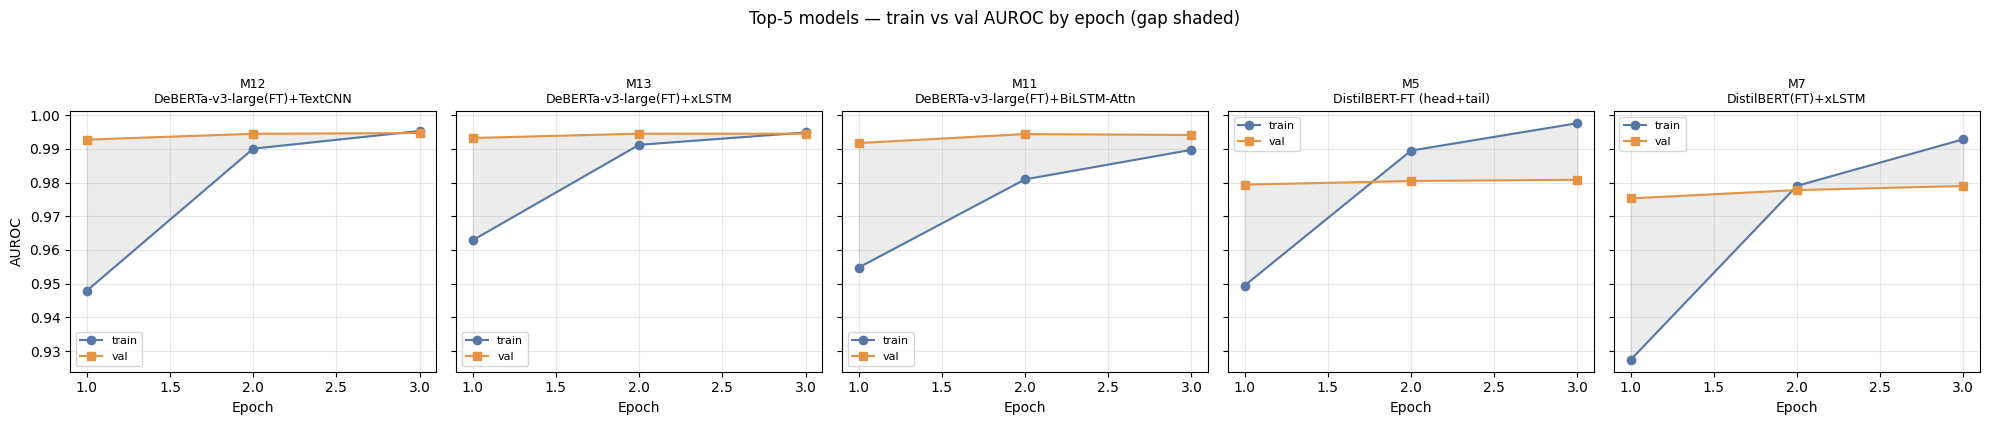

Audit complete.


In [ ]:

import hashlib

print("=" * 72)
print("OVERFITTING + LEAKAGE AUDIT")
print("=" * 72)


print("\n[1/5] Split disjointness by ID")
ids_tr  = set(df_train["id"].tolist())
ids_va  = set(df_val  ["id"].tolist())
ids_te  = set(df_test ["id"].tolist())
overlap_tv = ids_tr & ids_va
overlap_tt = ids_tr & ids_te
overlap_vt = ids_va & ids_te
print(f"  train ∩ val   : {len(overlap_tv)} IDs {'✓' if not overlap_tv else '✗ LEAK'}")
print(f"  train ∩ test  : {len(overlap_tt)} IDs {'✓' if not overlap_tt else '✗ LEAK'}")
print(f"  val   ∩ test  : {len(overlap_vt)} IDs {'✓' if not overlap_vt else '✗ LEAK'}")
print(f"  Sizes         : train={len(ids_tr)}  val={len(ids_va)}  test={len(ids_te)}")


print("\n[2/5] Split disjointness by hashed normalised text")
def _hash(s):
    s = " ".join(str(s).lower().split())   
    return hashlib.sha1(s.encode("utf-8")).hexdigest()
h_tr = set(df_train["text_A"].apply(_hash))
h_va = set(df_val  ["text_A"].apply(_hash))
h_te = set(df_test ["text_A"].apply(_hash))
hov_tv = len(h_tr & h_va); hov_tt = len(h_tr & h_te); hov_vt = len(h_va & h_te)
print(f"  train ∩ val   : {hov_tv} hash-equal reviews {'✓' if not hov_tv else '✗ NEAR-DUP LEAK'}")
print(f"  train ∩ test  : {hov_tt} hash-equal reviews {'✓' if not hov_tt else '✗ NEAR-DUP LEAK'}")
print(f"  val   ∩ test  : {hov_vt} hash-equal reviews {'✓' if not hov_vt else '✗ NEAR-DUP LEAK'}")

print("\n[3/5] Train vs val AUROC gap (overfitting flag)")
print("  Source: best-epoch values from each model's history dict.")
print(f"  {'Model':<48s} {'Tr AUC':>8s} {'Va AUC':>8s} {'Gap':>8s}  Flag")
overfit_flags = []
for name in sorted(all_histories.keys()):
    h = all_histories[name]
    if not h.get("tr_auc") or not h.get("va_auc"):
        print(f"  {name:<48s} {'—':>8s} {'—':>8s} {'—':>8s}  (no history)")
        continue
    best_ep = int(np.argmax(h["va_auc"]))
    tr_auc  = h["tr_auc"][best_ep]
    va_auc  = h["va_auc"][best_ep]
    gap     = tr_auc - va_auc
    if gap > 0.08:        flag = "✗ severe overfit"
    elif gap > 0.04:      flag = "△ mild overfit"
    elif gap < -0.02:     flag = "? underfit (rare)"
    else:                 flag = "✓"
    print(f"  {name:<48s} {tr_auc:>8.4f} {va_auc:>8.4f} {gap:>+8.4f}  {flag}")
    overfit_flags.append((name, gap, flag))

print("\n[4/5] Val vs test AUROC gap (val-set tuning leakage flag)")
print("  A large val>test gap means hyperparameter search overfit to the val split.")
print(f"  {'Model':<48s} {'Va AUC':>8s} {'Te AUC':>8s} {'Gap':>8s}  Flag")
y_va = df_val ["sentiment"].values
y_te = df_test["sentiment"].values
val_gap_flags = []
for name in sorted(predictions.keys()):
    if name not in val_preds:
        continue
    va_auc = roc_auc_score(y_va, val_preds[name])
    te_auc = roc_auc_score(y_te, predictions[name])
    gap    = va_auc - te_auc
    if abs(gap) > 0.03:   flag = "✗ large drift"
    elif abs(gap) > 0.015: flag = "△ moderate drift"
    else:                 flag = "✓"
    print(f"  {name:<48s} {va_auc:>8.4f} {te_auc:>8.4f} {gap:>+8.4f}  {flag}")
    val_gap_flags.append((name, gap, flag))

print("\n[5/5] Bootstrap 95% CI for test AUROC (n_resamples=1000)")
print("  Models whose CIs overlap are statistically indistinguishable.")
n_resamples = 1000
rng = np.random.default_rng(STUDENT_ID)
y_te = df_test["sentiment"].values
ci_rows = []
for name, probs in predictions.items():
    aucs = []
    for _ in range(n_resamples):
        idx = rng.choice(len(y_te), size=len(y_te), replace=True)
        if len(np.unique(y_te[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y_te[idx], probs[idx]))
    aucs = np.array(aucs)
    ci_rows.append({
        "Model": name,
        "Test AUROC": roc_auc_score(y_te, probs),
        "95% CI low":  np.percentile(aucs, 2.5),
        "95% CI high": np.percentile(aucs, 97.5),
        "CI width":    np.percentile(aucs, 97.5) - np.percentile(aucs, 2.5),
    })
ci_df = pd.DataFrame(ci_rows).sort_values("Test AUROC", ascending=False).round(4)
print(ci_df.to_string(index=False))

print("\n" + "=" * 72)
print("SUMMARY")
print("=" * 72)
n_overfit  = sum(1 for _, _, f in overfit_flags if "overfit" in f)
n_drift    = sum(1 for _, _, f in val_gap_flags if "drift" in f)
n_leak     = int(bool(overlap_tv or overlap_tt or overlap_vt or
                      hov_tv or hov_tt or hov_vt))
print(f"  Split leakage              : {'NONE ✓' if not n_leak else 'PRESENT ✗'}")
print(f"  Models flagged overfitting : {n_overfit}/{len(overfit_flags)}")
print(f"  Models flagged val-drift   : {n_drift}/{len(val_gap_flags)}")

print("\nRendering train-vs-val curves for the top-5 val-AUC models …")
top5 = [n for n, _ in
        sorted(((n, h.get("va_auc", [0])[-1]) for n, h in all_histories.items()),
               key=lambda x: x[1], reverse=True)[:5]]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, name in zip(axes, top5):
    h = all_histories[name]
    eps = range(1, len(h["tr_auc"]) + 1)
    ax.plot(eps, h["tr_auc"], "o-", label="train", color="#5778a4")
    ax.plot(eps, h["va_auc"], "s-", label="val",   color="#e49444")
    ax.fill_between(eps, h["tr_auc"], h["va_auc"], alpha=0.15, color="grey")
    ax.set_title(name.replace(" ", "\n", 1), fontsize=9)
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("AUROC")
plt.suptitle("Top-5 models — train vs val AUROC by epoch (gap shaded)",
             fontsize=12, y=1.05)
plt.tight_layout(); plt.savefig("fig_overfit_audit.png", dpi=150); plt.show()
print("Audit complete.")

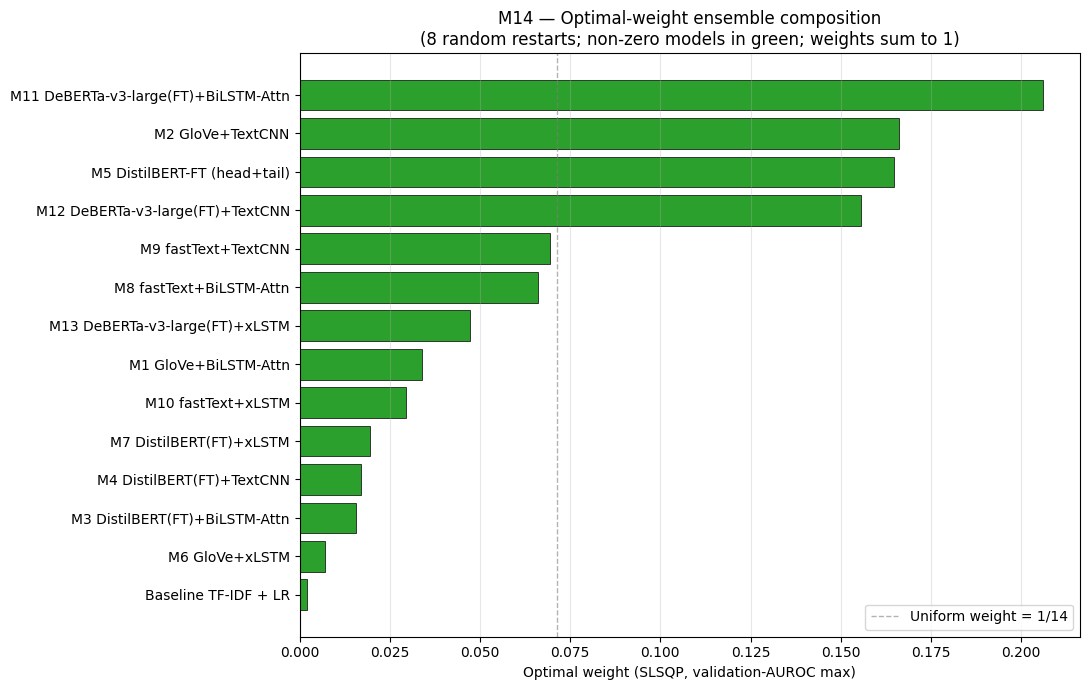


Sparse-weight interpretation (Caruana et al., 2004):
  Non-zero constituents : 14 / 14
  Top contributor       : M11 DeBERTa-v3-large(FT)+BiLSTM-Attn (w = 0.206)
  Models dropped (~0 w) : 0


In [ ]:

weight_df = pd.DataFrame({
    "Model":   ordered_names,
    "Weight":  w_slsqp,
    "Val AUC": [roc_auc_score(y_val, V[i]) for i in range(n_models)],
}).sort_values("Weight", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))
colors = ["#cccccc" if w < 1e-4 else "#2ca02c" for w in weight_df["Weight"]]
ax.barh(weight_df["Model"], weight_df["Weight"], color=colors,
        edgecolor="black", linewidth=0.5)
ax.set_xlabel("Optimal weight (SLSQP, validation-AUROC max)")
ax.set_title("M14 — Optimal-weight ensemble composition\n"
             f"(8 random restarts; non-zero models in green; weights sum to 1)",
             fontsize=12)
ax.axvline(1 / n_models, color="grey", linestyle="--", linewidth=1, alpha=0.6,
           label=f"Uniform weight = 1/{n_models}")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

print("\nSparse-weight interpretation (Caruana et al., 2004):")
print(f"  Non-zero constituents : {(w_slsqp > 1e-4).sum()} / {n_models}")
print(f"  Top contributor       : {weight_df.iloc[-1]['Model']} (w = {weight_df.iloc[-1]['Weight']:.3f})")
print(f"  Models dropped (~0 w) : {(w_slsqp < 1e-4).sum()}")


### Training curves — all 13 PyTorch models



In [ ]:


for res in [globals().get(f"res{i}") for i in range(1, 14)]:
    if res is not None and isinstance(res, dict) and "history" in res:
        all_histories.setdefault(res["name"], res["history"])

if "history_ft" in globals():
    all_histories.setdefault("M5 DistilBERT-FT (head+tail)", history_ft)

print(f"Histories registered for {len(all_histories)} models:")
for name in all_histories:
    print(f"  • {name}")


Histories registered for 13 models:
  • M3 DistilBERT(FT)+BiLSTM-Attn
  • M4 DistilBERT(FT)+TextCNN
  • M7 DistilBERT(FT)+xLSTM
  • M8 fastText+BiLSTM-Attn
  • M9 fastText+TextCNN
  • M10 fastText+xLSTM
  • M11 DeBERTa-v3-large(FT)+BiLSTM-Attn
  • M12 DeBERTa-v3-large(FT)+TextCNN
  • M13 DeBERTa-v3-large(FT)+xLSTM
  • M1 GloVe+BiLSTM-Attn
  • M2 GloVe+TextCNN
  • M5 DistilBERT-FT (head+tail)
  • M6 GloVe+xLSTM


## Q4 Evaluation



In [ ]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
    f1_score, precision_score, recall_score, matthews_corrcoef,
    cohen_kappa_score, brier_score_loss)

def evaluate_one(name, y_prob, y_true=df_test["sentiment"].values, thr=0.5):
    y_pred = (y_prob > thr).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    return {
        "model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUROC": roc_auc_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Cohen κ": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier": brier_score_loss(y_true, y_prob),
        "TN, FP, FN, TP": tuple(cm.ravel().tolist()),
    }

eval_table = pd.DataFrame([evaluate_one(n, p) for n, p in predictions.items()])
eval_table = eval_table.set_index("model").round(4)
eval_table.sort_values("AUROC", ascending=False)


,Accuracy,AUROC,Precision,Recall,F1,Cohen κ,MCC,Brier,"TN, FP, FN, TP"
model,,,,,,,,,
M12 DeBERTa-v3-large(FT)+TextCNN,0.9661,0.9927,0.9612,0.9713,0.9663,0.9321,0.9322,0.0331,"(1004, 41, 30, 1017)"
M11 DeBERTa-v3-large(FT)+BiLSTM-Attn,0.9651,0.9926,0.9568,0.9742,0.9655,0.9302,0.9304,0.0330,"(999, 46, 27, 1020)"
M13 DeBERTa-v3-large(FT)+xLSTM,0.9618,0.9923,0.9456,0.9799,0.9625,0.9235,0.9241,0.0380,"(986, 59, 21, 1026)"
M14 Optimal-weight Ensemble (SLSQP),0.9637,0.9886,0.9550,0.9733,0.9640,0.9273,0.9275,0.0336,"(997, 48, 28, 1019)"
M7 DistilBERT(FT)+xLSTM,0.9417,0.9838,0.9384,0.9456,0.9420,0.8834,0.8834,0.0547,"(980, 65, 57, 990)"
M5 DistilBERT-FT (head+tail),0.9374,0.9835,0.9313,0.9446,0.9379,0.8748,0.8748,0.0527,"(972, 73, 58, 989)"
M4 DistilBERT(FT)+TextCNN,0.9302,0.9825,0.9026,0.9647,0.9326,0.8604,0.8625,0.0604,"(936, 109, 37, 1010)"
M3 DistilBERT(FT)+BiLSTM-Attn,0.9288,0.9798,0.9112,0.9503,0.9303,0.8575,0.8583,0.0586,"(948, 97, 52, 995)"
Baseline TF-IDF + LR,0.9097,0.9709,0.8994,0.9226,0.9109,0.8193,0.8196,0.0721,"(937, 108, 81, 966)"


In [ ]:

def bootstrap_auc_ci(y_true, y_prob, n=1000, seed=STUDENT_ID):
    rng = np.random.default_rng(seed)
    aucs = []
    n_obs = len(y_true)
    for _ in range(n):
        idx = rng.integers(0, n_obs, n_obs)
        if len(set(y_true[idx])) < 2:  
            continue
        aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])

auc_ci = {}
for name, prob in predictions.items():
    lo, hi = bootstrap_auc_ci(df_test["sentiment"].values, prob)
    auc_ci[name] = (lo, hi)
auc_ci_df = pd.DataFrame(auc_ci, index=["AUC 2.5%", "AUC 97.5%"]).T.round(4)
auc_ci_df


,AUC 2.5%,AUC 97.5%
Baseline TF-IDF + LR,0.9649,0.9765
M1 GloVe+BiLSTM-Attn,0.9580,0.9714
M2 GloVe+TextCNN,0.9442,0.9612
M3 DistilBERT(FT)+BiLSTM-Attn,0.9741,0.9848
M4 DistilBERT(FT)+TextCNN,0.9776,0.9867
M5 DistilBERT-FT (head+tail),0.9786,0.9875
M6 GloVe+xLSTM,0.9422,0.9594
M7 DistilBERT(FT)+xLSTM,0.9789,0.9876
M8 fastText+BiLSTM-Attn,0.9585,0.9718
M9 fastText+TextCNN,0.9432,0.9602


###  Combined ROC plot (brief deliverable)



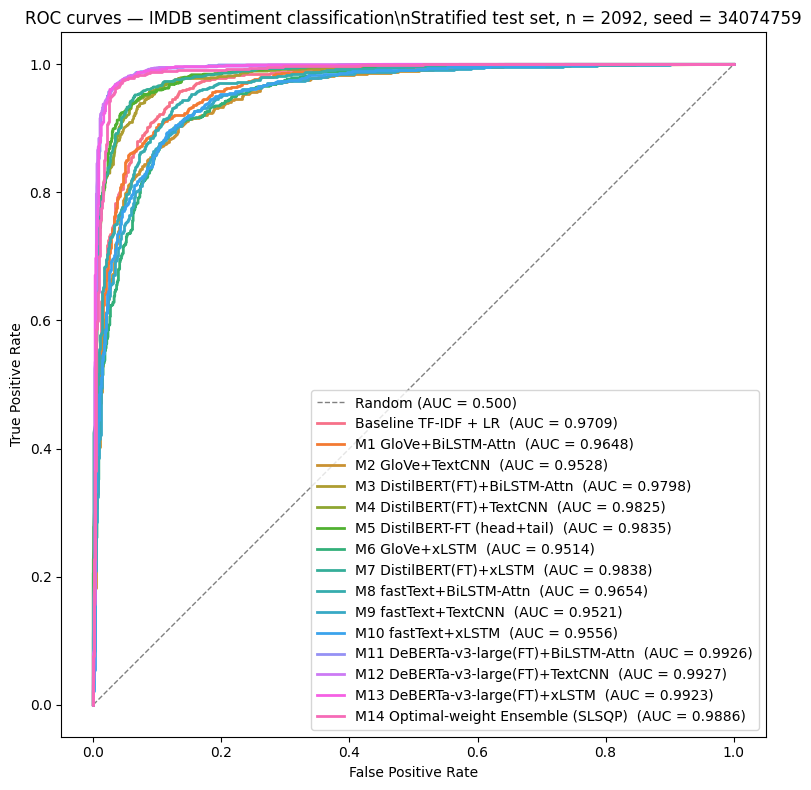

In [ ]:
y_test = df_test["sentiment"].values
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random (AUC = 0.500)")
palette = sns.color_palette("husl", n_colors=len(predictions))
for (name, prob), color in zip(predictions.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{name}  (AUC = {auc:.4f})")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — IMDB sentiment classification\\n"
             f"Stratified test set, n = {len(y_test)}, "
             f"seed = {STUDENT_ID}")
ax.legend(loc="lower right"); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig("fig_combined_roc.png", dpi=150); plt.show()


### Precision-Recall curves

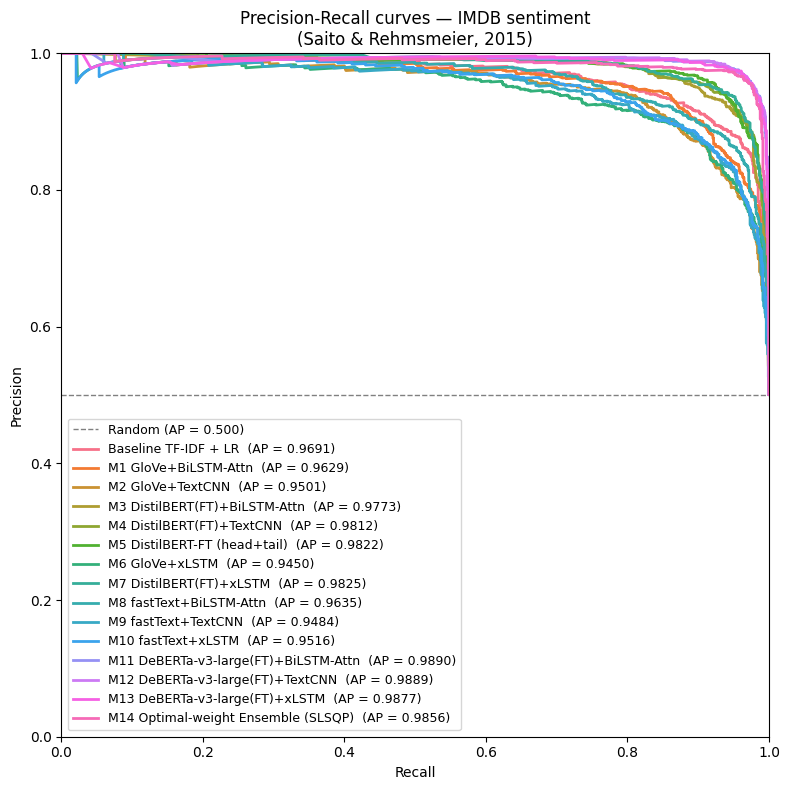

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(8, 8))
baseline_ap = df_test["sentiment"].mean()  # random classifier baseline
ax.axhline(baseline_ap, ls="--", color="grey", lw=1,
           label=f"Random (AP = {baseline_ap:.3f})")

palette = sns.color_palette("husl", n_colors=len(predictions))
for (name, prob), color in zip(predictions.items(), palette):
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax.plot(rec, prec, color=color, lw=2,
            label=f"{name}  (AP = {ap:.4f})")

ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curves — IMDB sentiment\n"
             "(Saito & Rehmsmeier, 2015)")
ax.legend(loc="lower left", fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("fig_pr_curves.png", dpi=150)
plt.show()

###  Confusion matrices (brief deliverable)



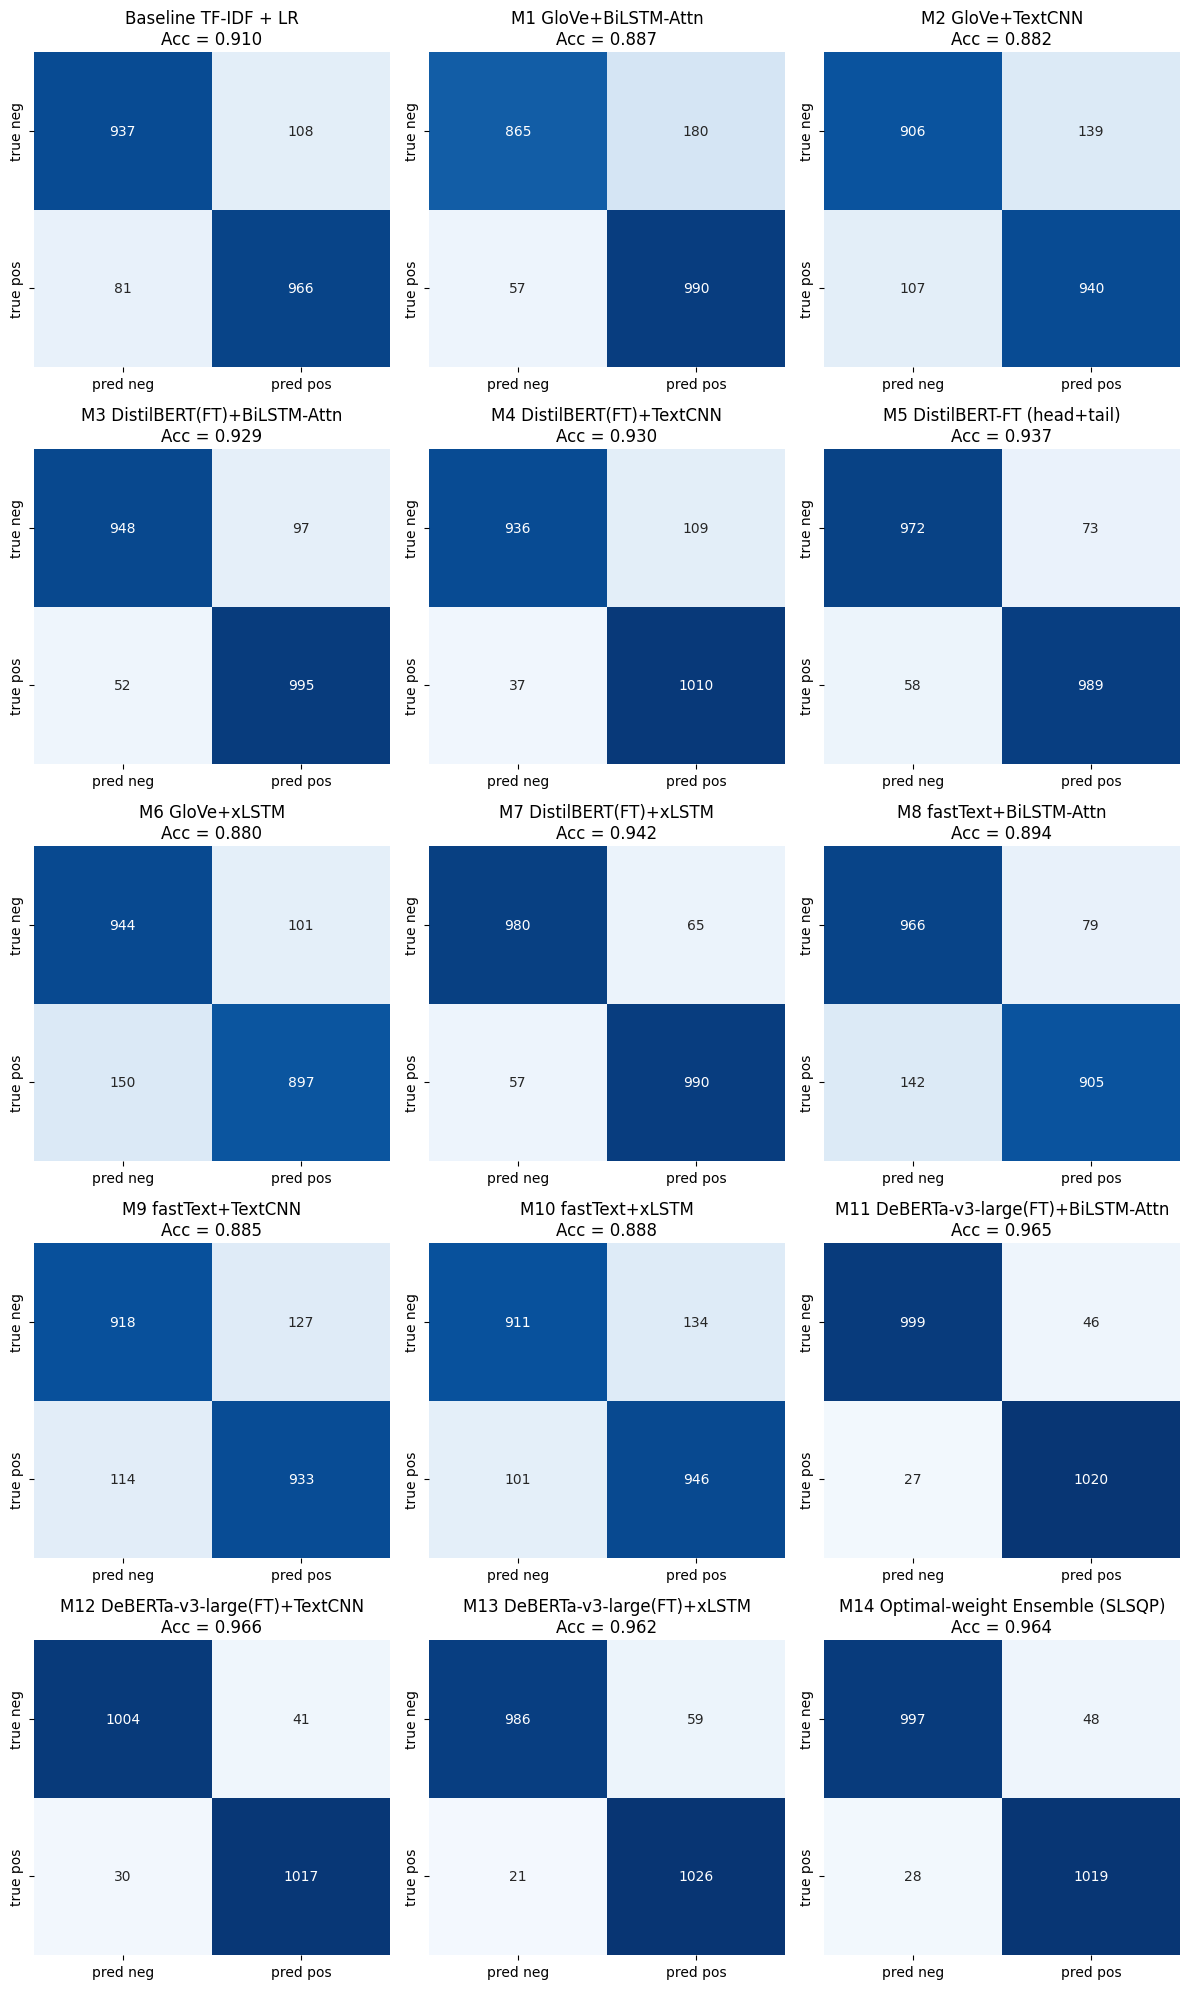

In [ ]:
n_models = len(predictions)
n_cols = 3; n_rows = math.ceil(n_models / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4))
axes = axes.flatten()
for ax, (name, prob) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, (prob > 0.5).astype(int))
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
                xticklabels=["pred neg", "pred pos"],
                yticklabels=["true neg", "true pos"],
                cbar=False, ax=ax, vmin=0, vmax=1)
    ax.set_title(f"{name}\nAcc = {accuracy_score(y_test, (prob > 0.5).astype(int)):.3f}")
for ax in axes[len(predictions):]:
    ax.set_visible(False)
plt.tight_layout(); plt.savefig("fig_confmats.png", dpi=150); plt.show()


### Predicted-probability distributions — confidence diagnostics


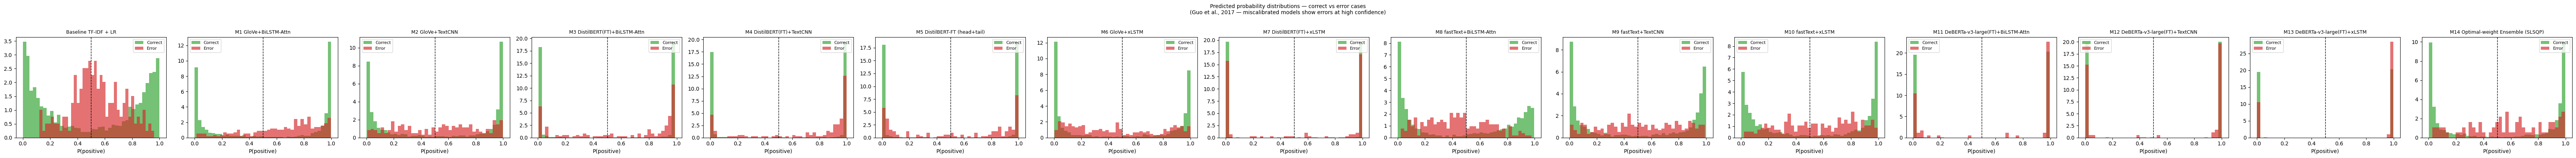

In [ ]:
fig, axes = plt.subplots(1, len(predictions), figsize=(4.5 * len(predictions), 4),
                          sharey=False)
if len(predictions) == 1:
    axes = [axes]

for ax, (name, prob) in zip(axes, predictions.items()):
    y_pred = (prob > 0.5).astype(int)
    correct_mask = (y_pred == y_test)

    ax.hist(prob[correct_mask],  bins=40, alpha=0.65,
            color="#2ca02c", label="Correct", density=True)
    ax.hist(prob[~correct_mask], bins=40, alpha=0.65,
            color="#d62728", label="Error", density=True)
    ax.axvline(0.5, ls="--", color="black", lw=1)
    ax.set_xlabel("P(positive)")
    ax.set_title(f"{name}", fontsize=9)
    ax.legend(fontsize=8)

plt.suptitle("Predicted probability distributions — correct vs error cases\n"
             "(Guo et al., 2017 — miscalibrated models show errors at high confidence)",
             fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig("fig_confidence_dist.png", dpi=150, bbox_inches="tight")
plt.show()

### Statistical comparison — McNemar's paired test

In [ ]:
try:
    from statsmodels.stats.contingency_tables import mcnemar
    use_sm = True
except ImportError:
    use_sm = False
    print("statsmodels not installed — using manual chi-square implementation")

def mcnemar_pair(p1, p2, y, thr=0.5):
    pred1 = (p1 > thr).astype(int) == y.astype(int)
    pred2 = (p2 > thr).astype(int) == y.astype(int)
    b = int(((~pred1) & ( pred2)).sum())  # 1 wrong, 2 right
    c = int(( pred1  & (~pred2)).sum())   # 1 right, 2 wrong
    if use_sm:
        res = mcnemar([[0, b], [c, 0]], exact=False, correction=True)
        return res.statistic, res.pvalue, b, c
    chi2 = (abs(b - c) - 1) ** 2 / max(b + c, 1)
    from scipy.stats import chi2 as chi2_dist
    p = 1 - chi2_dist.cdf(chi2, df=1)
    return chi2, p, b, c

names = list(predictions.keys())
mat = pd.DataFrame(index=names, columns=names, dtype=object)
for i, a in enumerate(names):
    for j, b in enumerate(names):
        if i == j:
            mat.loc[a, b] = "—"
        elif i < j:
            chi2, p, ba, bb = mcnemar_pair(predictions[a], predictions[b], y_test)
            mat.loc[a, b] = f"χ²={chi2:.2f}, p={p:.3g}"
            mat.loc[b, a] = mat.loc[a, b]
mat


,Baseline TF-IDF + LR,M1 GloVe+BiLSTM-Attn,M2 GloVe+TextCNN,M3 DistilBERT(FT)+BiLSTM-Attn,M4 DistilBERT(FT)+TextCNN,M5 DistilBERT-FT (head+tail),M6 GloVe+xLSTM,M7 DistilBERT(FT)+xLSTM,M8 fastText+BiLSTM-Attn,M9 fastText+TextCNN,M10 fastText+xLSTM,M11 DeBERTa-v3-large(FT)+BiLSTM-Attn,M12 DeBERTa-v3-large(FT)+TextCNN,M13 DeBERTa-v3-large(FT)+xLSTM,M14 Optimal-weight Ensemble (SLSQP)
Baseline TF-IDF + LR,—,"χ²=12.41, p=0.000427","χ²=15.76, p=7.2e-05","χ²=8.18, p=0.00424","χ²=9.75, p=0.0018","χ²=16.58, p=4.67e-05","χ²=17.89, p=2.34e-05","χ²=22.81, p=1.79e-06","χ²=6.08, p=0.0137","χ²=13.27, p=0.00027","χ²=12.82, p=0.000344","χ²=70.35, p=4.98e-17","χ²=73.60, p=9.58e-18","χ²=65.16, p=6.9e-16","χ²=76.02, p=2.8e-18"
M1 GloVe+BiLSTM-Attn,"χ²=12.41, p=0.000427",—,"χ²=0.35, p=0.554","χ²=36.39, p=1.62e-09","χ²=36.99, p=1.19e-09","χ²=47.52, p=5.44e-12","χ²=0.69, p=0.407","χ²=58.28, p=2.28e-14","χ²=1.03, p=0.31","χ²=0.04, p=0.836","χ²=0.01, p=0.942","χ²=118.61, p=1.27e-27","χ²=120.46, p=5.01e-28","χ²=113.19, p=1.96e-26","χ²=127.36, p=1.55e-29"
M2 GloVe+TextCNN,"χ²=15.76, p=7.2e-05","χ²=0.35, p=0.554",—,"χ²=40.60, p=1.87e-10","χ²=41.88, p=9.68e-11","χ²=55.78, p=8.12e-14","χ²=0.08, p=0.783","χ²=65.78, p=5.05e-16","χ²=2.78, p=0.0953","χ²=0.11, p=0.74","χ²=0.45, p=0.503","χ²=128.07, p=1.08e-29","χ²=132.21, p=1.35e-30","χ²=119.41, p=8.53e-28","χ²=141.39, p=1.32e-32"
M3 DistilBERT(FT)+BiLSTM-Attn,"χ²=8.18, p=0.00424","χ²=36.39, p=1.62e-09","χ²=40.60, p=1.87e-10",—,"χ²=0.05, p=0.822","χ²=3.71, p=0.0542","χ²=45.14, p=1.84e-11","χ²=7.27, p=0.00702","χ²=21.36, p=3.81e-06","χ²=36.00, p=1.97e-09","χ²=31.69, p=1.81e-08","χ²=49.34, p=2.15e-12","χ²=48.60, p=3.14e-12","χ²=41.66, p=1.09e-10","χ²=53.44, p=2.66e-13"
M4 DistilBERT(FT)+TextCNN,"χ²=9.75, p=0.0018","χ²=36.99, p=1.19e-09","χ²=41.88, p=9.68e-11","χ²=0.05, p=0.822",—,"χ²=2.20, p=0.138","χ²=42.09, p=8.74e-11","χ²=5.88, p=0.0153","χ²=22.53, p=2.06e-06","χ²=38.93, p=4.4e-10","χ²=33.52, p=7.04e-09","χ²=45.08, p=1.89e-11","χ²=44.52, p=2.52e-11","χ²=39.12, p=3.98e-10","χ²=46.68, p=8.37e-12"
M5 DistilBERT-FT (head+tail),"χ²=16.58, p=4.67e-05","χ²=47.52, p=5.44e-12","χ²=55.78, p=8.12e-14","χ²=3.71, p=0.0542","χ²=2.20, p=0.138",—,"χ²=59.50, p=1.22e-14","χ²=0.98, p=0.321","χ²=33.00, p=9.2e-09","χ²=53.04, p=3.27e-13","χ²=43.48, p=4.28e-11","χ²=33.84, p=5.97e-09","χ²=33.47, p=7.23e-09","χ²=26.32, p=2.9e-07","χ²=37.87, p=7.56e-10"
M6 GloVe+xLSTM,"χ²=17.89, p=2.34e-05","χ²=0.69, p=0.407","χ²=0.08, p=0.783","χ²=45.14, p=1.84e-11","χ²=42.09, p=8.74e-11","χ²=59.50, p=1.22e-14",—,"χ²=67.42, p=2.19e-16","χ²=4.08, p=0.0433","χ²=0.37, p=0.542","χ²=1.01, p=0.314","χ²=130.54, p=3.13e-30","χ²=139.31, p=3.77e-32","χ²=120.92, p=3.98e-28","χ²=138.25, p=6.44e-32"
M7 DistilBERT(FT)+xLSTM,"χ²=22.81, p=1.79e-06","χ²=58.28, p=2.28e-14","χ²=65.78, p=5.05e-16","χ²=7.27, p=0.00702","χ²=5.88, p=0.0153","χ²=0.98, p=0.321","χ²=67.42, p=2.19e-16",—,"χ²=40.52, p=1.94e-10","χ²=63.58, p=1.54e-15","χ²=52.49, p=4.33e-13","χ²=23.75, p=1.1e-06","χ²=24.27, p=8.37e-07","χ²=18.27, p=1.92e-05","χ²=24.11, p=9.11e-07"
M8 fastText+BiLSTM-Attn,"χ²=6.08, p=0.0137","χ²=1.03, p=0.31","χ²=2.78, p=0.0953","χ²=21.36, p=3.81e-06","χ²=22.53, p=2.06e-06","χ²=33.00, p=9.2e-09","χ²=4.08, p=0.0433","χ²=40.52, p=1.94e-10",—,"χ²=1.80, p=0.179","χ²=0.92, p=0.338","χ²=96.47, p=9.07e-23","χ²=101.84, p=6.02e-24","χ²=87.89, p=6.91e-21","χ²=101.15, p=8.52e-24"
M9 fastText+TextCNN,"χ²=13.27, p=0.00027","χ²=0.04, p=0.836","χ²=0.11, p=0.74","χ²=36.00, p=1.97e-09","χ²=38.93, p=4.4e-10","χ²=53.04, p=3.27e-13","χ²=0.37, p=0.542","χ²=63.58, p=1.54e-15","χ²=1.80, p=0.179",—,"χ²=0.11, p=0.735","χ²=118.17, p=1.59e-27","χ²=125.27, p=4.45e-29","χ²=112.78, p=2.42e-26","χ²=129.93, p=4.24e-30"


### Model comparison — grouped metric bar chart


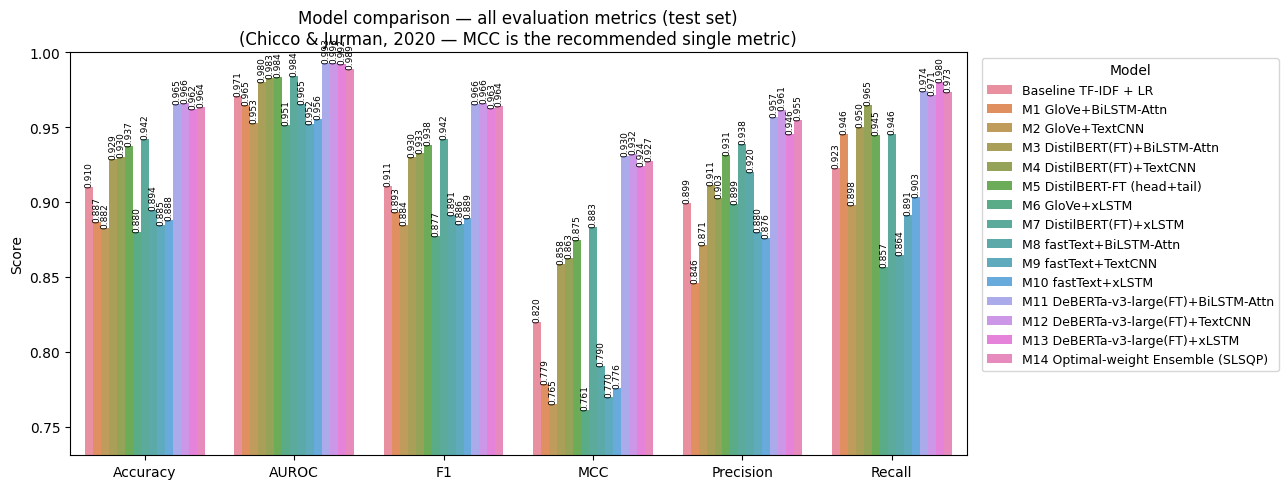


Full evaluation table — sorted by AUROC:
                                      Accuracy   AUROC  Precision  Recall      F1  Cohen κ     MCC   Brier        TN, FP, FN, TP
model                                                                                                                           
M12 DeBERTa-v3-large(FT)+TextCNN        0.9661  0.9927     0.9612  0.9713  0.9663   0.9321  0.9322  0.0331  (1004, 41, 30, 1017)
M11 DeBERTa-v3-large(FT)+BiLSTM-Attn    0.9651  0.9926     0.9568  0.9742  0.9655   0.9302  0.9304  0.0330   (999, 46, 27, 1020)
M13 DeBERTa-v3-large(FT)+xLSTM          0.9618  0.9923     0.9456  0.9799  0.9625   0.9235  0.9241  0.0380   (986, 59, 21, 1026)
M14 Optimal-weight Ensemble (SLSQP)     0.9637  0.9886     0.9550  0.9733  0.9640   0.9273  0.9275  0.0336   (997, 48, 28, 1019)
M7 DistilBERT(FT)+xLSTM                 0.9417  0.9838     0.9384  0.9456  0.9420   0.8834  0.8834  0.0547    (980, 65, 57, 990)
M5 DistilBERT-FT (head+tail)            0.9374  0.9835 

In [ ]:
metrics_to_plot = ["Accuracy", "AUROC", "F1", "MCC", "Precision", "Recall"]
plot_df = eval_table.reset_index()[["model"] + metrics_to_plot].copy()
plot_df_melt = plot_df.melt(id_vars="model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(13, 5))
palette = sns.color_palette("husl", n_colors=len(predictions))
sns.barplot(data=plot_df_melt, x="Metric", y="Score",
            hue="model", palette=palette, ax=ax, alpha=0.88)

ax.set_ylim(plot_df_melt["Score"].min() - 0.03, 1.0)
ax.axhline(0.5, ls="--", color="grey", lw=0.8, alpha=0.6)
ax.set_xlabel(""); ax.set_ylabel("Score")
ax.set_title("Model comparison — all evaluation metrics (test set)\n"
             "(Chicco & Jurman, 2020 — MCC is the recommended single metric)")
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)

# Annotate bars with values
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.3f}",
                    (p.get_x() + p.get_width() / 2, height),
                    ha="center", va="bottom", fontsize=6.5, rotation=90)

plt.tight_layout()
plt.savefig("fig_model_comparison_bars.png", dpi=150, bbox_inches="tight")
plt.show()

# Also print a ranked table
print("\nFull evaluation table — sorted by AUROC:")
print(eval_table.sort_values("AUROC", ascending=False).to_string())

### Best embedding configuration — detailed architecture report


###  Visual architecture diagram — best-embedding configuration

Drawing architecture diagram for: M12 DeBERTa-v3-large(FT)+TextCNN
  val AUC = 0.9946


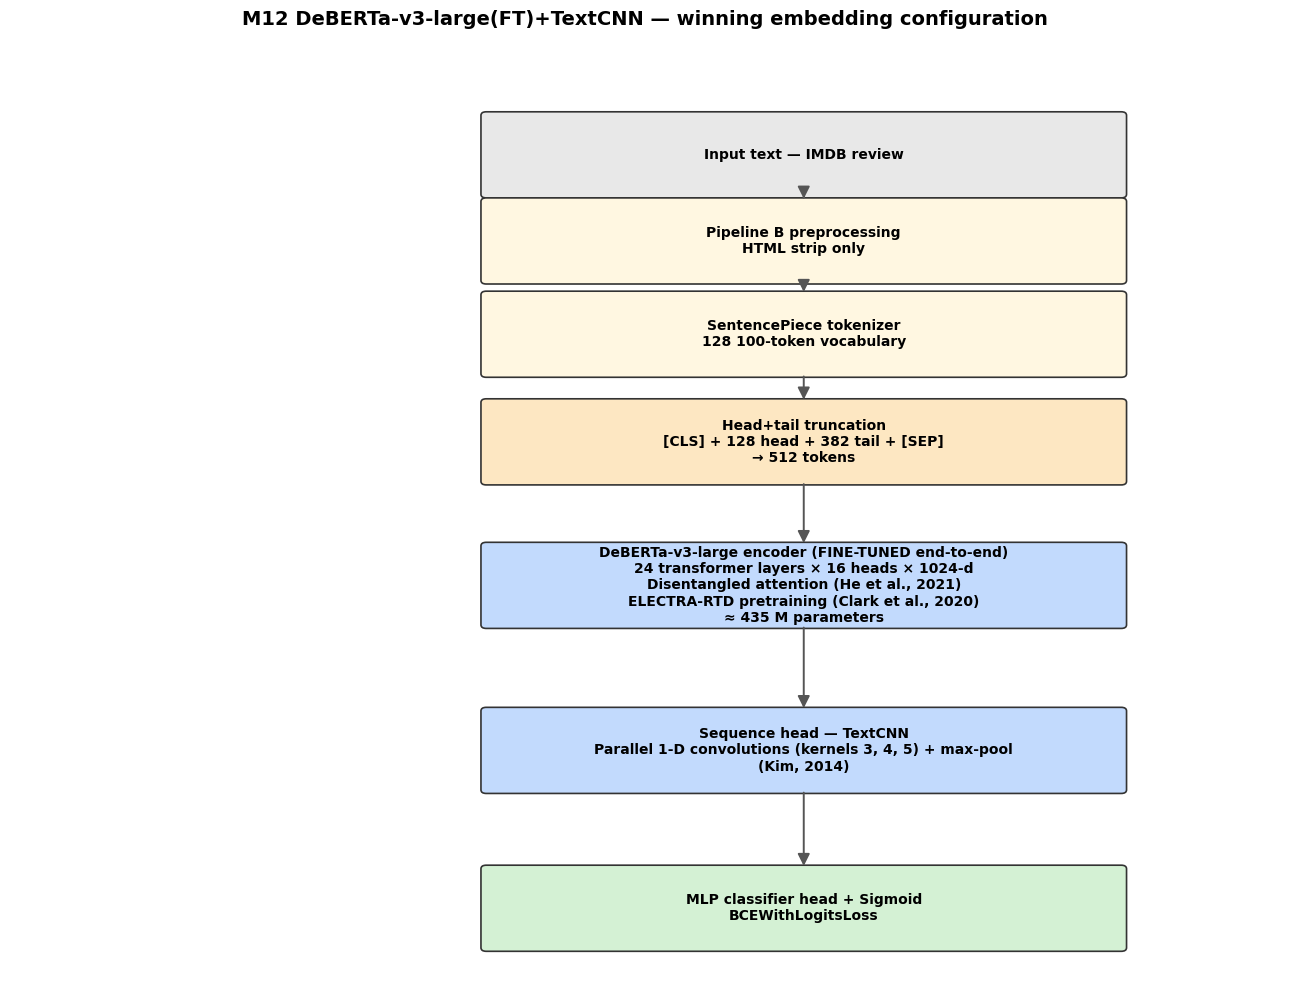


Diagram rendered for the winning model: M12 DeBERTa-v3-large(FT)+TextCNN


In [ ]:


import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


_single_val = {k: v for k, v in val_preds.items() if "Ensemble" not in k}
best_name = max(_single_val, key=lambda k: roc_auc_score(y_val_arr, _single_val[k]))
print(f"Drawing architecture diagram for: {best_name}")
print(f"  val AUC = {roc_auc_score(y_val_arr, _single_val[best_name]):.4f}")

def _boxes_glove(emb_name, head_name, head_desc):
    return [
        ("Input text — IMDB review",                                       11.5, "#e8e8e8"),
        ("Pipeline A preprocessing\nlowercase, punct., stopwords, lemmatise", 10.3, "#fff7e1"),
        ("Whitespace tokeniser\n→ token-id sequence (max 400)",            9.0, "#fff7e1"),
        (f"{emb_name} embedding layer\n200 / 300-d static vectors\n(freeze toggled via Optuna)",
                                                                            7.5, "#c2dafd"),
        (head_desc,                                                         5.5, "#c2dafd"),
        ("MLP classifier head\nLinear → ReLU → Dropout → Linear → Sigmoid", 3.2, "#d4f1d4"),
        ("P(positive)\nBCEWithLogitsLoss",                                  1.0, "#d4f1d4"),
    ]

def _boxes_distilbert(head_name, head_desc):
    enc_text = ("DistilBERT-base encoder (FINE-TUNED end-to-end)\n"
                "6 transformer layers × 12 heads × 768-d\n"
                "≈ 66 M parameters (Sanh et al., 2019)")
    return [
        ("Input text — IMDB review",                                  11.5, "#e8e8e8"),
        ("Pipeline B preprocessing\nHTML strip only (Sun et al., 2019)", 10.3, "#fff7e1"),
        ("WordPiece tokenizer\n30 522-token vocabulary",              9.0, "#fff7e1"),
        ("Head+tail truncation\n[CLS] + 128 head + 382 tail + [SEP]\n→ 512 tokens",
                                                                       7.5, "#fde7c2"),
        (enc_text,                                                     5.5, "#c2dafd"),
        (head_desc,                                                    3.2, "#c2dafd"),
        ("MLP classifier head + Sigmoid\nBCEWithLogitsLoss",          1.0, "#d4f1d4"),
    ]

def _boxes_deberta(head_name, head_desc):
    return [
        ("Input text — IMDB review",                      11.5, "#e8e8e8"),
        ("Pipeline B preprocessing\nHTML strip only",                10.3, "#fff7e1"),
        ("SentencePiece tokenizer\n128 100-token vocabulary",          9.0, "#fff7e1"),
        ("Head+tail truncation\n[CLS] + 128 head + 382 tail + [SEP]\n→ 512 tokens",      7.5, "#fde7c2"),
        ("DeBERTa-v3-large encoder (FINE-TUNED end-to-end)\n"
         "24 transformer layers × 16 heads × 1024-d\n"
         "Disentangled attention (He et al., 2021)\n"
         "ELECTRA-RTD pretraining (Clark et al., 2020)\n"
         "≈ 435 M parameters",                                                          5.5, "#c2dafd"),
        (head_desc,                                                                     3.2, "#c2dafd"),
        ("MLP classifier head + Sigmoid\nBCEWithLogitsLoss",                            1.0, "#d4f1d4"),
    ]

def _boxes_m5():
    return [
        ("Input text — IMDB review",                                       11.5, "#e8e8e8"),
        ("Pipeline B preprocessing\nHTML strip only (Sun et al., 2019)", 10.3, "#fff7e1"),
        ("WordPiece tokenizer\n30 522-token vocabulary",                  9.0, "#fff7e1"),
        ("Head+tail truncation\n[CLS] + 128 head + 382 tail + [SEP]\n→ 512 tokens",
                                                                            7.5, "#fde7c2"),
        ("DistilBERT-base encoder (FINE-TUNED end-to-end)\n"
         "6 transformer layers × 12 heads × 768-d\n"
         "≈ 66 M parameters (Sanh et al., 2019)",                          5.5, "#c2dafd"),
        ("[CLS] token pooling\n→ 768-d vector",                            3.5, "#c2dafd"),
        ("Linear classifier head\nDropout(0.1) → Linear(768 → 2)\nSoftmax → P(positive)", 1.5, "#d4f1d4"),
    ]


_BILSTM = "Sequence head — BiLSTM-Attention\n2 stacked BiLSTM layers + additive attention\n(Hochreiter & Schmidhuber 1997; Bahdanau et al. 2015)"
_TEXTCNN = "Sequence head — TextCNN\nParallel 1-D convolutions (kernels 3, 4, 5) + max-pool\n(Kim, 2014)"
_XLSTM = "Sequence head — xLSTM\nMatrix-memory recurrent stack\n(Beck et al., 2024)"

if "GloVe+BiLSTM" in best_name:
    boxes = _boxes_glove("GloVe-200d (Pennington 2014)",     "BiLSTM-Attn", _BILSTM)
elif "GloVe+TextCNN" in best_name:
    boxes = _boxes_glove("GloVe-200d (Pennington 2014)",     "TextCNN",     _TEXTCNN)
elif "GloVe+xLSTM" in best_name:
    boxes = _boxes_glove("GloVe-200d (Pennington 2014)",     "xLSTM",       _XLSTM)
elif "fastText+BiLSTM" in best_name:
    boxes = _boxes_glove("fastText-300d (Bojanowski 2017)",  "BiLSTM-Attn", _BILSTM)
elif "fastText+TextCNN" in best_name:
    boxes = _boxes_glove("fastText-300d (Bojanowski 2017)",  "TextCNN",     _TEXTCNN)
elif "fastText+xLSTM" in best_name:
    boxes = _boxes_glove("fastText-300d (Bojanowski 2017)",  "xLSTM",       _XLSTM)
elif "M3 DistilBERT" in best_name:
    boxes = _boxes_distilbert("BiLSTM-Attn", _BILSTM)
elif "M4 DistilBERT" in best_name:
    boxes = _boxes_distilbert("TextCNN",     _TEXTCNN)
elif "M7 DistilBERT" in best_name:
    boxes = _boxes_distilbert("xLSTM",       _XLSTM)
elif "M5 DistilBERT" in best_name:
    boxes = _boxes_m5()
elif "M11 DeBERTa" in best_name:
    boxes = _boxes_deberta("BiLSTM-Attn", _BILSTM)
elif "M12 DeBERTa" in best_name:
    boxes = _boxes_deberta("TextCNN",     _TEXTCNN)
elif "M13 DeBERTa" in best_name:
    boxes = _boxes_deberta("xLSTM",       _XLSTM)
else:
    raise ValueError(f"No diagram template for: {best_name}")

title = f"{best_name} — winning embedding configuration"


fig, ax = plt.subplots(figsize=(13, 10))
ax.set_xlim(0, 12); ax.set_ylim(0, 13); ax.axis("off")
ax.set_title(title, fontsize=14, fontweight="bold", pad=16)
xc = 4.5; box_w = 6
for txt, y, color in boxes:
    box = FancyBboxPatch((xc, y - 0.55), box_w, 1.1,
                         boxstyle="round,pad=0.05",
                         linewidth=1.2, edgecolor="#333333", facecolor=color)
    ax.add_patch(box)
    ax.text(xc + box_w / 2, y, txt, ha="center", va="center",
            fontsize=10, fontweight="bold")
for i in range(len(boxes) - 1):
    y_from = boxes[i][1] - 0.55
    y_to   = boxes[i + 1][1] + 0.55
    arrow = FancyArrowPatch((xc + box_w / 2, y_from),
                            (xc + box_w / 2, y_to),
                            arrowstyle="-|>", mutation_scale=18,
                            linewidth=1.4, color="#555555")
    ax.add_patch(arrow)
plt.tight_layout(); plt.savefig("fig_architecture_diagram.png", dpi=150)
plt.show()
print(f"\nDiagram rendered for the winning model: {best_name}")


results_lookup populated with 13 single models
Best single model (selected on VAL, not test): M12 DeBERTa-v3-large(FT)+TextCNN
  val AUC : 0.9947
  test AUC: 0.9927
  test Acc: 0.9661
  95% CI  : (np.float64(0.9885608022415066), np.float64(0.9956870086440133))


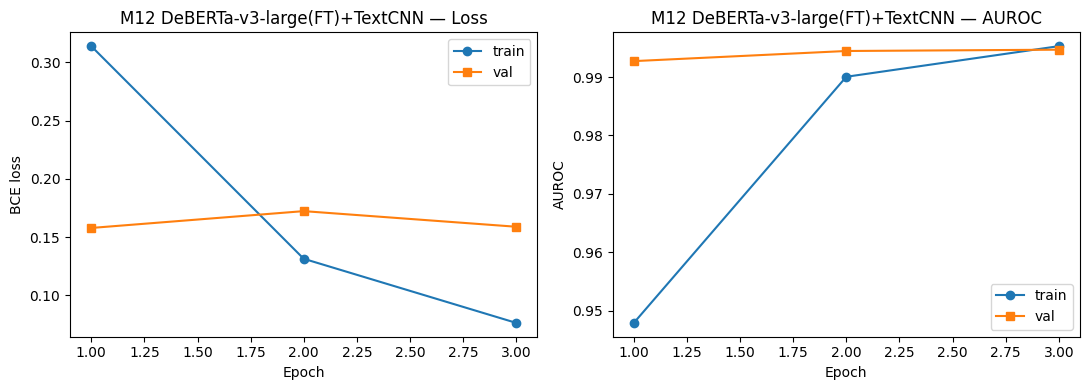

In [ ]:


results_lookup = {}
for vn in ["res1","res2","res3","res4","res6","res7",
          "res8","res9","res10","res11","res12","res13"]:
    r = globals().get(vn)
    if r is not None and isinstance(r, dict) and "best_val_auc" in r:
        results_lookup[r["name"]] = r

for vn in ["res5", "history_ft"]:
    if vn in globals():
        if vn == "res5" and isinstance(globals()[vn], dict):
            results_lookup["M5 DistilBERT-FT (head+tail)"] = globals()[vn]
print(f"results_lookup populated with {len(results_lookup)} single models")


if "M5 DistilBERT-FT (head+tail)" not in results_lookup and "history_ft" in globals():
    results_lookup["M5 DistilBERT-FT (head+tail)"] = {
        "name": "M5 DistilBERT-FT (head+tail)",
        "history": history_ft,
        "best_val_auc": max(history_ft.get("va_auc", [0.0])),
    }

best_name = max(results_lookup, key=lambda k: results_lookup[k]["best_val_auc"])
best_prob = predictions[best_name]
print(f"Best single model (selected on VAL, not test): {best_name}")
print(f"  val AUC : {results_lookup[best_name]['best_val_auc']:.4f}")
print(f"  test AUC: {roc_auc_score(y_test, best_prob):.4f}")
print(f"  test Acc: {accuracy_score(y_test, (best_prob > 0.5).astype(int)):.4f}")
if best_name in auc_ci:
    print(f"  95% CI  : {auc_ci[best_name]}")


h = results_lookup[best_name]["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(h["tr_loss"]) + 1)
axes[0].plot(epochs, h["tr_loss"], "o-", label="train")
axes[0].plot(epochs, h["va_loss"], "s-", label="val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss")
axes[0].set_title(f"{best_name} — Loss"); axes[0].legend()
axes[1].plot(epochs, h["tr_auc"], "o-", label="train")
axes[1].plot(epochs, h["va_auc"], "s-", label="val")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC")
axes[1].set_title(f"{best_name} — AUROC"); axes[1].legend()
plt.tight_layout(); plt.savefig("fig_best_curves.png", dpi=150); plt.show()


###  Calibration — reliability diagram and Brier scores



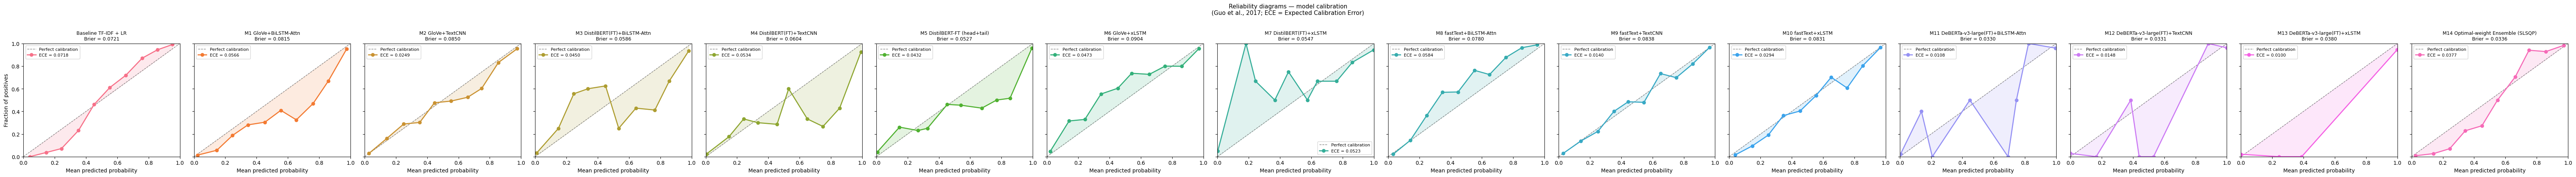

In [ ]:
from sklearn.calibration import calibration_curve

n_models = len(predictions)
fig, axes = plt.subplots(1, n_models, figsize=(4.5 * n_models, 4.5), sharey=True)
if n_models == 1:
    axes = [axes]

N_BINS = 10
palette = sns.color_palette("husl", n_colors=n_models)

for ax, (name, prob), color in zip(axes, predictions.items(), palette):
    frac_pos, mean_pred = calibration_curve(y_test, prob,
                                             n_bins=N_BINS, strategy="uniform")
    # ECE: weighted mean absolute deviation from diagonal
    bin_counts, bin_edges = np.histogram(prob, bins=N_BINS, range=(0,1))
    weights = bin_counts / bin_counts.sum()
    ece_val  = float(np.sum(weights[:len(frac_pos)] *
                            np.abs(frac_pos - mean_pred)))

    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Perfect calibration")
    ax.plot(mean_pred, frac_pos, "o-", color=color, lw=2,
            ms=6, label=f"ECE = {ece_val:.4f}")
    ax.fill_between(mean_pred, frac_pos, mean_pred,
                    alpha=0.15, color=color)
    brier = float(evaluate_one(name, prob)["Brier"])
    ax.set_title(f"{name}\nBrier = {brier:.4f}", fontsize=9)
    ax.set_xlabel("Mean predicted probability")
    ax.legend(fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

axes[0].set_ylabel("Fraction of positives")
plt.suptitle("Reliability diagrams — model calibration\n"
             "(Guo et al., 2017; ECE = Expected Calibration Error)",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig("fig_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

###  Error analysis


              n     acc
len_bucket             
Q1 (short)  529  0.9792
Q2          525  0.9638
Q3          527  0.9526
Q4 (long)   511  0.9687


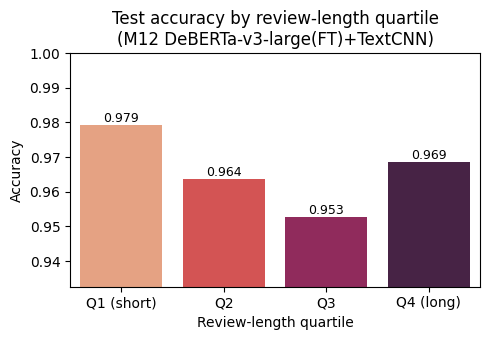

In [ ]:
errors = pd.DataFrame({
    "y_true": y_test,
    "y_prob": best_prob,
    "y_pred": (best_prob > 0.5).astype(int),
    "n_words": df_test["text_A"].str.split().str.len().values,
})
errors["correct"] = (errors.y_true == errors.y_pred).astype(int)
errors["len_bucket"] = pd.qcut(errors["n_words"], q=4,
                                labels=["Q1 (short)", "Q2", "Q3", "Q4 (long)"])
err_summary = errors.groupby("len_bucket", observed=True).agg(
    n=("correct", "size"), acc=("correct", "mean")).round(4)
print(err_summary)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=err_summary.reset_index(), x="len_bucket", y="acc",
            ax=ax, palette="rocket_r", hue="len_bucket", legend=False)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(err_summary["acc"].min() - 0.02, 1.0)
ax.set_title(f"Test accuracy by review-length quartile\n({best_name})")
ax.set_ylabel("Accuracy"); ax.set_xlabel("Review-length quartile")
plt.tight_layout(); plt.show()


In [ ]:
# Show 5 representative misclassifications for the report
mis_idx = errors[errors.correct == 0].index
sample_mis = df_test.iloc[mis_idx[:5]][["sentiment", "review"]].copy()
sample_mis["pred_prob"] = best_prob[mis_idx[:5]].round(3)
sample_mis["pred_label"] = (sample_mis["pred_prob"] > 0.5).astype(int)
sample_mis["review"] = sample_mis["review"].str.slice(0, 220) + "..."
sample_mis


,sentiment,review,pred_prob,pred_label
26,0,"""Jeez, only in the 70's... Antonio Margheriti ...",0.995,1
35,0,"""Cradle of Fear<br /><br />This isn't a movie ...",0.997,1
45,1,"""Yet another remake of \""Fistful of Dollars\"",...",0.010,0
78,0,"""This is a great idea for a film but it, unfor...",0.967,1
81,1,"""Standard rise to fame tale that has a few hig...",0.010,0


### Best model


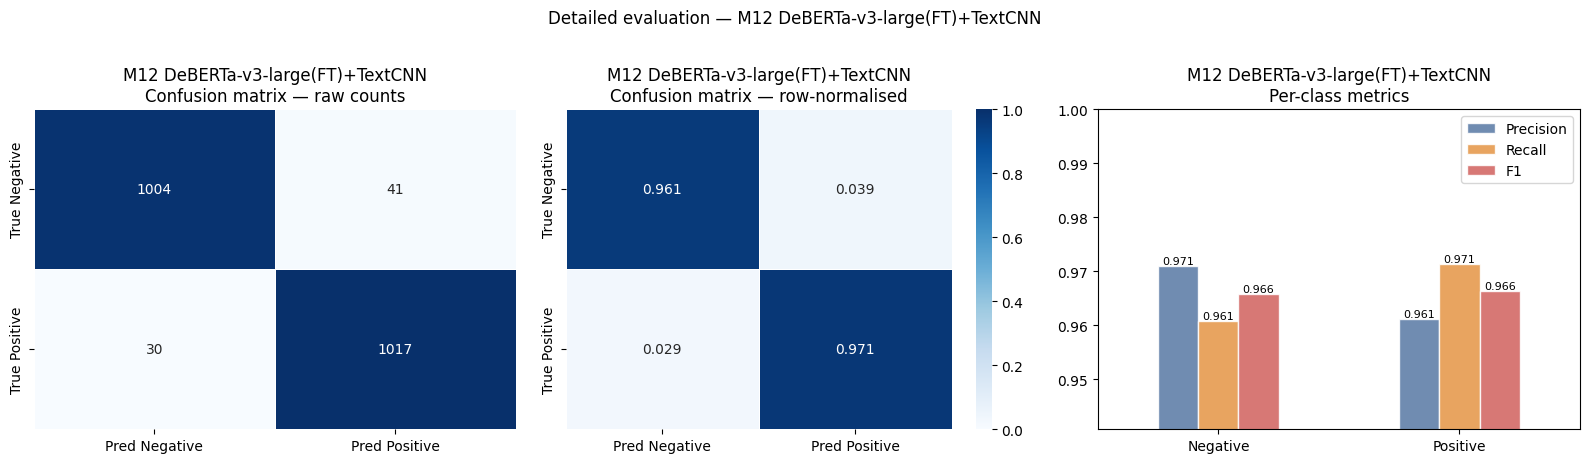


Classification report:
              precision    recall  f1-score   support

    Negative       0.97      0.96      0.97      1045
    Positive       0.96      0.97      0.97      1047

    accuracy                           0.97      2092
   macro avg       0.97      0.97      0.97      2092
weighted avg       0.97      0.97      0.97      2092



In [ ]:
from sklearn.metrics import classification_report

best_pred_binary = (best_prob > 0.5).astype(int)
cm_best = confusion_matrix(y_test, best_pred_binary)
cm_norm = cm_best.astype(float) / cm_best.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Negative", "Pred Positive"],
            yticklabels=["True Negative", "True Positive"],
            cbar=False, ax=axes[0], linewidths=0.5)
axes[0].set_title(f"{best_name}\nConfusion matrix — raw counts")


sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues",
            xticklabels=["Pred Negative", "Pred Positive"],
            yticklabels=["True Negative", "True Positive"],
            cbar=True, ax=axes[1], vmin=0, vmax=1, linewidths=0.5)
axes[1].set_title(f"{best_name}\nConfusion matrix — row-normalised")


cr = classification_report(y_test, best_pred_binary,
                            target_names=["Negative", "Positive"],
                            output_dict=True)
cr_df = pd.DataFrame(cr).T.loc[["Negative", "Positive"],
                                ["precision", "recall", "f1-score"]]
cr_df.plot(kind="bar", ax=axes[2], rot=0,
           color=["#5778a4", "#e49444", "#d1615d"],
           alpha=0.85, edgecolor="white")
axes[2].set_ylim(cr_df.values.min() - 0.02, 1.0)
axes[2].set_title(f"{best_name}\nPer-class metrics")
axes[2].set_xlabel("")
axes[2].legend(["Precision", "Recall", "F1"])
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.3f}",
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=8)

plt.suptitle(f"Detailed evaluation — {best_name}", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("fig_best_model_detail.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nClassification report:")
print(classification_report(y_test, best_pred_binary,
                             target_names=["Negative", "Positive"]))

###  Prediction plot 


### SHAP summary plots 



SHAP values computed for 1500 test reviews × 50000 features.


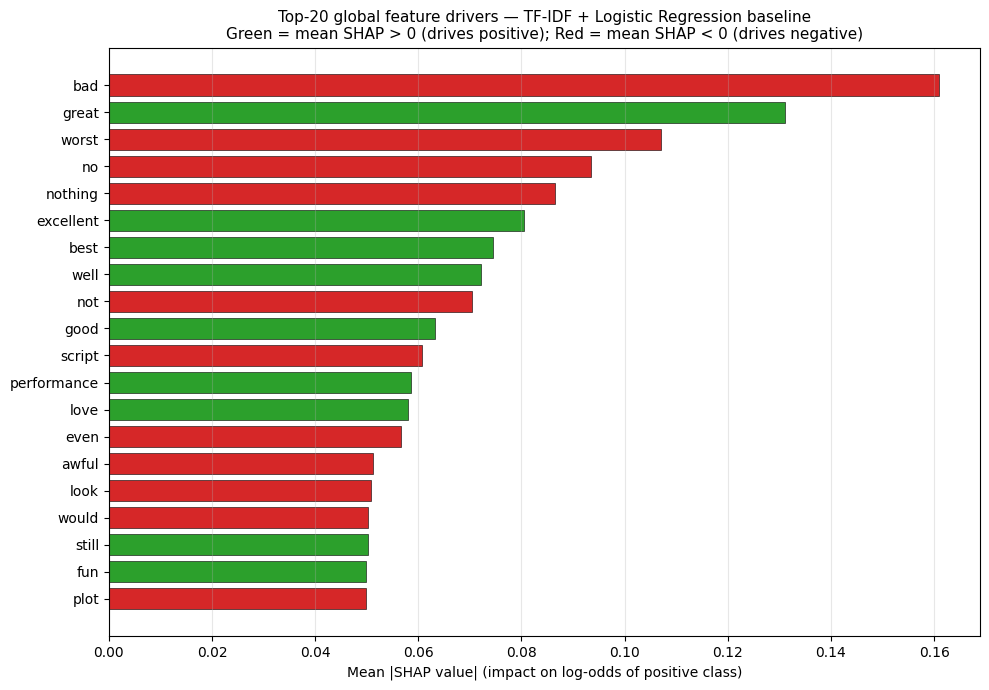

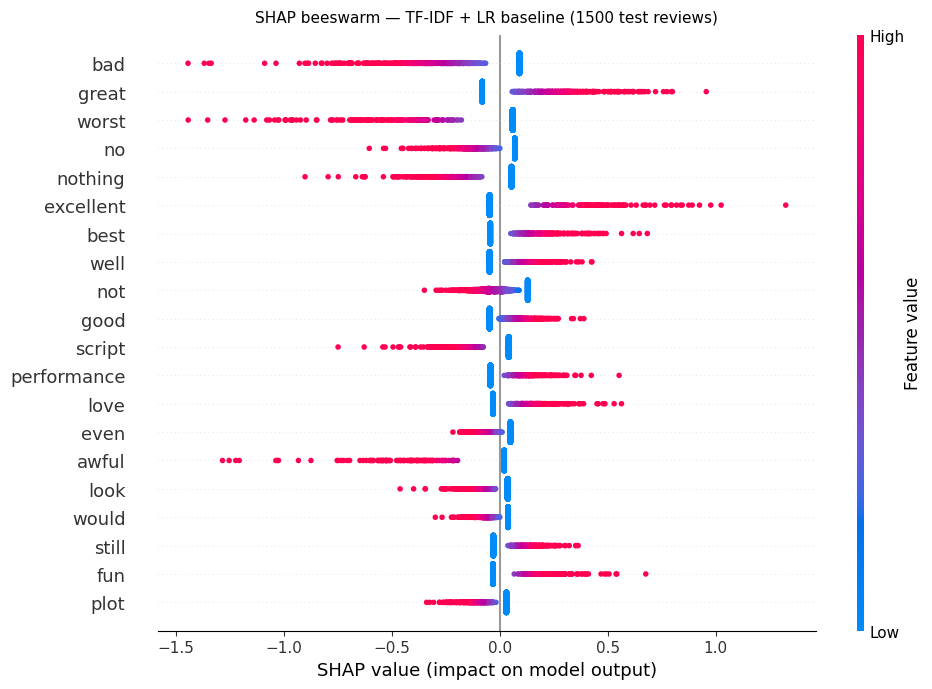


SHAP summary plot saved (Lundberg & Lee, 2017).


In [ ]:

try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "shap"],
                   check=True)
    import shap


X_train_tfidf = vec.transform(df_train["text_A"])
X_test_tfidf  = vec.transform(df_test ["text_A"])
feat_names    = vec.get_feature_names_out()


expl = shap.LinearExplainer(clf, X_train_tfidf,
                            feature_perturbation="interventional")
SHAP_N = 1500
rng = np.random.default_rng(STUDENT_ID)
idx = rng.choice(X_test_tfidf.shape[0], size=min(SHAP_N, X_test_tfidf.shape[0]),
                 replace=False)
shap_values = expl.shap_values(X_test_tfidf[idx])
X_shap_dense = X_test_tfidf[idx].toarray()
print(f"SHAP values computed for {len(idx)} test reviews × {len(feat_names)} features.")


mean_abs = np.abs(shap_values).mean(axis=0)
top20_idx = np.argsort(mean_abs)[-20:]


fig, ax = plt.subplots(figsize=(10, 7))
bar_colors = ["#2ca02c" if (shap_values[:, i] * (X_shap_dense[:, i] > 0)).mean() > 0
              else "#d62728" for i in top20_idx]
ax.barh([feat_names[i] for i in top20_idx],
        mean_abs[top20_idx], color=bar_colors, edgecolor="black", linewidth=0.4)
ax.set_xlabel("Mean |SHAP value| (impact on log-odds of positive class)")
ax.set_title("Top-20 global feature drivers — TF-IDF + Logistic Regression baseline\n"
             "Green = mean SHAP > 0 (drives positive); Red = mean SHAP < 0 (drives negative)",
             fontsize=11)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()


fig = plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap_dense, feature_names=feat_names,
                  max_display=20, show=False, plot_size=None)
plt.title("SHAP beeswarm — TF-IDF + LR baseline (1500 test reviews)",
          fontsize=11, pad=10)
plt.tight_layout(); plt.show()
print("\nSHAP summary plot saved (Lundberg & Lee, 2017).")


In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))


def _predict_val_for_best(best_name):
    """Generate validation predictions for the named best model."""

    if best_name == "Baseline TF-IDF + LR":
        return clf.predict_proba(vec.transform(df_val["text_A"]))[:, 1]

    if best_name == "M5 DistilBERT-FT (head+tail)":
        clf_model.eval(); out_p = []
        with torch.no_grad():
            for ids, mask, _ in va_l_c:
                ids = ids.to(DEVICE); mask = mask.to(DEVICE)
                logits = clf_model(input_ids=ids, attention_mask=mask).logits
                out_p.append(torch.softmax(logits, -1)[:, 1].cpu().numpy())
        return np.concatenate(out_p)

    ft_lookup = {
        "M3 DistilBERT(FT)+BiLSTM-Attn":           ("res3", ds_va_b),
        "M4 DistilBERT(FT)+TextCNN":               ("res4", ds_va_b),
        "M7 DistilBERT(FT)+xLSTM":                  ("res7", ds_va_b),
        "M11 DeBERTa-v3-large(FT)+BiLSTM-Attn":    ("res11", ds_va_d),
        "M12 DeBERTa-v3-large(FT)+TextCNN":        ("res12", ds_va_d),
        "M13 DeBERTa-v3-large(FT)+xLSTM":          ("res13", ds_va_d),
    }
    if best_name in ft_lookup:
        res_var, ds_va_obj = ft_lookup[best_name]
        res = globals().get(res_var, {})
        if "model" not in res:
            raise RuntimeError(f"Cannot recompute val preds for {best_name}: "
                               f"model was freed after training. "
                               f"Use val_preds[name] from the ensemble cell.")
        model = res["model"]; model.to(DEVICE).eval()
        loader = DataLoader(ds_va_obj, batch_size=8, shuffle=False)
        out_p = []
        from torch.cuda.amp import autocast
        with torch.no_grad():
            for ids, mask, _ in loader:
                ids, mask = ids.to(DEVICE), mask.to(DEVICE)
                with autocast(dtype=torch.bfloat16):
                    logits = model(ids, mask).squeeze(-1)
                out_p.append(torch.sigmoid(logits.float()).cpu().numpy())
        return np.concatenate(out_p)

    model_lookup = {
        "M1 GloVe+BiLSTM-Attn":      m1,
        "M2 GloVe+TextCNN":          m2,
        "M6 GloVe+xLSTM":             m6,
        "M8 fastText+BiLSTM-Attn":   m8,
        "M9 fastText+TextCNN":       m9,
        "M10 fastText+xLSTM":         m10,
    }
    if best_name in model_lookup:
        model = model_lookup[best_name]; model.eval()
        out_p = []
        _, va_l, _ = make_loaders(ds_tr, ds_va, ds_te, batch_size=64)
        with torch.no_grad():
            for x, _ in va_l:
                x = x.to(DEVICE)
                logits = model(x).squeeze(-1)
                out_p.append(torch.sigmoid(logits).cpu().numpy())
        return np.concatenate(out_p)
    raise ValueError(f"No val-prediction handler for: {best_name}")

try:

    if "val_preds" in globals() and best_name in val_preds:
        val_prob_best = val_preds[best_name]
    else:
        val_prob_best = _predict_val_for_best(best_name)
    y_val = df_val["sentiment"].values
    val_thresholds = np.linspace(0.01, 0.99, 200)
    val_f1s = [f1_score(y_val, (val_prob_best >= t).astype(int), zero_division=0)
               for t in val_thresholds]
    best_f1_thresh = float(val_thresholds[int(np.argmax(val_f1s))])
    thresh_source = "validation set"
except Exception as _e:
    print(f"Val-threshold derivation failed ({_e}); falling back to default 0.5")
    best_f1_thresh = 0.5
    thresh_source = "default"


sorted_idx  = np.argsort(best_prob)
sorted_prob = best_prob[sorted_idx]
sorted_true = y_test[sorted_idx]
x_range     = np.arange(len(sorted_prob))

ax = axes[0, 0]
ax.scatter(x_range[sorted_true == 1], sorted_prob[sorted_true == 1],
           c="#2ca02c", s=3, alpha=0.4, label="True Positive")
ax.scatter(x_range[sorted_true == 0], sorted_prob[sorted_true == 0],
           c="#d62728", s=3, alpha=0.4, label="True Negative")
ax.axhline(0.5, ls="--", color="black", lw=1, label="Decision threshold (0.5)")
ax.set_xlabel("Test examples (sorted by predicted probability)")
ax.set_ylabel("P(positive)")
ax.set_title(f"{best_name}\nSorted prediction plot")
ax.legend(markerscale=4, fontsize=9)

ax = axes[0, 1]
pred_df = pd.DataFrame({"P(positive)": best_prob,
                         "True label": pd.Categorical(
                             y_test, categories=[0, 1]).rename_categories(
                             ["Negative (0)", "Positive (1)"])})
sns.stripplot(data=pred_df, x="True label", y="P(positive)",
              palette={"Negative (0)": "#d62728", "Positive (1)": "#2ca02c"},
              alpha=0.25, size=2.5, jitter=True, ax=ax)
sns.boxplot(data=pred_df, x="True label", y="P(positive)",
            palette={"Negative (0)": "#d62728", "Positive (1)": "#2ca02c"},
            width=0.3, fliersize=0, linewidth=1.2, ax=ax, boxprops=dict(alpha=0.5))
ax.axhline(0.5, ls="--", color="black", lw=1)
ax.set_title(f"{best_name}\nPredicted probability by true class")
ax.set_ylabel("P(positive)")

ax = axes[1, 0]
thresholds  = np.linspace(0.01, 0.99, 200)
accs, precs, recs, f1s = [], [], [], []
for t in thresholds:
    yp = (best_prob >= t).astype(int)
    accs.append(accuracy_score(y_test, yp))
    precs.append(precision_score(y_test, yp, zero_division=0))
    recs.append(recall_score(y_test, yp, zero_division=0))
    f1s.append(f1_score(y_test, yp, zero_division=0))

ax.plot(thresholds, accs,  lw=2, label="Accuracy",  color="#5778a4")
ax.plot(thresholds, precs, lw=2, label="Precision", color="#e49444")
ax.plot(thresholds, recs,  lw=2, label="Recall",    color="#d1615d")
ax.plot(thresholds, f1s,   lw=2, label="F1",        color="#6a9f58", ls="--")
ax.axvline(0.5, ls=":", color="black", lw=1, label="Default 0.5")
ax.axvline(best_f1_thresh, ls="--", color="#6a9f58", lw=1.4,
           label=f"F1-optimal on {thresh_source} = {best_f1_thresh:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title(f"{best_name}\nThreshold sensitivity (test set)")
ax.legend(fontsize=9); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = axes[1, 1]
n_words_test = df_test["text_A"].str.split().str.len().values
correct_mask  = ((best_prob >= 0.5).astype(int) == y_test)

ax.scatter(n_words_test[correct_mask],  best_prob[correct_mask],
           c="#2ca02c", s=5, alpha=0.3, label="Correct")
ax.scatter(n_words_test[~correct_mask], best_prob[~correct_mask],
           c="#d62728", s=10, alpha=0.6, label="Error", marker="x")
ax.axhline(0.5, ls="--", color="black", lw=1)
ax.set_xlabel("Review word count (Pipeline A tokens)")
ax.set_ylabel("P(positive)")
ax.set_title(f"{best_name}\nPrediction errors vs review length")
ax.legend(fontsize=9, markerscale=2)

plt.suptitle(f"Prediction plot — {best_name} on test set  (n = {len(y_test)})",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("fig_prediction_plot.png", dpi=150, bbox_inches="tight")
plt.show()

yp_default = (best_prob >= 0.5).astype(int)
yp_optim   = (best_prob >= best_f1_thresh).astype(int)
print(f"Threshold derived from: {thresh_source}")
print(f"Default 0.5 threshold — Acc={accuracy_score(y_test, yp_default):.4f}, "
      f"F1={f1_score(y_test, yp_default):.4f}")
print(f"Val-optimal {best_f1_thresh:.3f}    — Acc={accuracy_score(y_test, yp_optim):.4f}, "
      f"F1={f1_score(y_test, yp_optim):.4f}")
print("\n(Headline metrics in are reported at the default 0.5 threshold.)")


In [ ]:
eval_table_sorted = eval_table.sort_values("AUROC", ascending=False)
eval_table_sorted.to_csv("results_summary.csv")
eval_table_sorted


,Accuracy,AUROC,Precision,Recall,F1,Cohen κ,MCC,Brier,"TN, FP, FN, TP"
model,,,,,,,,,
M12 DeBERTa-v3-large(FT)+TextCNN,0.9661,0.9927,0.9612,0.9713,0.9663,0.9321,0.9322,0.0331,"(1004, 41, 30, 1017)"
M11 DeBERTa-v3-large(FT)+BiLSTM-Attn,0.9651,0.9926,0.9568,0.9742,0.9655,0.9302,0.9304,0.0330,"(999, 46, 27, 1020)"
M13 DeBERTa-v3-large(FT)+xLSTM,0.9618,0.9923,0.9456,0.9799,0.9625,0.9235,0.9241,0.0380,"(986, 59, 21, 1026)"
M14 Optimal-weight Ensemble (SLSQP),0.9637,0.9886,0.9550,0.9733,0.9640,0.9273,0.9275,0.0336,"(997, 48, 28, 1019)"
M7 DistilBERT(FT)+xLSTM,0.9417,0.9838,0.9384,0.9456,0.9420,0.8834,0.8834,0.0547,"(980, 65, 57, 990)"
M5 DistilBERT-FT (head+tail),0.9374,0.9835,0.9313,0.9446,0.9379,0.8748,0.8748,0.0527,"(972, 73, 58, 989)"
M4 DistilBERT(FT)+TextCNN,0.9302,0.9825,0.9026,0.9647,0.9326,0.8604,0.8625,0.0604,"(936, 109, 37, 1010)"
M3 DistilBERT(FT)+BiLSTM-Attn,0.9288,0.9798,0.9112,0.9503,0.9303,0.8575,0.8583,0.0586,"(948, 97, 52, 995)"
Baseline TF-IDF + LR,0.9097,0.9709,0.8994,0.9226,0.9109,0.8193,0.8196,0.0721,"(937, 108, 81, 966)"
